# Modelos con **cappeo** e impp_usa (1950–2023)

Complemento de las notebooks sin cappeo. Las cuatro variables (`impp_usa`, `E`, `ipc`, `pbird`) se acotan en los percentiles 5 y 95 (`df_ERPT_Arg_capped`), como en la versión con cappeo y commodities. Objetivo: comparar los resultados con y sin los valores extremos (hiperinflación).

- Modelos: TVAR y VLSTAR de 2 regímenes (p = 2 y 3) y TVAR de 3 regímenes (p = 2 y 3), todos gaussianos y en dos etapas.
- Archivos de salida con sufijo `_cap`. Los modelos guardados se distinguen de los sin cappeo automáticamente (el nombre del archivo depende de los datos).

In [56]:
source("preparar_dataframes.r")
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v36.R")

[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v5 cargado (ind_Student con identificación por no normalidad)
>>> erpt_historia v36 cargada (graficos_con_mediana: referencias por régimen con la mediana)


In [2]:
str(df_ERPT_Arg)

'data.frame':	295 obs. of  11 variables:
 $ año       : num  1950 1950 1950 1951 1951 ...
 $ trimestre : chr  "2ºTr" "3ºTr" "4ºTr" "1ºTr" ...
 $ ipc       : num  0.071 0.0485 0.0686 0.0228 0.1579 ...
 $ E         : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ Ebc       : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ pbird     : num  -0.0164 0.0377 -0.013 0.0271 0.0121 ...
 $ impp_usa  : num  0.0248 0.082 0.084 0.0861 0.0595 ...
 $ Psoja_USA : num  0.2095 -0.0487 -0.0457 0.2223 0.0164 ...
 $ Pmaíz_USA : num  0.1235 0.087 -0.0306 0.1233 0.0291 ...
 $ Ptrigo_USA: num  0.0583 -0.0464 -0.0068 0.0913 -0.0141 ...
 $ TOTfmi    : num  NA NA NA NA NA NA NA NA NA NA ...


## Cappeo en los percentiles 5 y 95

In [3]:
cap_vars <- c("impp_usa", "E", "ipc", "pbird")

sds_antes <- sapply(df_ERPT_Arg[, cap_vars], sd, na.rm = TRUE)

df_ERPT_Arg_capped <- df_ERPT_Arg
limites <- list()
for (v in cap_vars) {
  lo <- quantile(df_ERPT_Arg[[v]], 0.05, na.rm = TRUE)
  hi <- quantile(df_ERPT_Arg[[v]], 0.95, na.rm = TRUE)
  df_ERPT_Arg_capped[[v]] <- pmin(pmax(df_ERPT_Arg[[v]], lo), hi)
  limites[[v]] <- c(p5 = unname(lo), p95 = unname(hi),
                    trimestres_acotados = sum(df_ERPT_Arg[[v]] < lo | df_ERPT_Arg[[v]] > hi, na.rm = TRUE))
}

sds_despues <- sapply(df_ERPT_Arg_capped[, cap_vars], sd, na.rm = TRUE)
cat("SD antes:\n"); print(sds_antes)
cat("SD después de cappear:\n"); print(sds_despues)
cat("\nLímites (diferencias logarítmicas) y trimestres acotados:\n"); print(round(do.call(rbind, limites), 4))
cat("\nInflación trimestral máxima después del cappeo (%):",
    round(100 * (exp(max(df_ERPT_Arg_capped$ipc)) - 1), 1), "\n")

SD antes:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 
SD después de cappear:
  impp_usa          E        ipc      pbird 
0.01944584 0.15282085 0.12152850 0.02347437 

Límites (diferencias logarítmicas) y trimestres acotados:
              p5    p95 trimestres_acotados
impp_usa -0.0257 0.0512                  30
E        -0.0123 0.5111                  30
ipc      -0.0026 0.4431                  30
pbird    -0.0463 0.0428                  30

Inflación trimestral máxima después del cappeo (%): 55.8 


## Selección de rezagos (VAR lineal, datos con cappeo)

In [5]:
if (!requireNamespace("vars", quietly = TRUE)) install.packages("vars")
library(vars)

vars_modelo <- c("impp_usa", "E", "ipc", "pbird")
Y <- na.omit(df_ERPT_Arg_capped[, vars_modelo])
cat("Observaciones:", nrow(Y), "\n\n")

sel <- VARselect(Y, lag.max = 8, type = "const")
cat("Rezagos elegidos por cada criterio (SC = BIC):\n")
print(sel$selection)
cat("\nValores de los criterios (menor = mejor):\n")
print(round(sel$criteria, 4))

# Portmanteau ajustado de los residuos del VAR lineal, para cada p (orientativo).
# El test necesita más rezagos que el VAR: si no, queda NA.
p_port <- function(v, L) if (L > v$p) round(unname(serial.test(v, lags.pt = L, type = "PT.adjusted")$serial$p.value), 3) else NA
port_lineal <- do.call(rbind, lapply(1:8, function(p) {
  v <- VAR(Y, p = p, type = "const")
  data.frame(rezagos = p,
             p_autocorr_8  = p_port(v, 8), p_autocorr_12 = p_port(v, 12))
}))
cat("\nPortmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):\n")
print(port_lineal, row.names = FALSE)


Observaciones: 295 

Rezagos elegidos por cada criterio (SC = BIC):
AIC(n)  HQ(n)  SC(n) FPE(n) 
     1      1      1      1 

Valores de los criterios (menor = mejor):
              1        2        3        4        5        6        7        8
AIC(n) -26.6377 -26.5648 -26.5719 -26.5798 -26.5514 -26.5333 -26.4568 -26.4537
HQ(n)  -26.5355 -26.3808 -26.3061 -26.2323 -26.1221 -26.0223 -25.8640 -25.7791
SC(n)  -26.3826 -26.1058 -25.9088 -25.7127 -25.4803 -25.2582 -24.9777 -24.7706
FPE(n)   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000

Portmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):
 rezagos p_autocorr_8 p_autocorr_12
       1        0.000         0.000
       2        0.000         0.001
       3        0.002         0.023
       4        0.008         0.080
       5        0.003         0.047
       6        0.020         0.136
       7        0.000         0.046
       8           NA         0.178


## TVAR, 2 regímenes, p = 1 (el que eligen los criterios con cappeo)

Se cargó exitosamente modelos preguardados  threshold_tvar_1_2_500_00a51315fa55e1e10b218f6b2364dc17.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


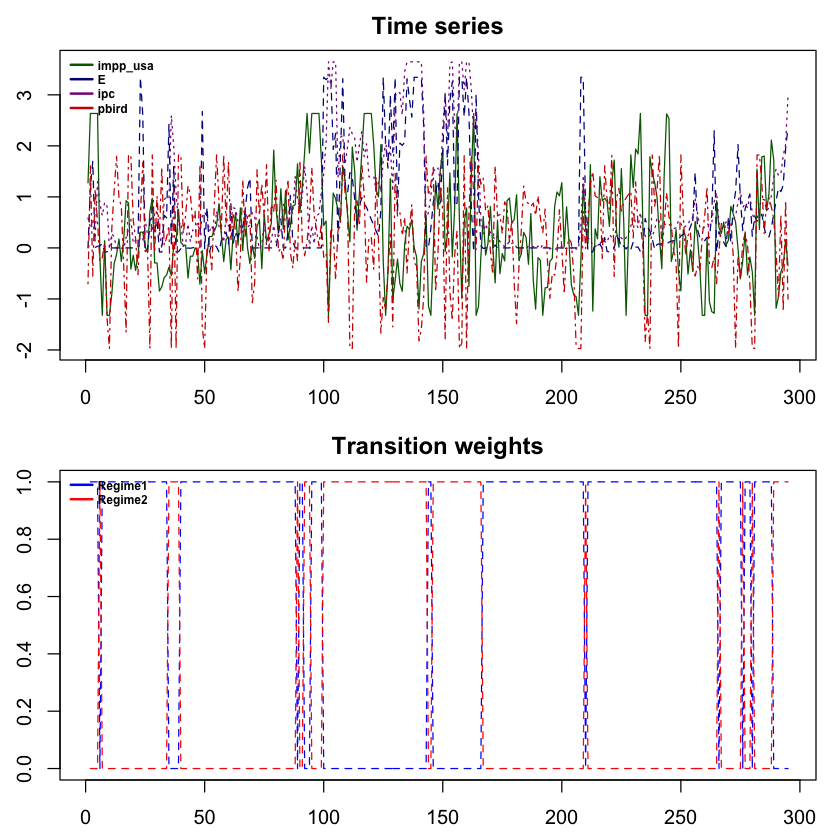

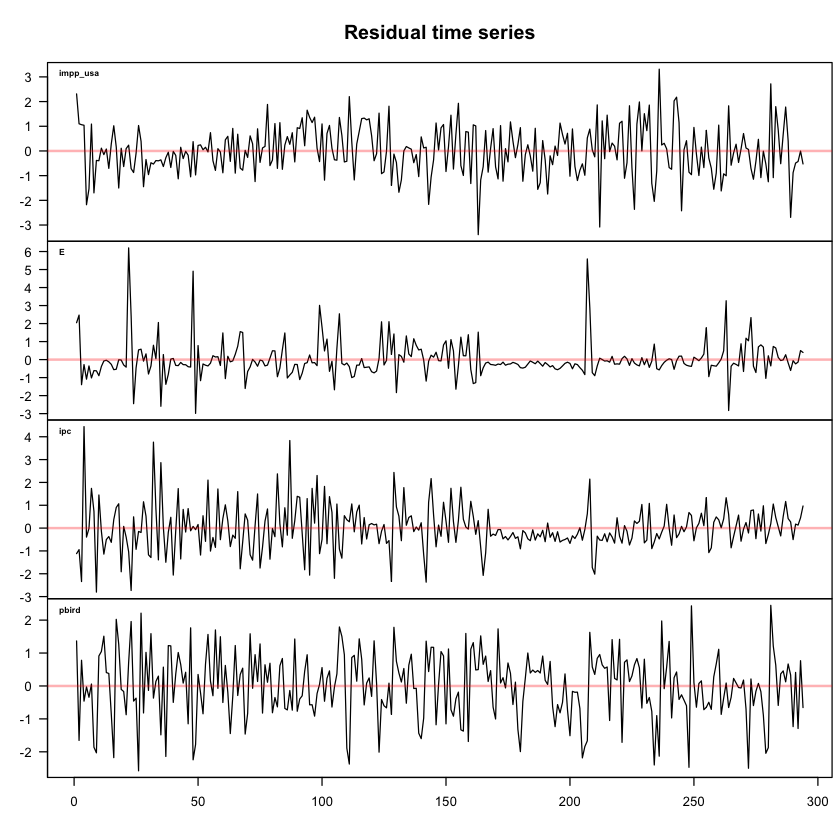

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



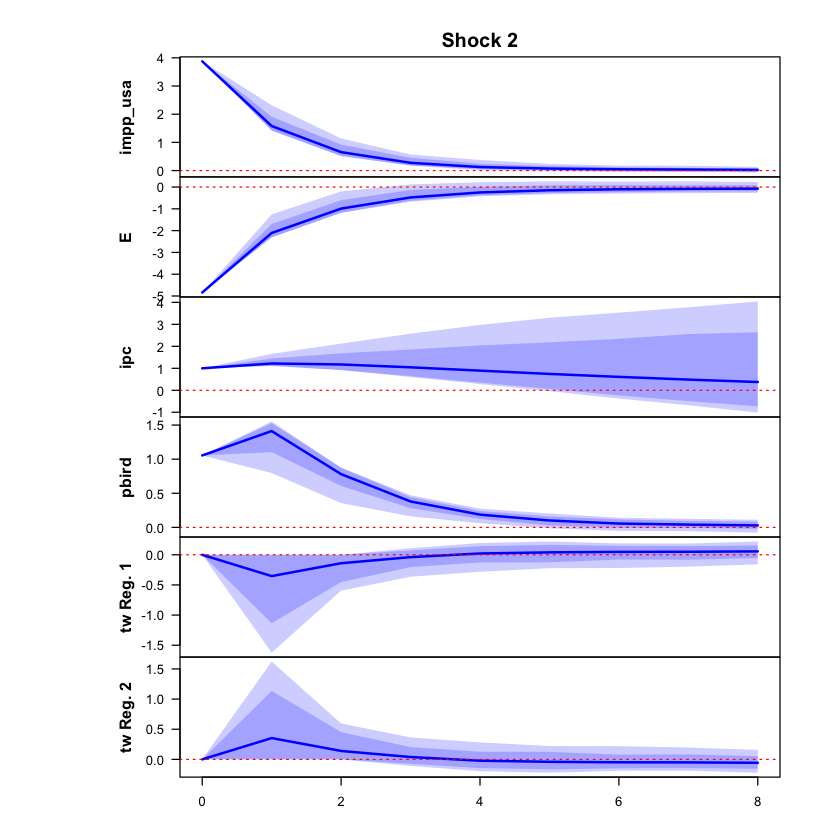

 >>> Linear IRF ( 1  shock units)


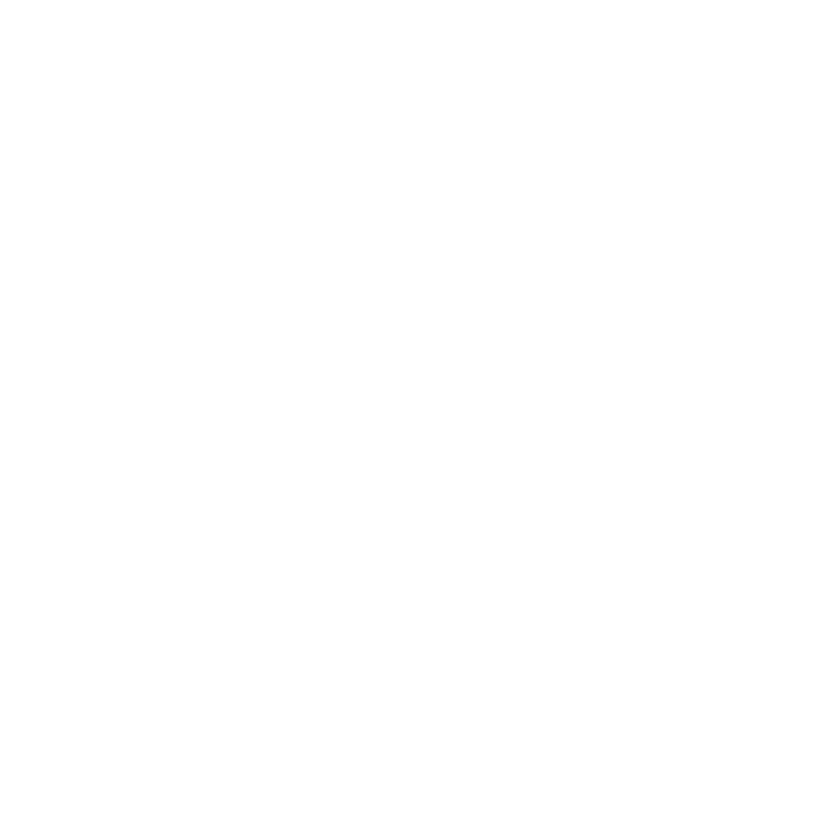

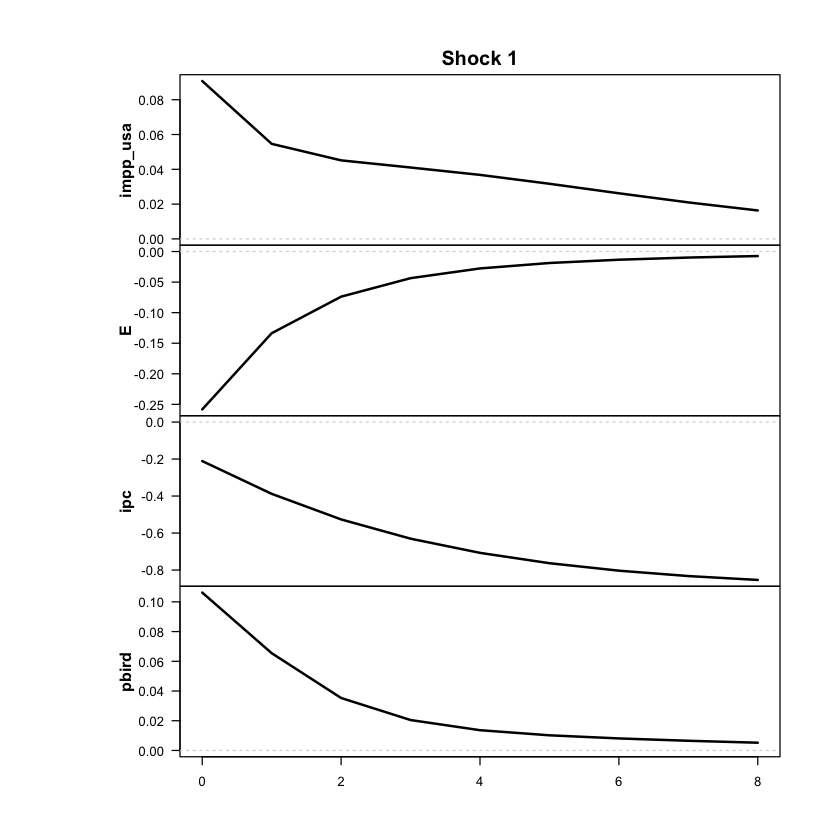

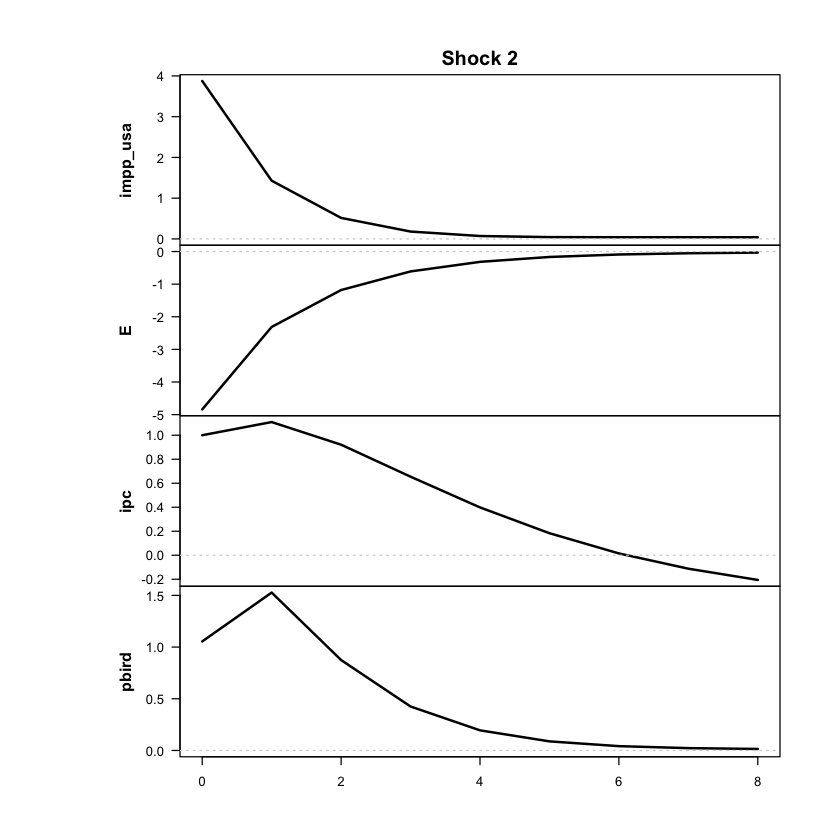

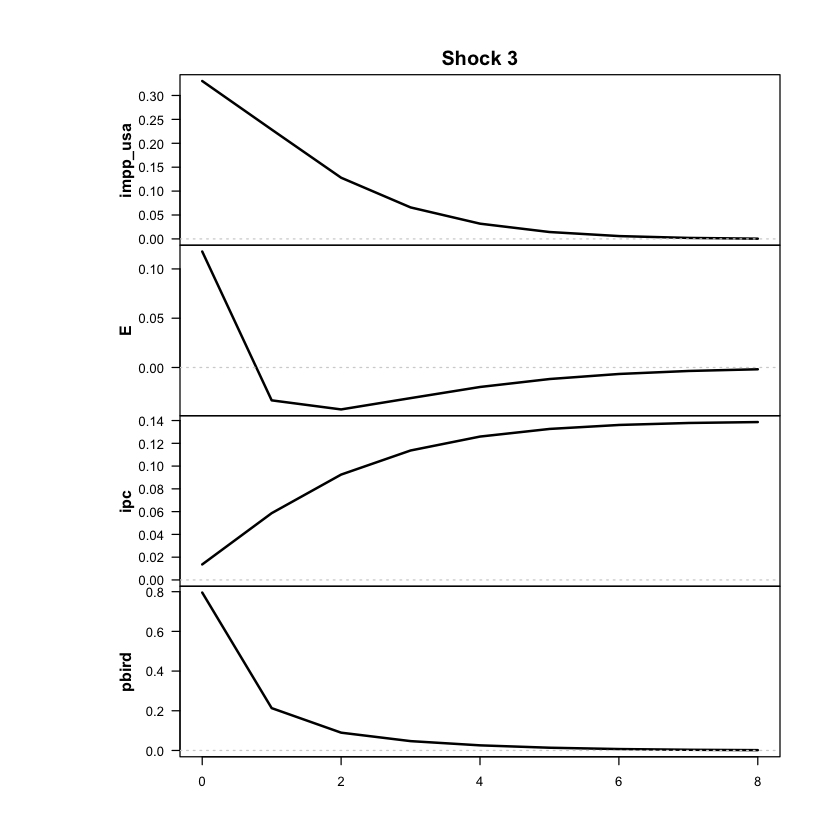

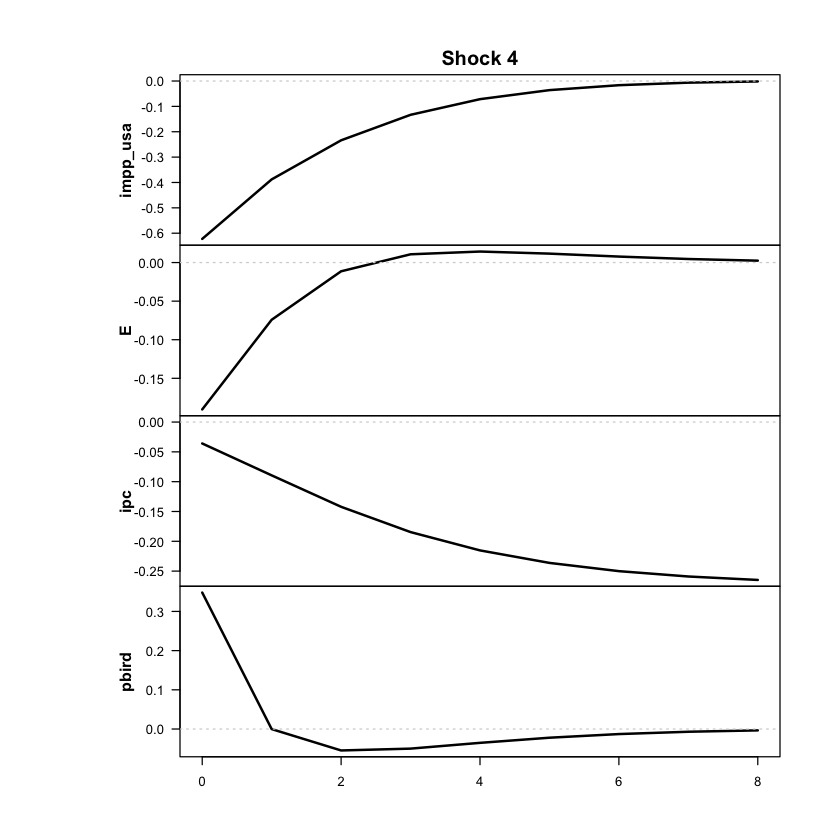

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



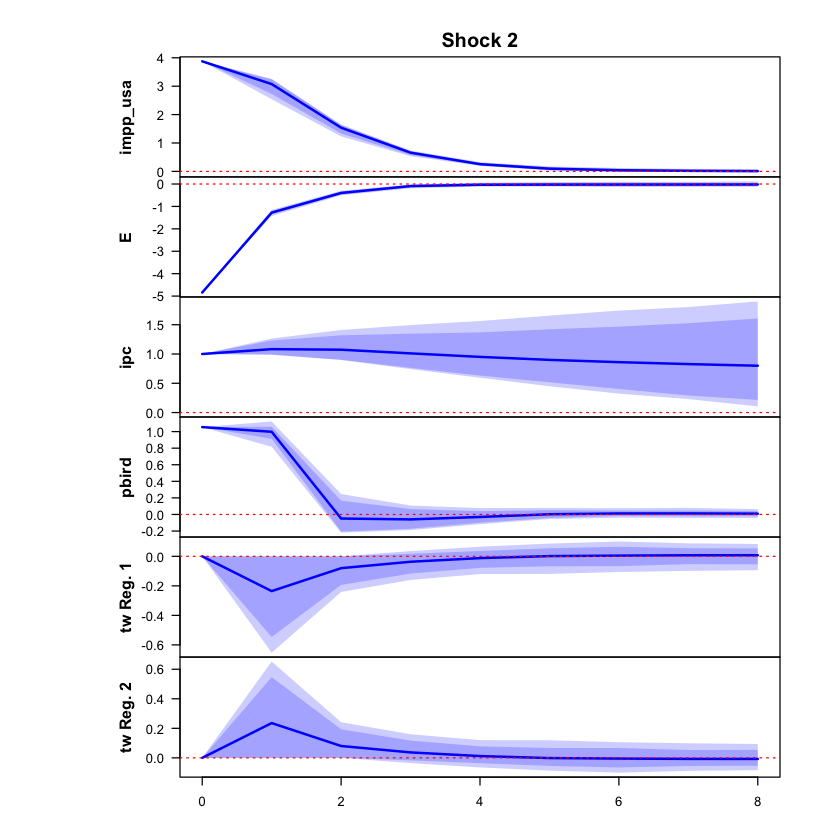

 >>> Linear IRF ( 1  shock units)


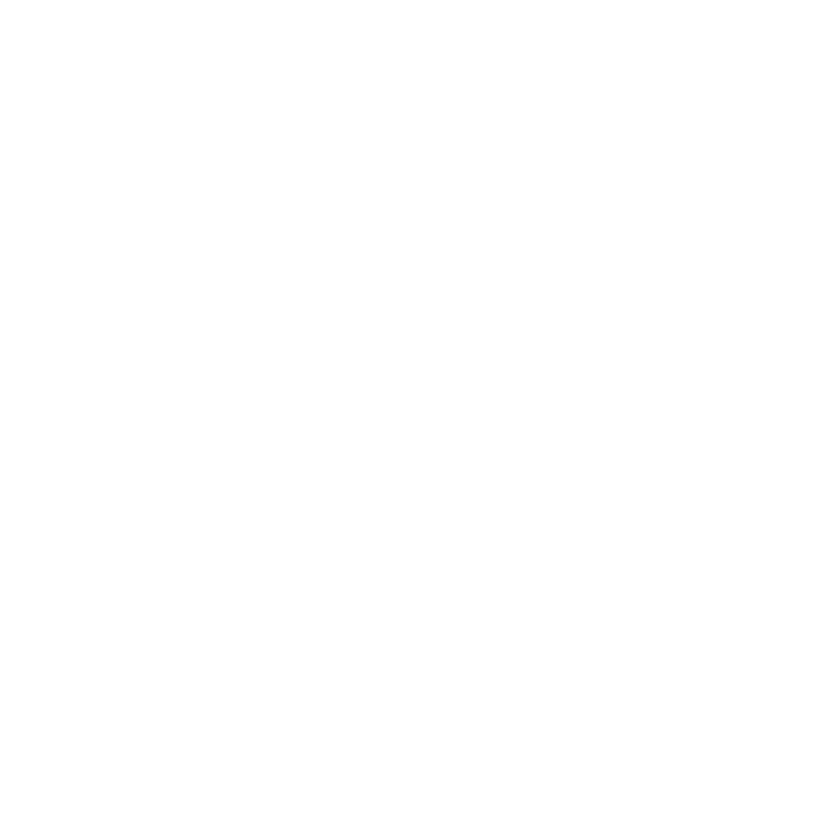

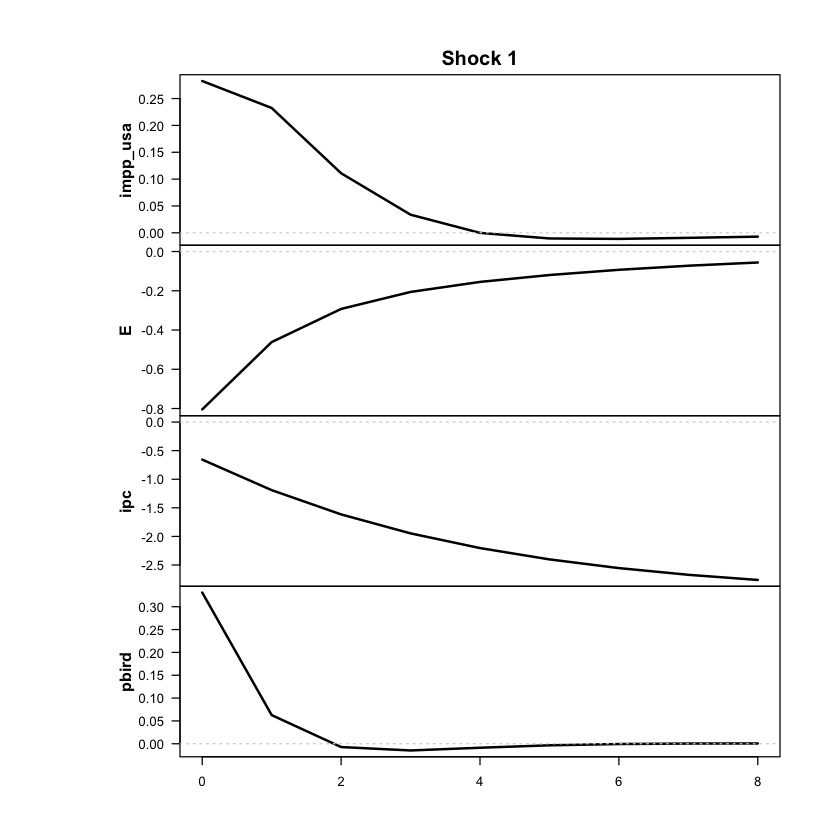

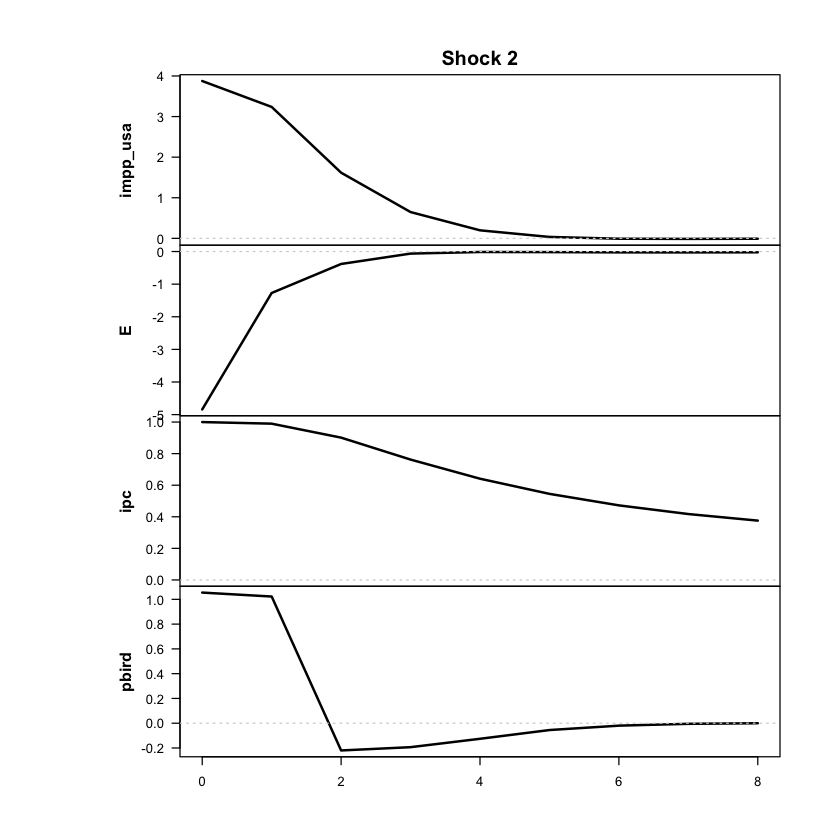

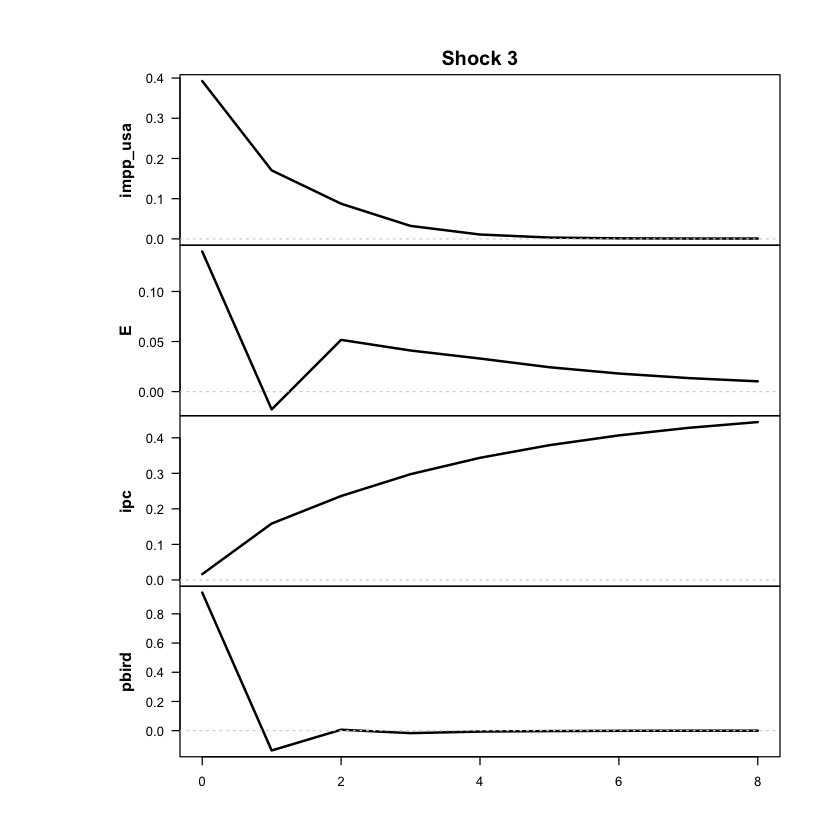

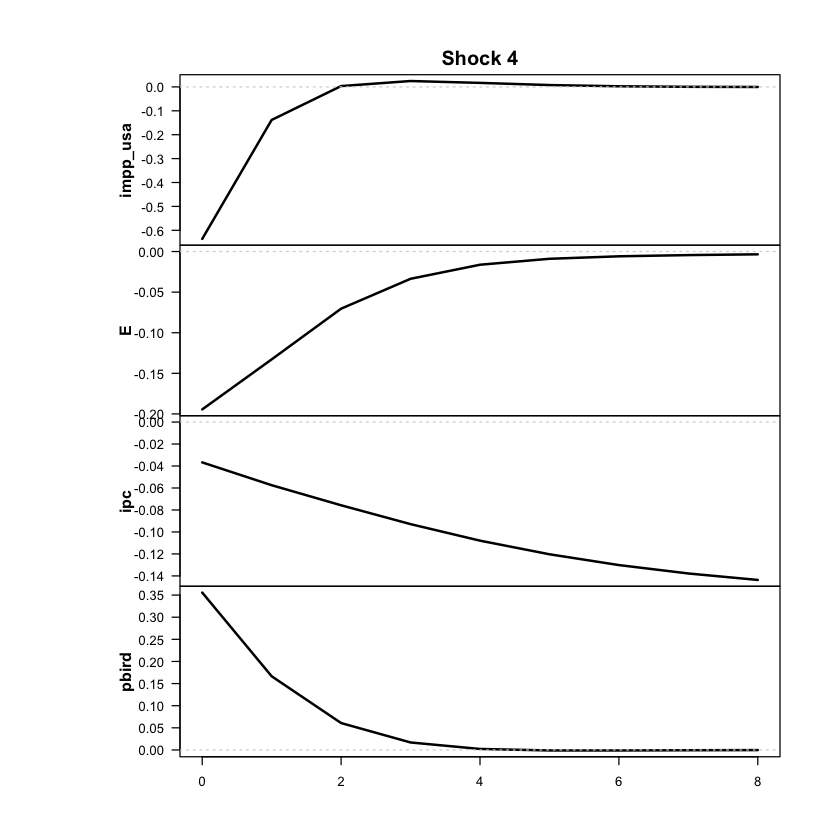

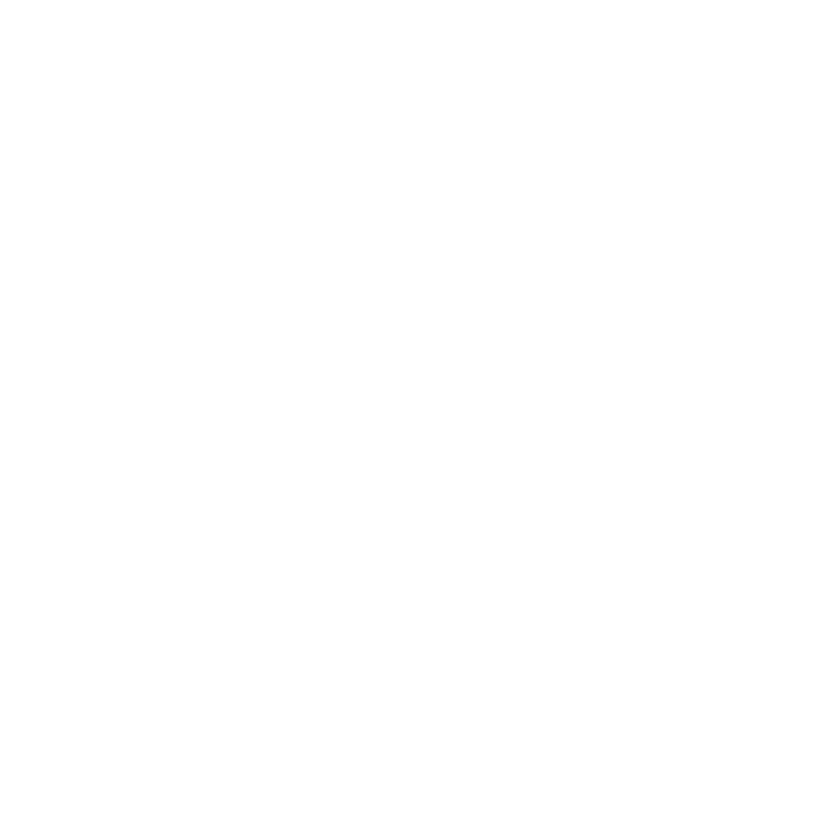

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [44]:
ic_tvar_p1_cap <- criterios_info(res, "TVAR p=1 cap")
print(ic_tvar_p1_cap)

        modelo regimenes parametros   loglik    AIC     HQ    BIC
1 TVAR p=1 cap         2         61 -1051.18 2224.4 2314.4 2449.1


In [8]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 2 | rezagos: 1 | errores: Gaussian 
Umbrales: 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 208 | régimen 2 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.59      1.02
E             4.03     27.25
ipc           4.77     29.68
pbird         0.84     -0.03


In [9]:
explorar_optimos(res, n = 10)

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest   loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -1051.18            12.5    NA         NA           208/86
 trim_reg_alto trim_transicion raiz_casi_unit cov_casi_singular descartar
            86               0          FALSE             FALSE     FALSE


In [10]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 61, #observations = 294 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.97 
Regime means: 0.29, 0.29, 0.47, 0.35

   Y     phi0          A1                              Omega                  
1 y1 = [ 0.15 ] + [  0.60  0.15 -0.18  0.02 ] y1.1 + [  0.60  0.02  0.03  0.08
2 y2   [ 0.19 ]   [ -0.06  0.42  0.05 -0.08 ] y2.1   [  0.02  0.26  0.03 -0.03
3 y3   [ 0.10 ]   [  0.01  0.14  0.69  0.02 ] y3.1   [  0.03  0.03  0.05 -0.02
4 y4   [ 0.25 ]   [  0.16 -0.13  0.03  0.22 ] y4.1   [  0.08 -0.03 -0.02  0.77
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means: 0.50, 1.48, 2.00, 0.00

   Y     phi0          A1                              Omega                  
1 y1 = [ 0.34 ] + [  0.35 -0.32  0.23  0.08 ] y1.1 + [  0.84 -0.30 -0.10  0.29
2 y2   [ 0.43 ]   [  0.04  0.33  0.27 -0.09 ] y2.1   [ -0.30  1.0

In [ ]:
shock_tvar_p1_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
shock_tvar_p1_cap

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0018 -0.0059  0.0064 -0.0121
  E        -0.0395  0.0583  0.0180 -0.0291
  ipc      -0.0256 -0.0096  0.0017 -0.0044
  pbird     0.0025 -0.0020  0.0187  0.0082

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.71    0.76    0.14    0.26 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.649  -0.164   0.092   0.150 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — tvar p1 cap

Correr solo si el modelo pasó el diagnóstico.

In [12]:
out_impp_usa_tvar_p1_cap <- erpt_historia(res, data = df_ERPT_Arg_capped,
                                          endog = c("impp_usa", "E", "ipc", "pbird"),
                                          shock_num = shock_tvar_p1_cap)

Estimando 294 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 208 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_bajo_original reg_alto_original
1         0           -0.1643           -0.1643
2         1           -0.1953           -0.1744
3         2           -0.1821           -0.1703
4         3           -0.1551           -0.1570
5         4           -0.1241           -0.1456
6         5           -0.0951           -0.1366
7         6           -0.0672           -0.1308
8         7           -0.0429           -0.1264
9         8           -0.0200           -0.1232


In [13]:
out_impp_usa_tvar_p1_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped,
                                               endog = c("impp_usa", "E", "ipc", "pbird"),
                                               shock_num = shock_tvar_p1_cap,
                                               definicion = "acumulado")

Estimando 294 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 208 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_bajo_original reg_alto_original
1         0           -0.1643           -0.1643
2         1           -0.1359           -0.1374
3         2           -0.1122           -0.1257
4         3           -0.0926           -0.1139
5         4           -0.0751           -0.1050
6         5           -0.0609           -0.0983
7         6           -0.0484           -0.0942
8         7           -0.0385           -0.0912
9         8           -0.0297           -0.0891


GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1643 -0.0335
         1 -0.2029 -0.0774
         2 -0.1983 -0.1018
         3 -0.1795 -0.1137
         4 -0.1570 -0.1195
         5 -0.1352 -0.1224
         6 -0.1150 -0.1243
         7 -0.0968 -0.1254
         8 -0.0802 -0.1262

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1643 -0.0335
         1 -0.1768 -0.0650
         2 -0.1742 -0.0631
         3 -0.1628 -0.0612
         4 -0.1520 -0.0602
         5 -0.1430 -0.0601
         6 -0.1360 -0.0605
         7 -0.1299 -0.0609
         8 -0.1243 -0.0612


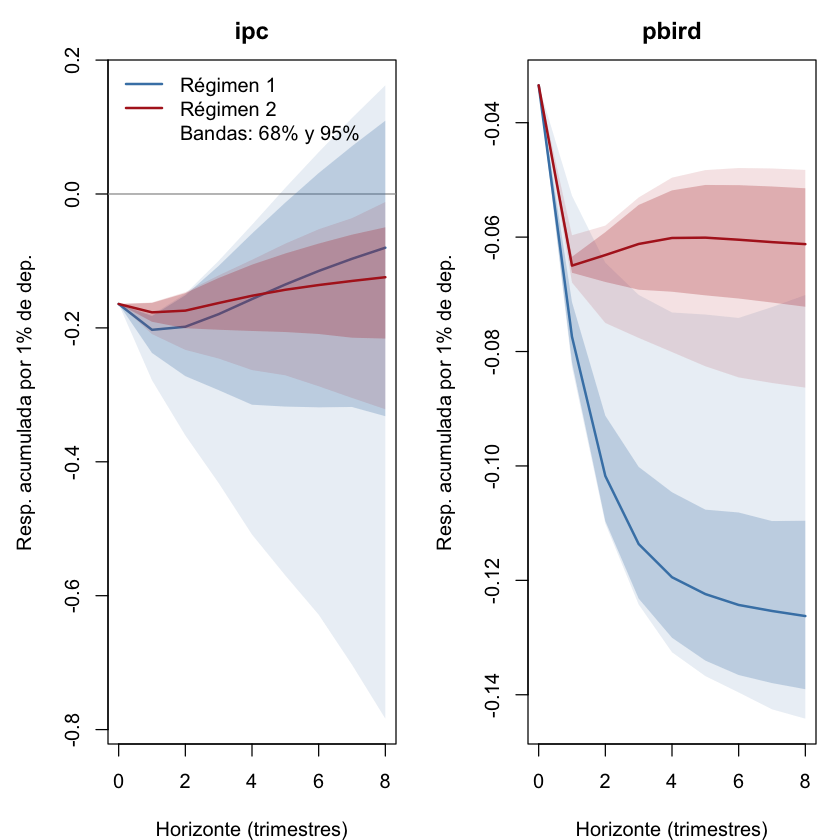

In [14]:
  graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                         shock_num = shock_tvar_p1_cap,
                         archivo = "girf_original_impp_usa_tvar_p1_cap")

## TVAR, 2 regímenes, p = 2 — especificación comparable con la principal

Se cargó exitosamente modelos preguardados  threshold_tvar_2_2_500_41ff5d0a290dc29150bb88c804aa7292.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


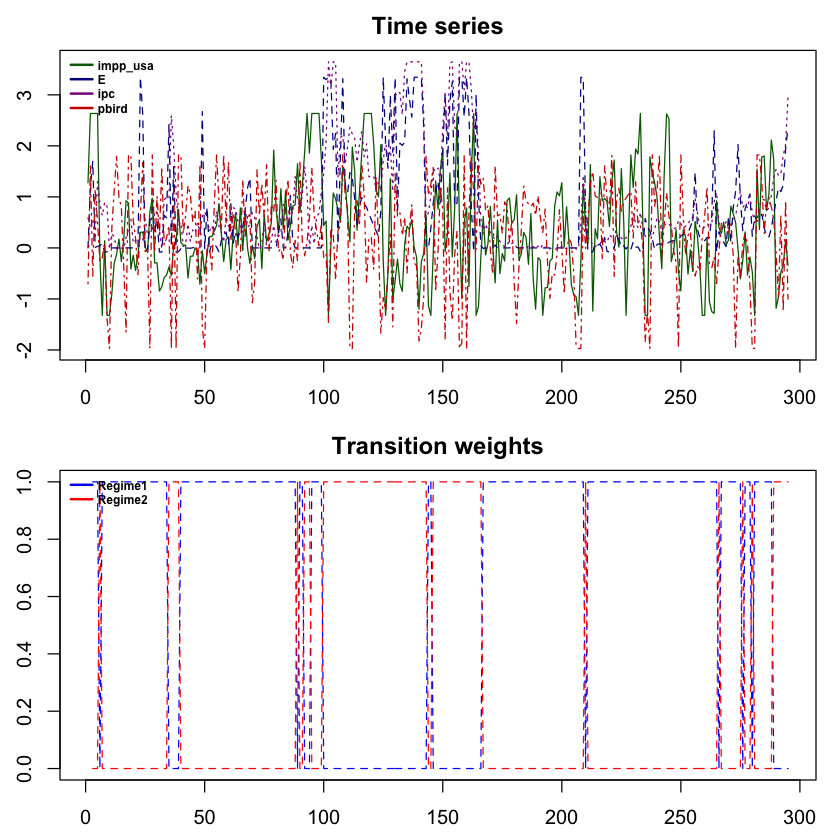

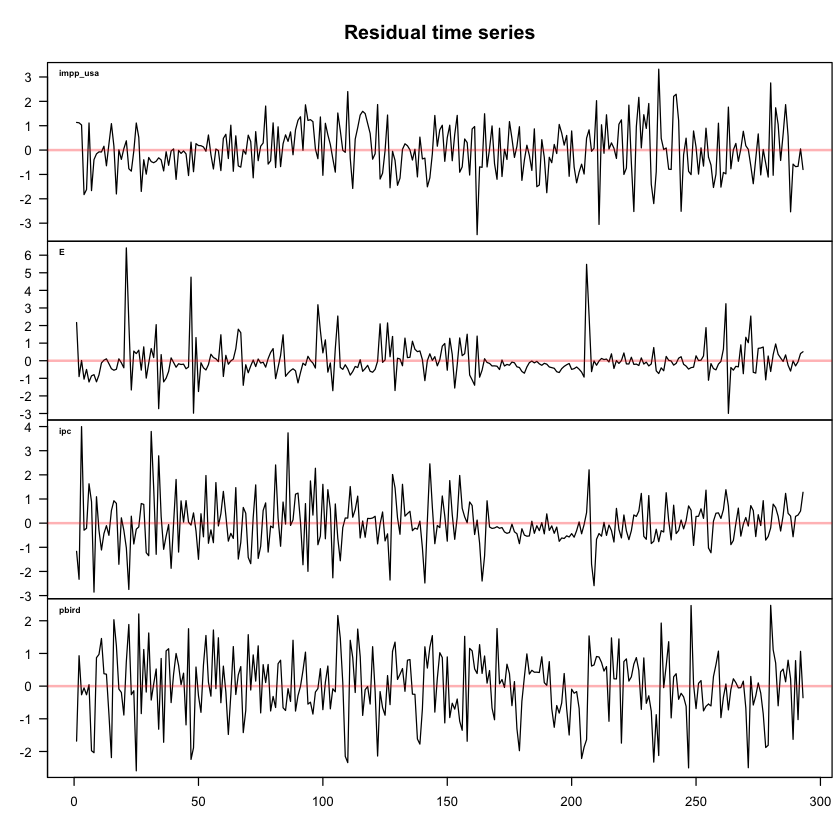

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



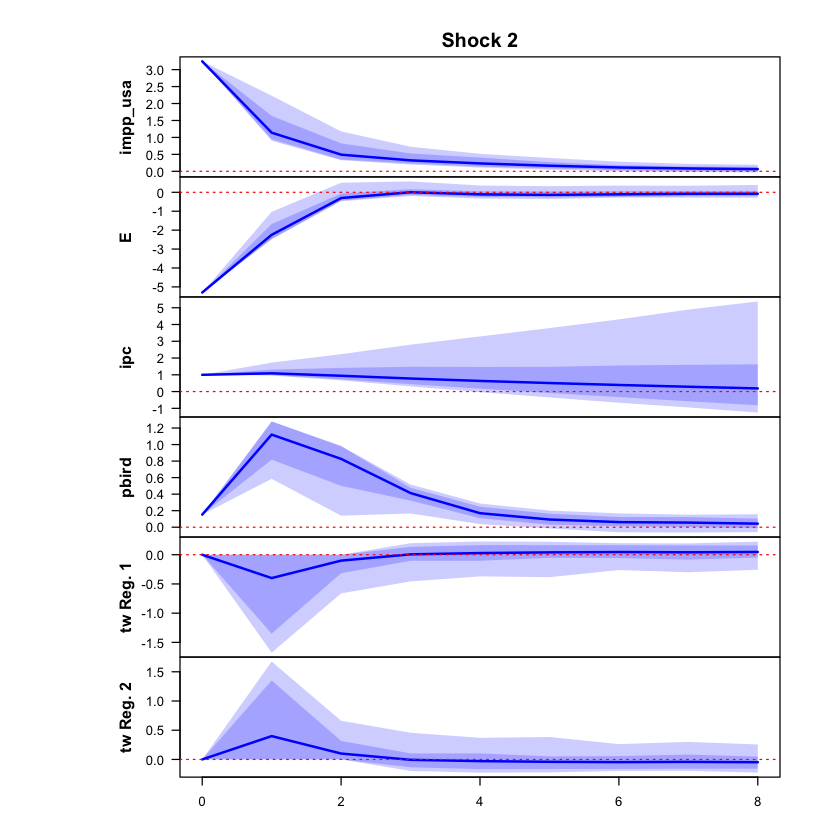

 >>> Linear IRF ( 1  shock units)


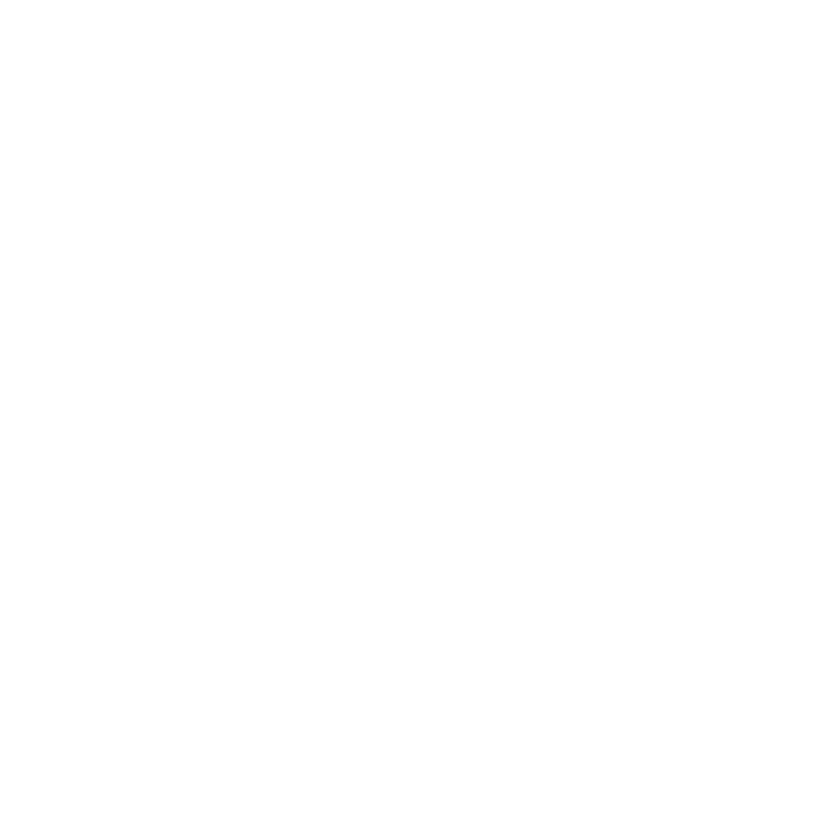

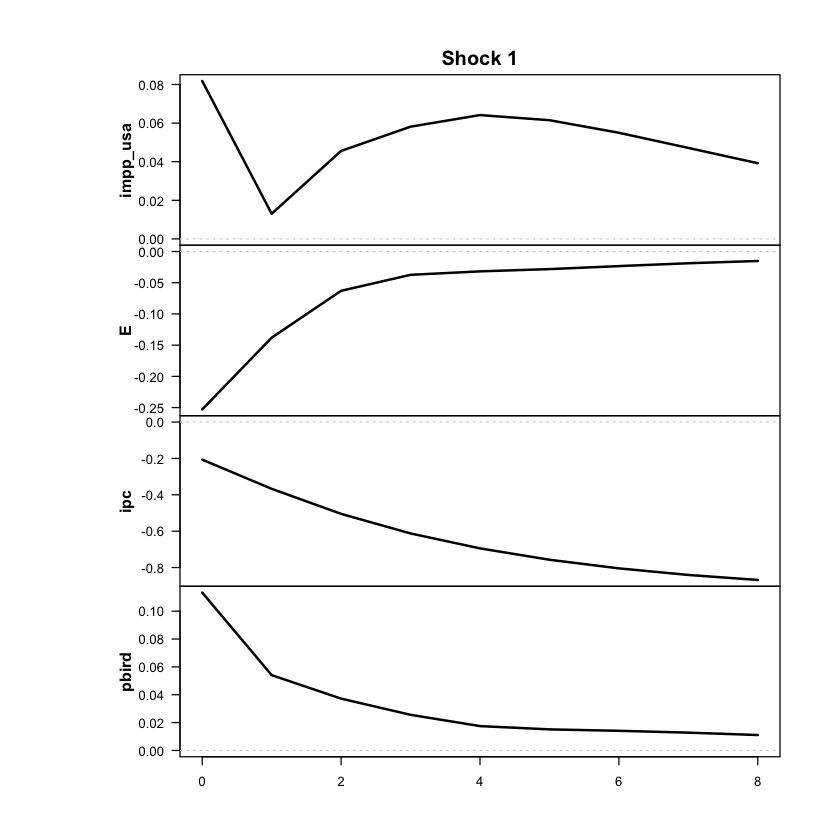

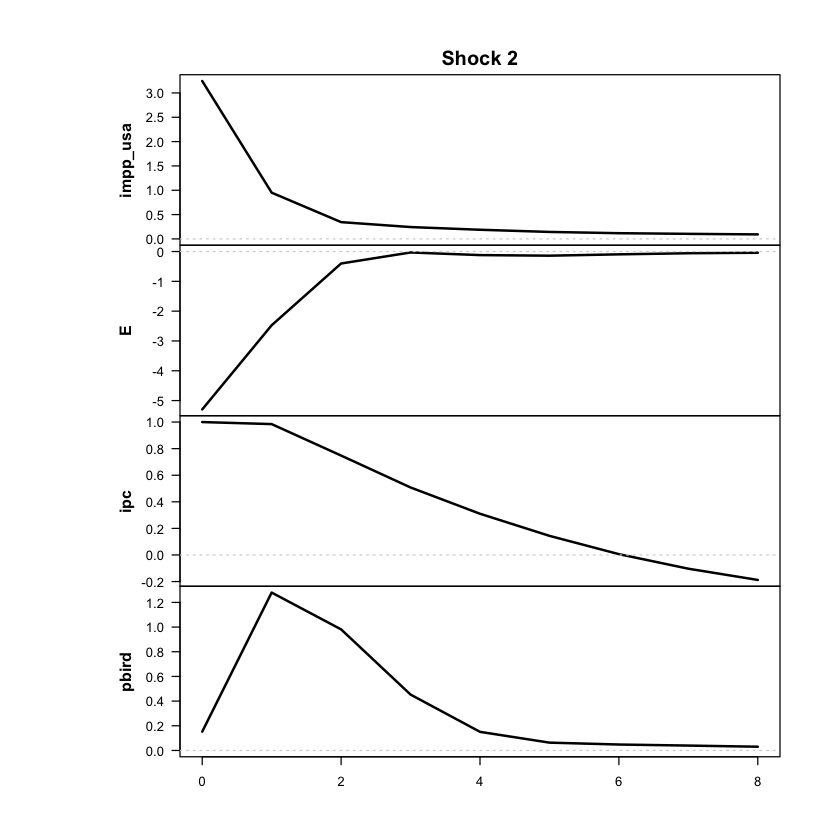

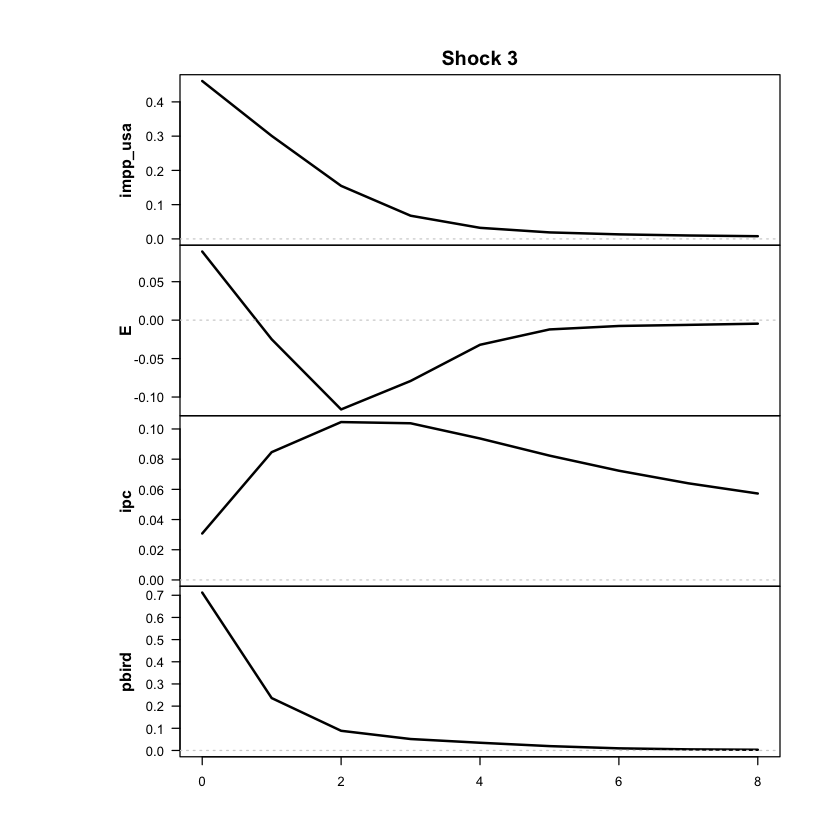

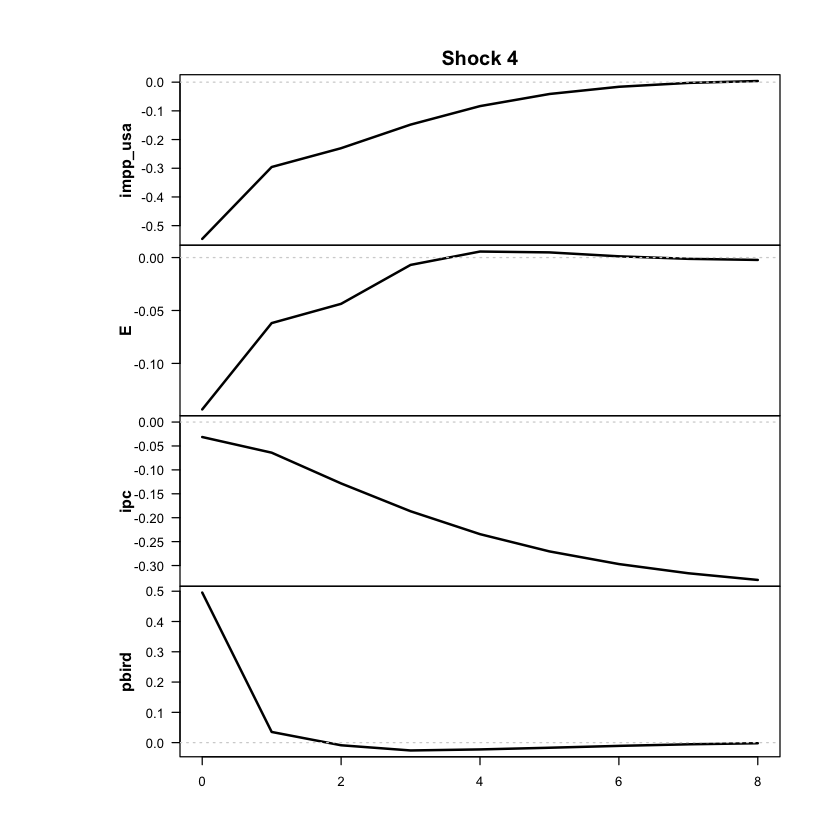

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



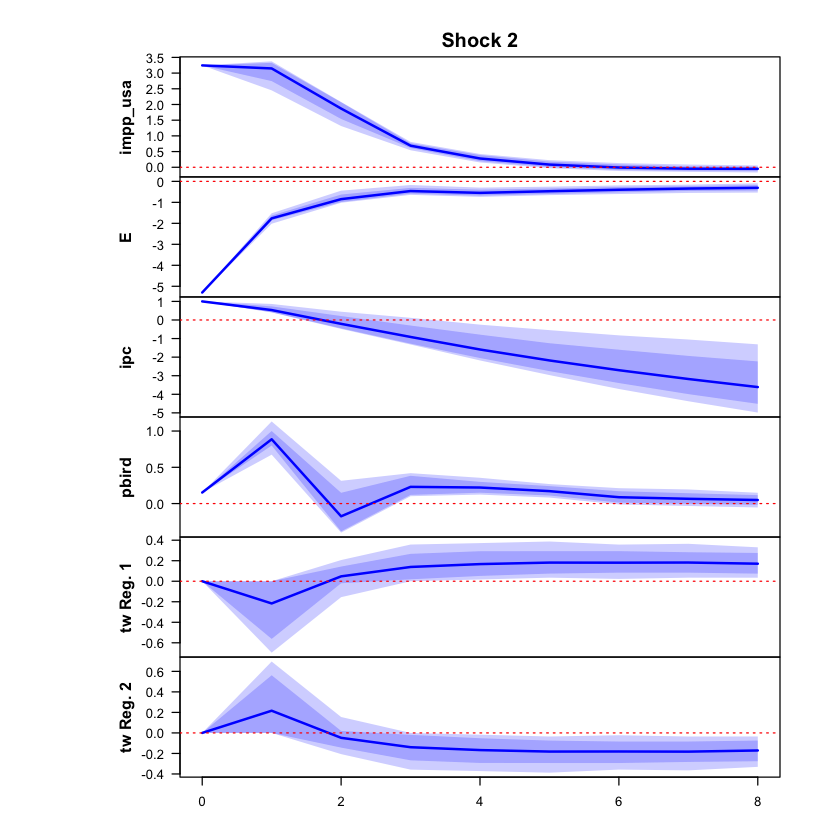

 >>> Linear IRF ( 1  shock units)


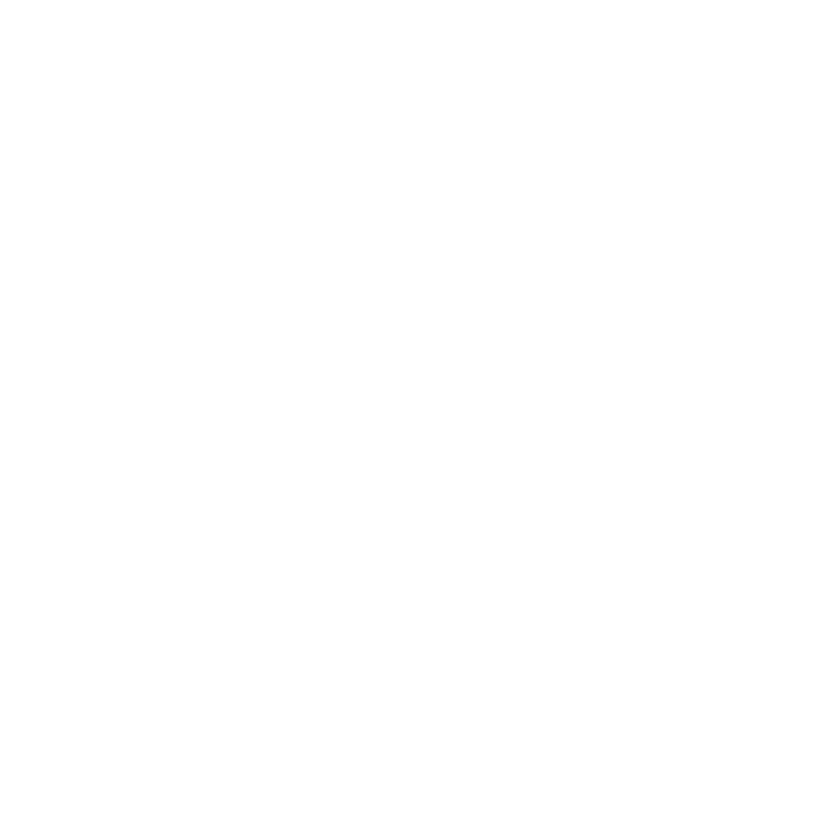

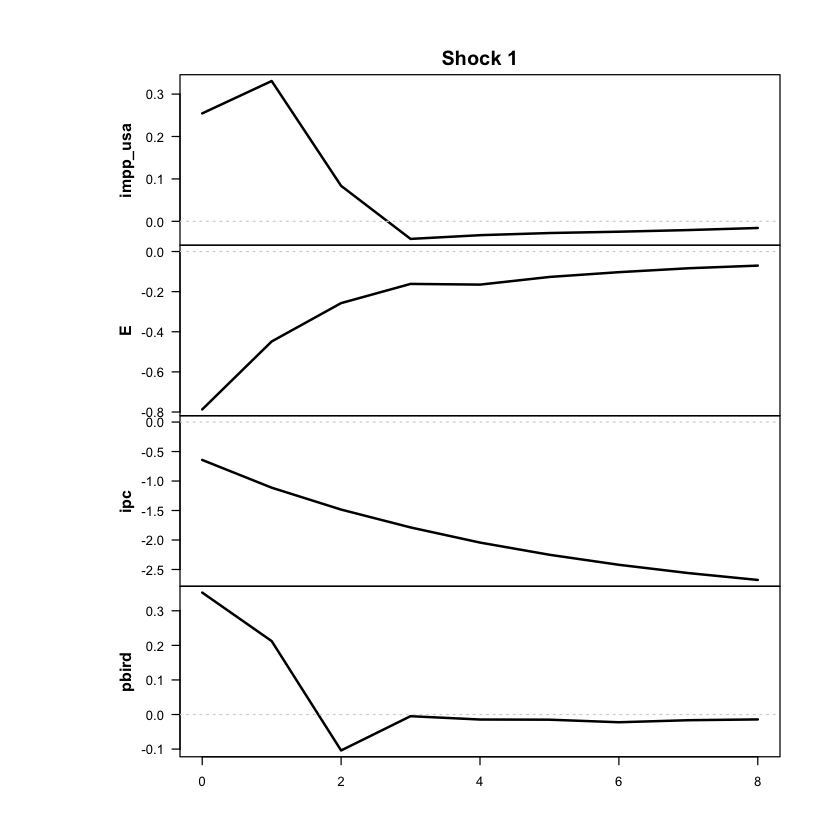

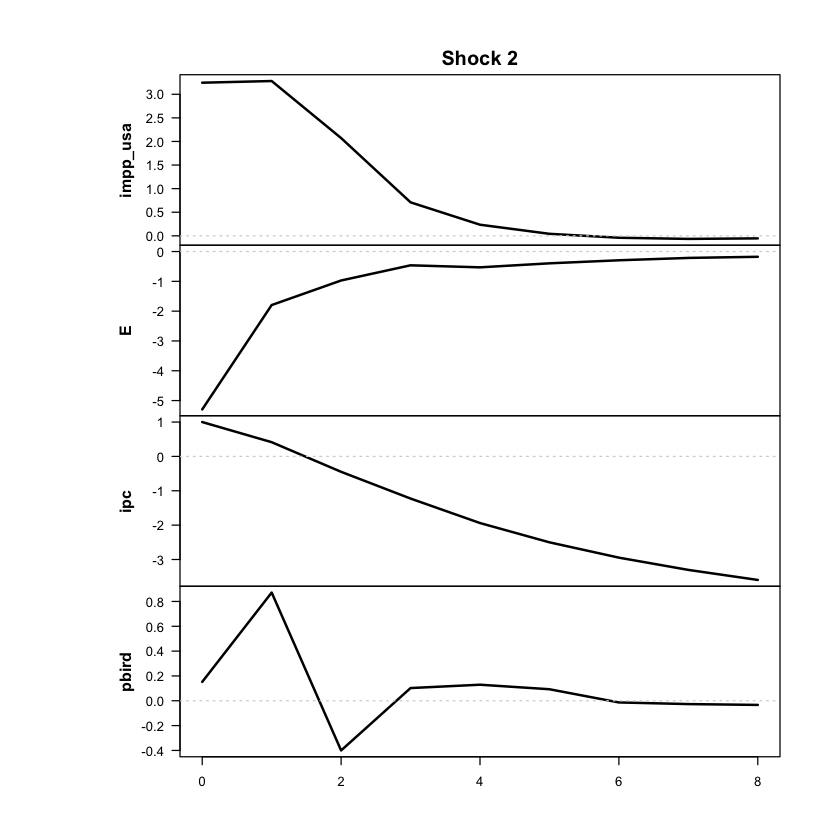

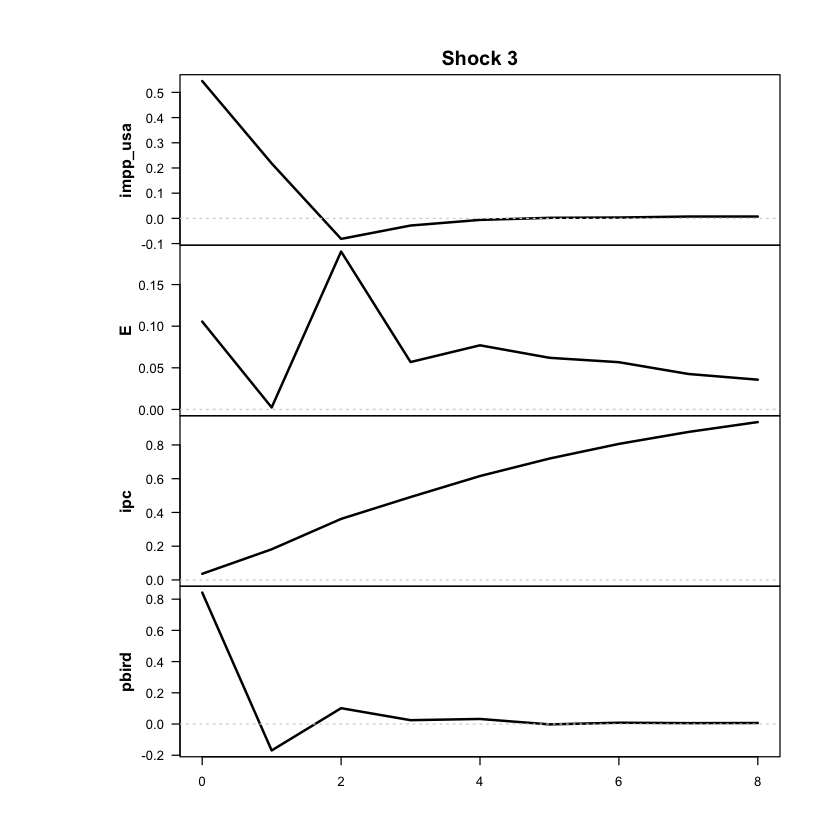

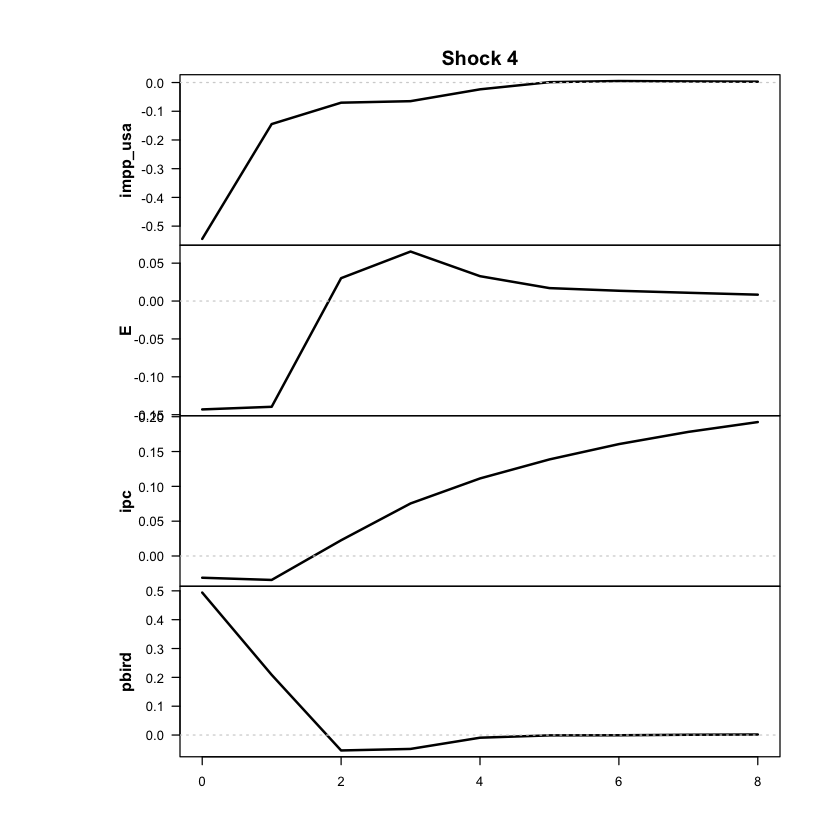

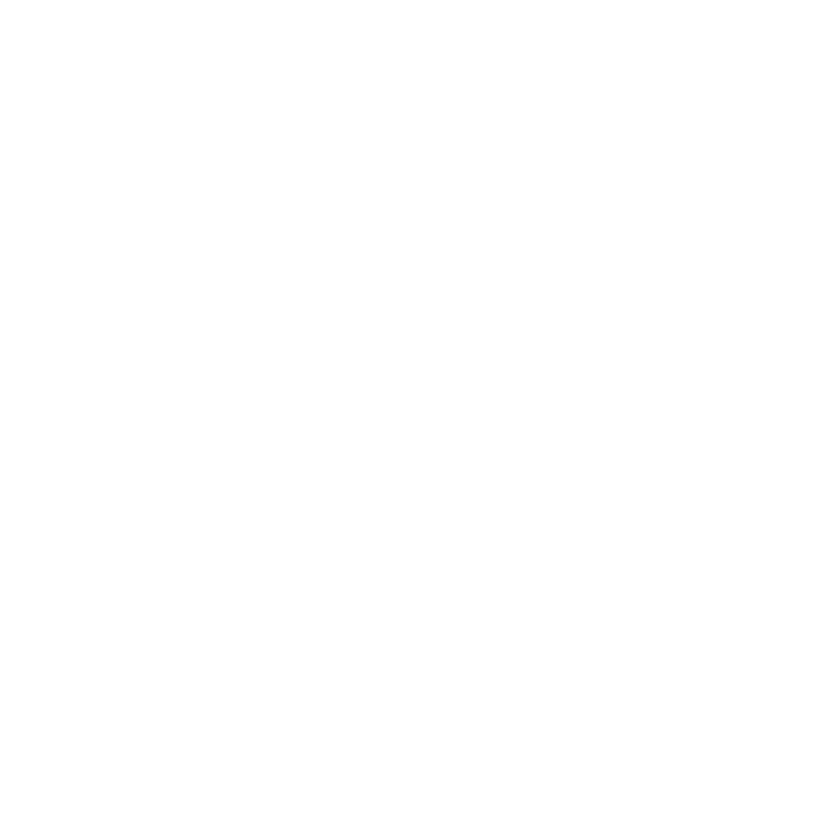

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [46]:
ic_tvar_p2_cap <- criterios_info(res, "TVAR p=2 cap")
print(ic_tvar_p2_cap)

        modelo regimenes parametros   loglik    AIC     HQ    BIC
1 TVAR p=2 cap         2         93 -1024.31 2234.6 2371.7 2576.9


In [17]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 2 | rezagos: 2 | errores: Gaussian 
Umbrales: 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 207 | régimen 2 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.57      1.02
E             3.96     27.25
ipc           4.77     29.68
pbird         0.82     -0.03


In [18]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest   loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -1024.31            12.5    NA         NA           207/86
 trim_reg_alto trim_transicion raiz_casi_unit cov_casi_singular descartar
            86               0          FALSE             FALSE     FALSE


In [19]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 93, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.97 
Regime means: 0.26, 0.28, 0.46, 0.34

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.18 ] + [  0.55  0.15 -0.01  0.05 ] y1.1 + [  0.08 -0.03 -0.24 -0.06
2 y2   [ 0.20 ]   [ -0.06  0.44  0.07 -0.06 ] y2.1   [  0.00 -0.15  0.06 -0.10
3 y3   [ 0.10 ]   [  0.01  0.13  0.64  0.02 ] y3.1   [  0.02  0.01  0.06 -0.04
4 y4   [ 0.25 ]   [  0.17 -0.12  0.07  0.23 ] y4.1   [ -0.04 -0.07 -0.02  0.00
             Omega                     1/2     
1 ] y1.2 + [  0.58  0.00  0.03  0.07 ]     eps1
2 ] y2.2   [  0.00  0.25  0.03 -0.04 ]     eps2
3 ] y3.2   [  0.03  0.03  0.05 -0.02 ]     eps3
4 ] y4.2   [  0.07 -0.04 -0.02  0.77 ]     eps4

Regime 2 
Regime means: 0.53, 1.48, 2.00, 0.01

   Y     phi0          A1                       

In [75]:
shock_tvar_p2_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar_p2_cap <- 2
shock_tvar_p2_cap

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0016 -0.0047  0.0090 -0.0106
  E        -0.0387  0.0600  0.0136 -0.0219
  ipc      -0.0251 -0.0090  0.0037 -0.0038
  pbird     0.0027 -0.0003  0.0167  0.0116

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.71    0.84    0.10    0.19 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.649  -0.150   0.274   0.173 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

### ERPT — tvar p2 cap

Correr solo si el modelo pasó el diagnóstico.

In [76]:
out_impp_usa_tvar_p2_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_p2_cap)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 6.2%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 207 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.1501           -0.1501
2         1           -0.1570           -0.0790
3         2           -0.1284            0.0314
4         3           -0.0979            0.1366
5         4           -0.0707            0.2380
6         5           -0.0444            0.3246
7         6           -0.0186            0.4019
8         7            0.0037            0.4710
9         8            0.0231            0.5364

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.1501          -0.1501
2         1          -0.1491          -0.0732
3         2          -0.1142           0.0433
4         3          -0.0780           0.1557
5         4        

In [77]:
out_impp_usa_tvar_p2_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_p2_cap,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 6.2%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...



Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 207 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.1501           -0.1501
2         1           -0.1098           -0.0590
3         2           -0.0869            0.0205
4         3           -0.0676            0.0854
5         4           -0.0498            0.1399
6         5           -0.0332            0.1818
7         6           -0.0177            0.2158
8         7           -0.0052            0.2444
9         8            0.0050            0.2697

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.1501          -0.1501
2         1          -0.1019          -0.0551
3         2          -0.0742           0.0279
4         3          -0.0503           0.0966
5         4        

Umbrales (inflación trimestral de t-1): 12.5% trimestral (60% anualizada) 
Trimestres por régimen: régimen 1 = 207 | régimen 2 = 86 


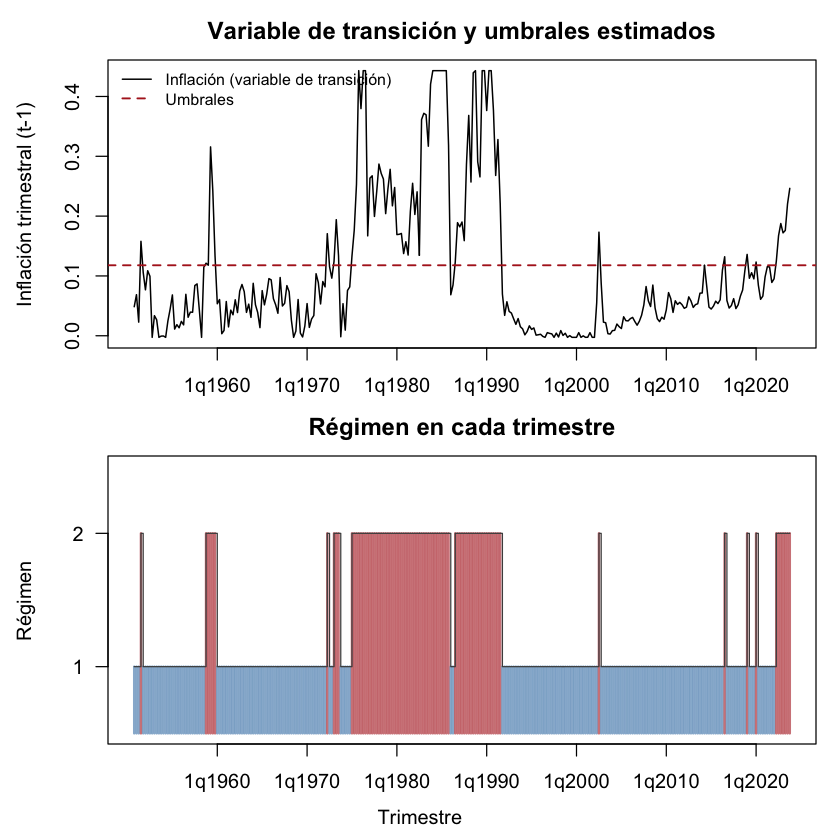

In [79]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar_p2_cap")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 6.2%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1501 -0.0044
         1 -0.1613 -0.0373
         2 -0.1369 -0.0619
         3 -0.1096 -0.0742
         4 -0.0858 -0.0791
         5 -0.0637 -0.0819
         6 -0.0433 -0.0839
         7 -0.0251 -0.0856
         8 -0.0085 -0.0869

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1501 -0.0044
         1 -0.0811 -0.0296
         2  0.0299 -0.0256
         3  0.1351 -0.0326
         4  0.2362 -0.0390
         5  0.3248 -0.0441
         6  0.4039 -0.0467
         7  0.4757 -0.0487
         8  0.5423 -0.0503


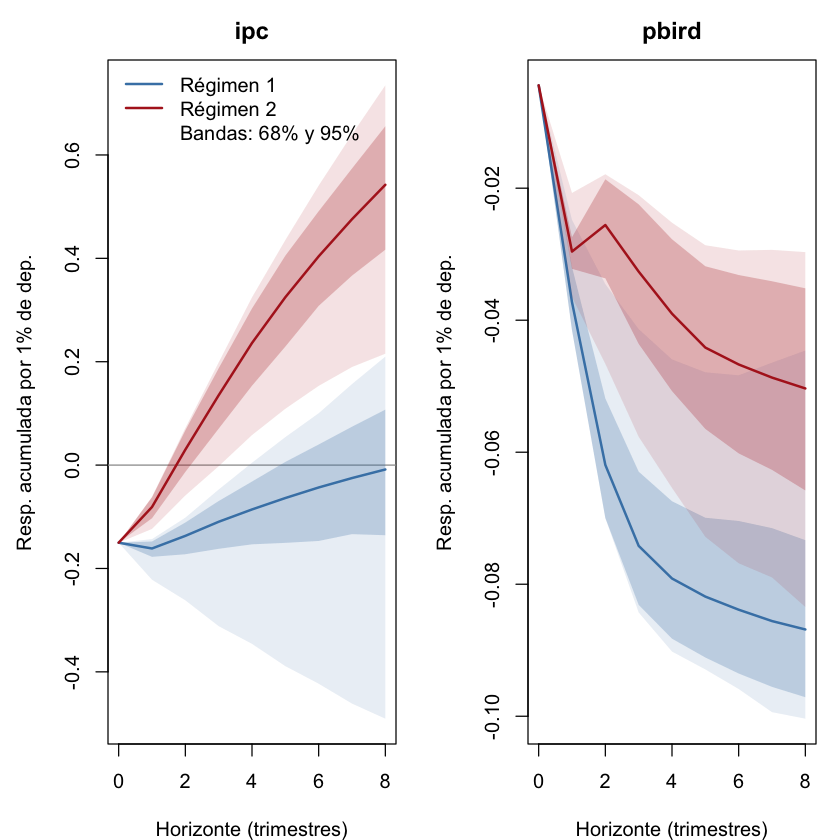

In [82]:
girf_impp_usa_tvar_p2_cap <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_p2_cap,
                                        archivo = "girf_original_impp_usa_tvar_p2_cap")

In [80]:
ls(pattern = "^out_impp_usa_tvar_p2_cap")

[1] "out_impp_usa_tvar_p2_cap"      "out_impp_usa_tvar_p2_cap_acum"

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4             -0.05              0.14
Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4            -0.071             0.238


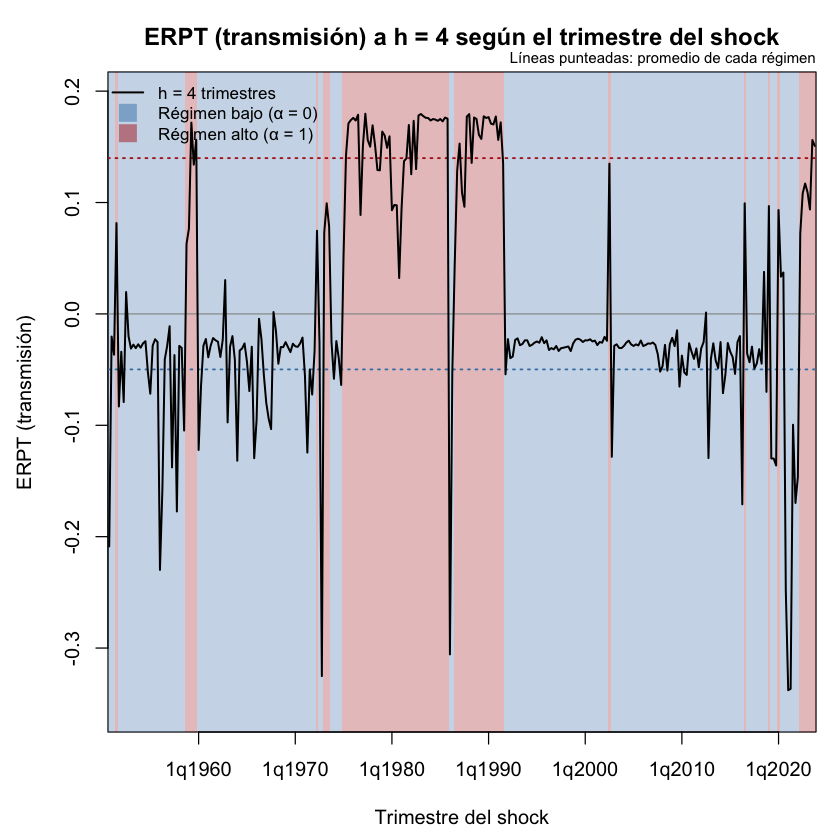

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         8             0.005              0.27


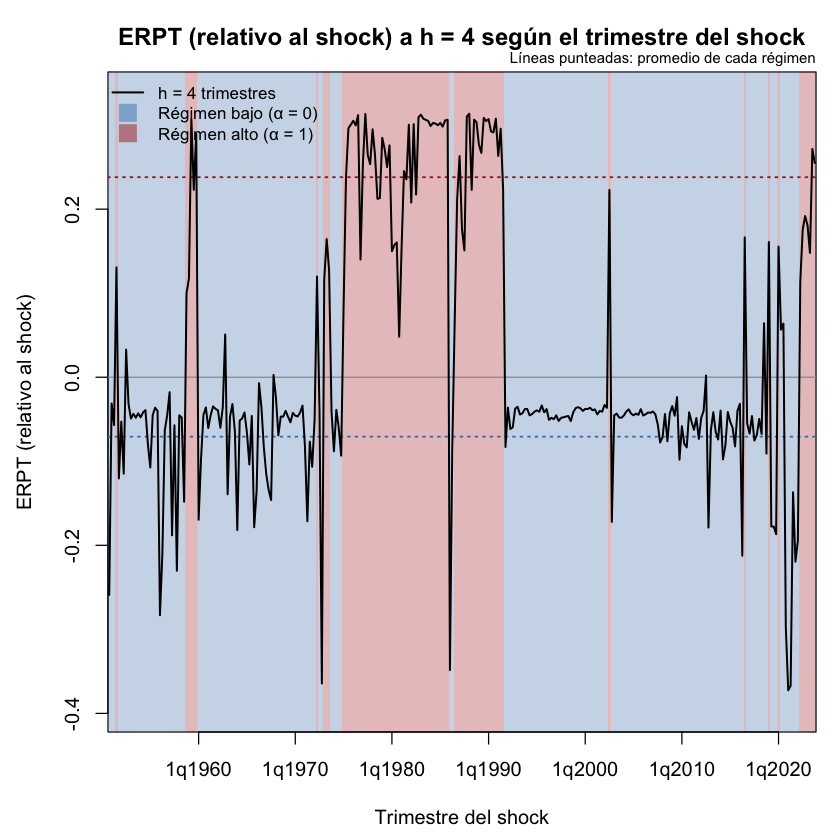

Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         8             0.023             0.536


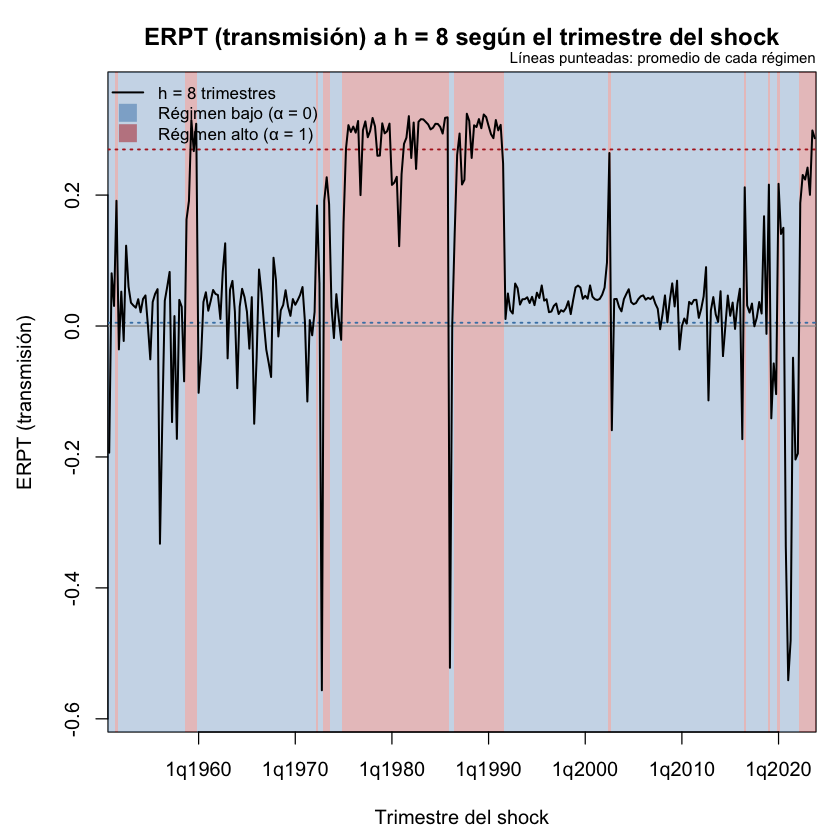

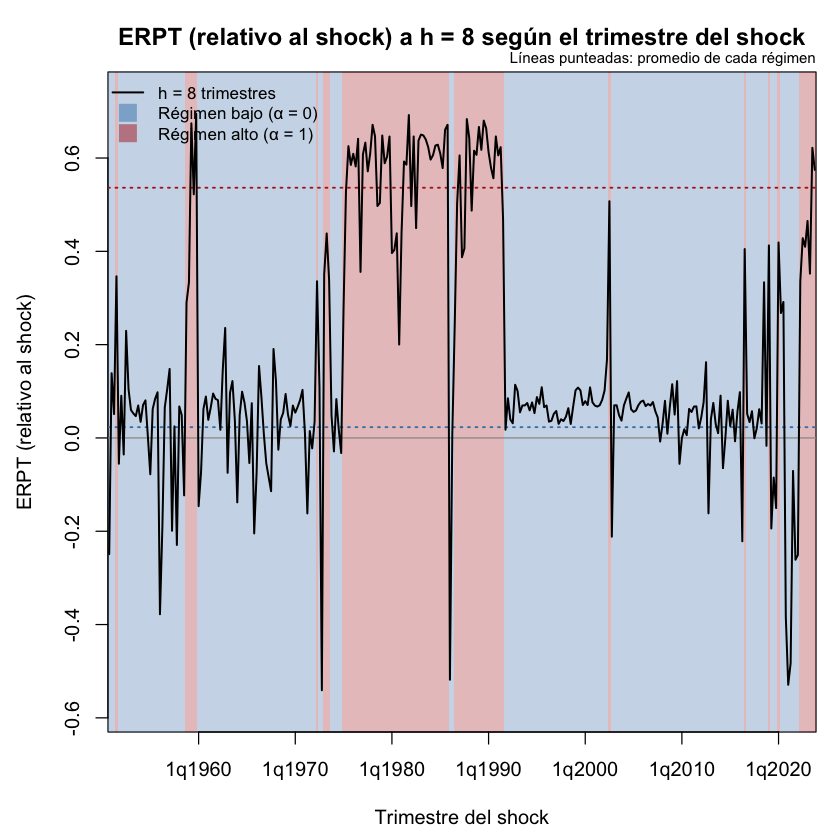

In [81]:
for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(out_impp_usa_tvar_p2_cap_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar_p2_cap_acum_h", h))
  graficar_erpt_2d_bandas(out_impp_usa_tvar_p2_cap, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar_p2_cap_h", h))
}

## TVAR, 2 regímenes, p = 3

Se cargó exitosamente modelos preguardados  threshold_tvar_3_2_500_61adfee444710eb1eb640dcc4b0e780d.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


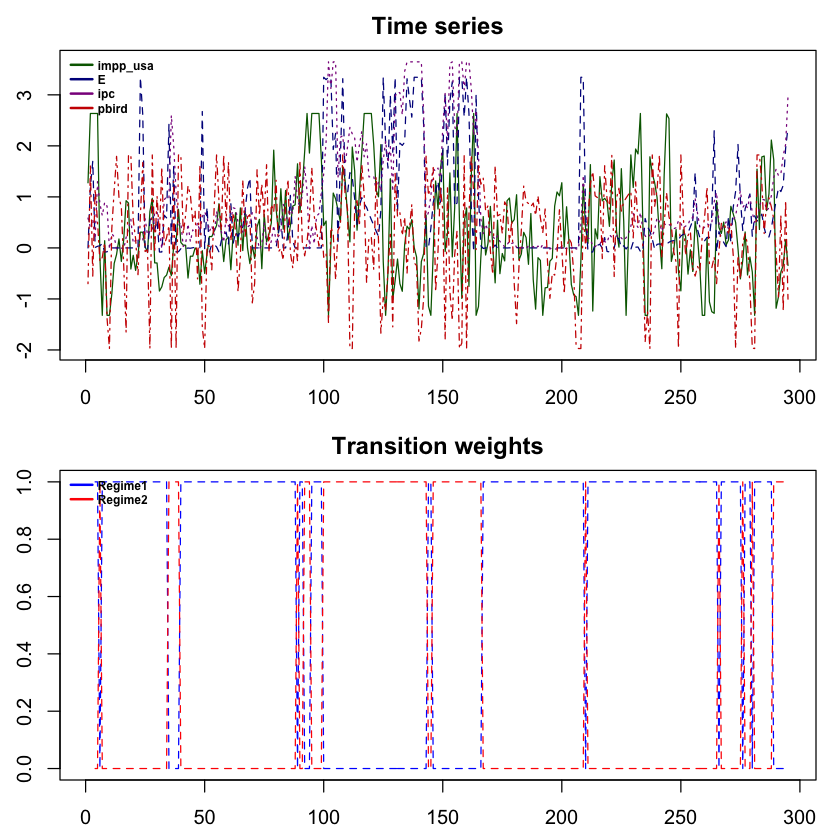

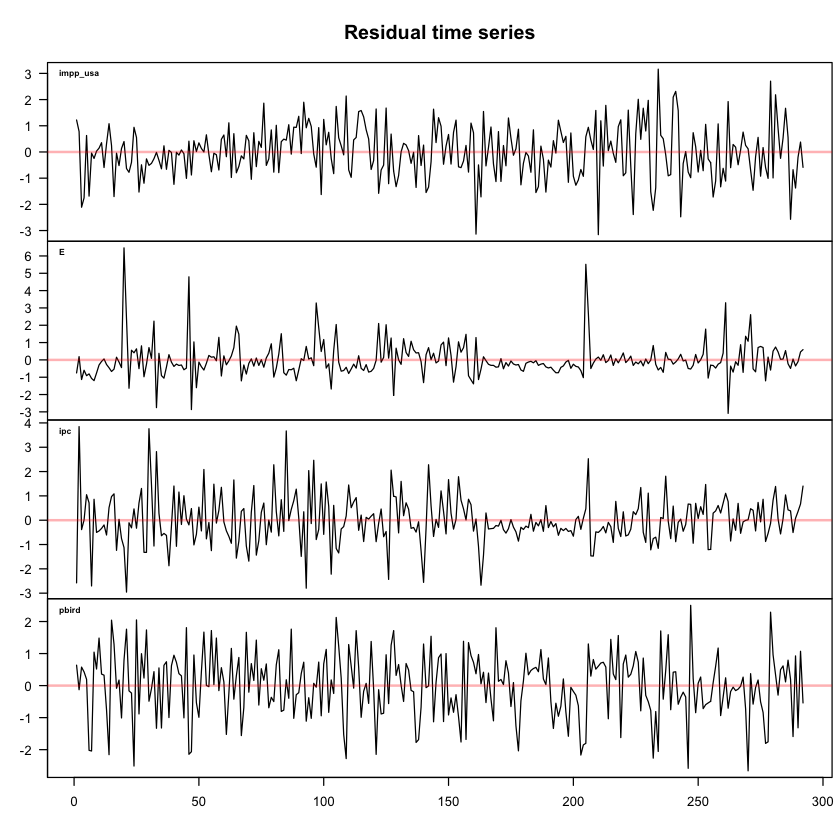

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



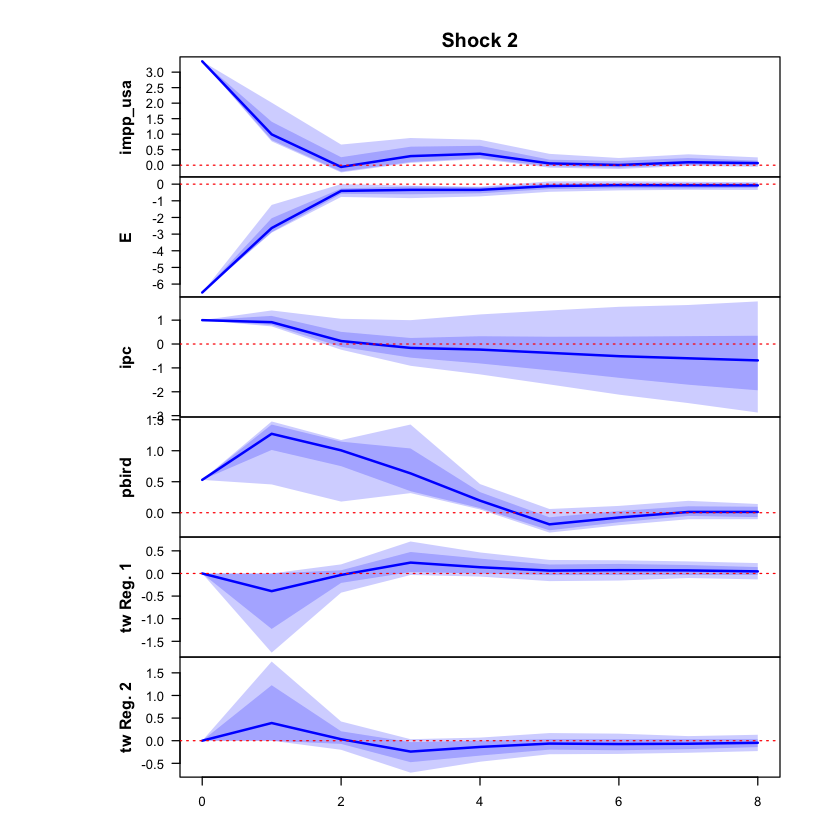

 >>> Linear IRF ( 1  shock units)


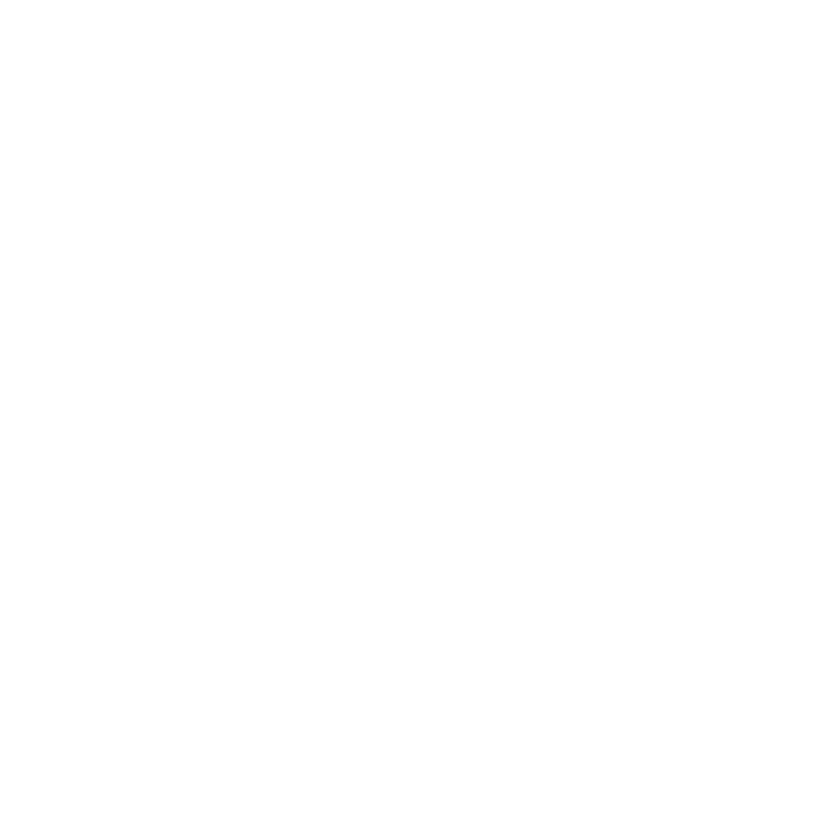

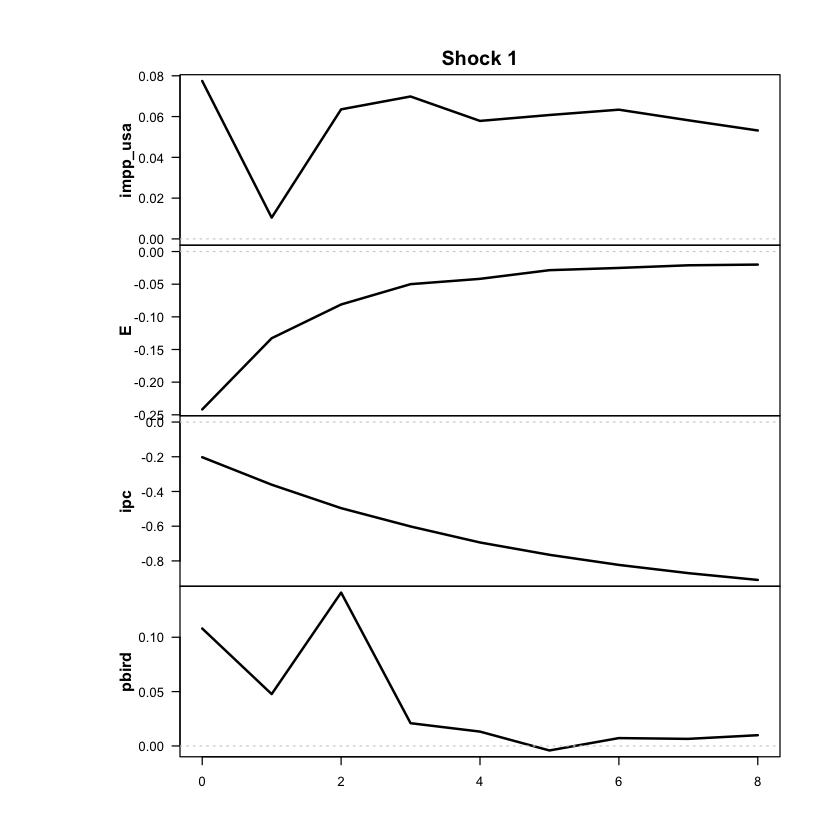

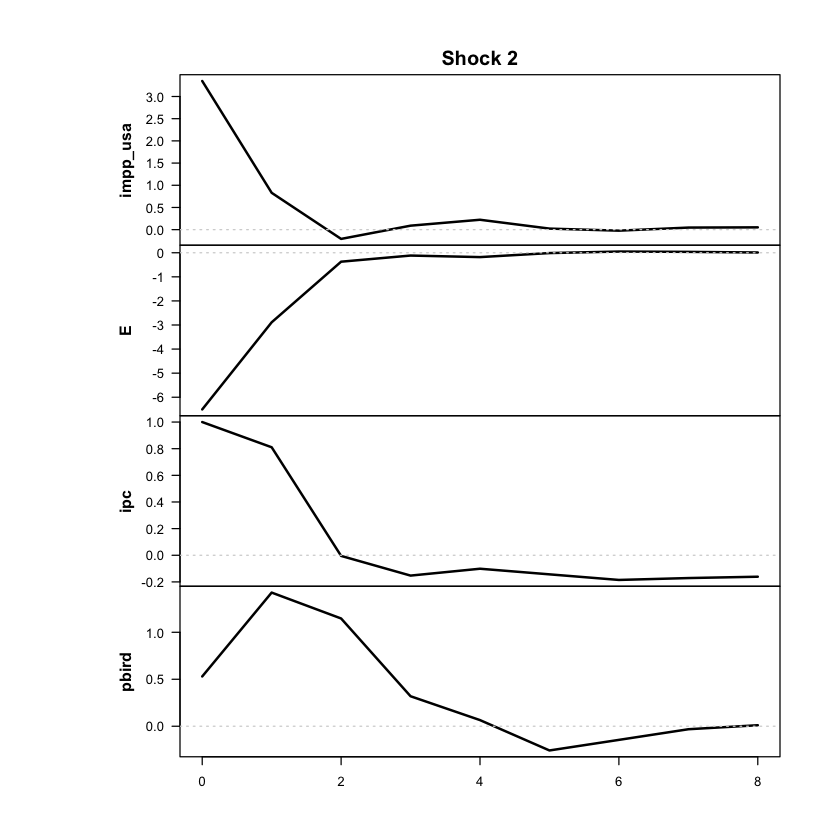

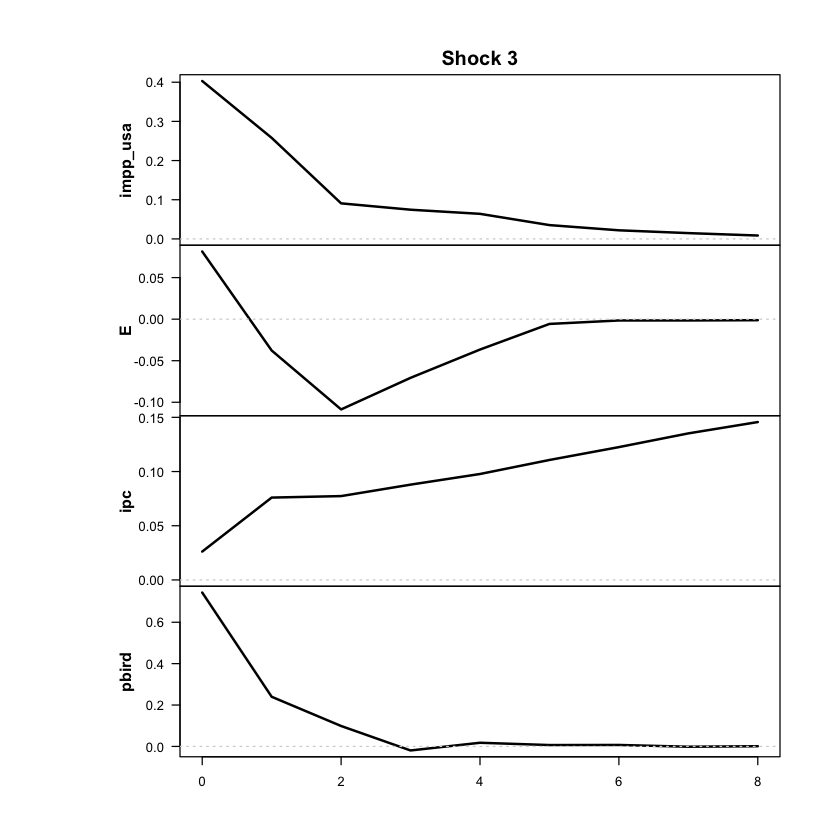

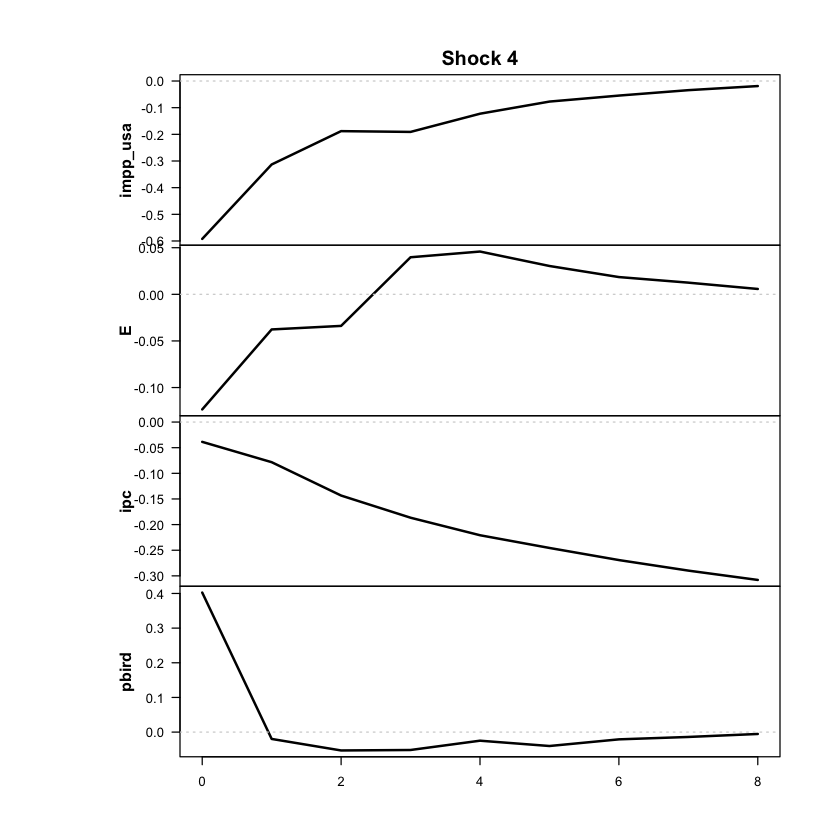

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



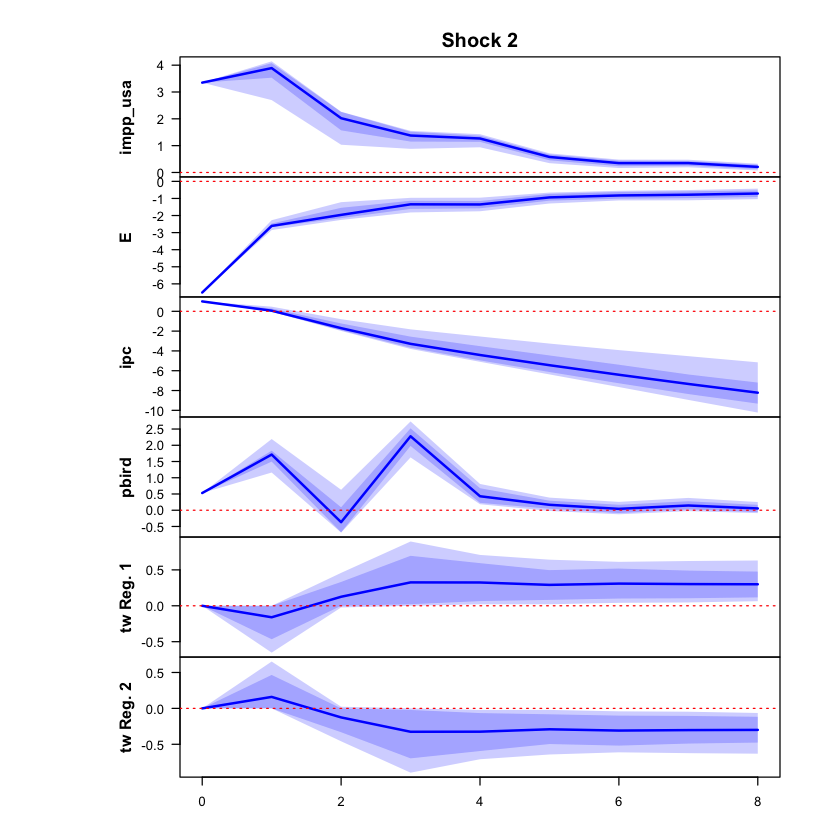

 >>> Linear IRF ( 1  shock units)


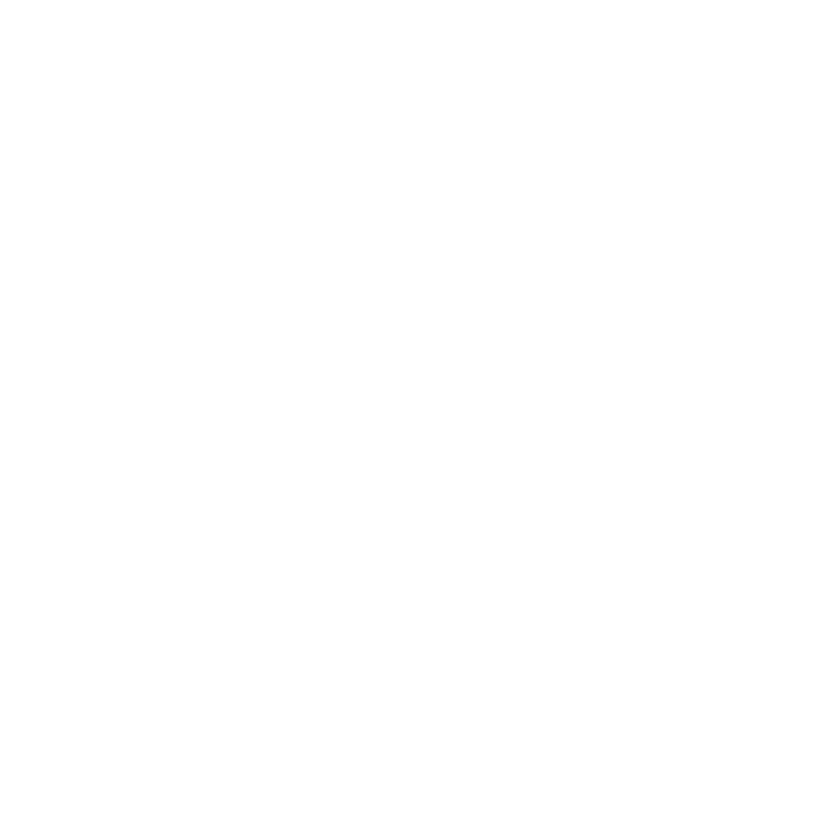

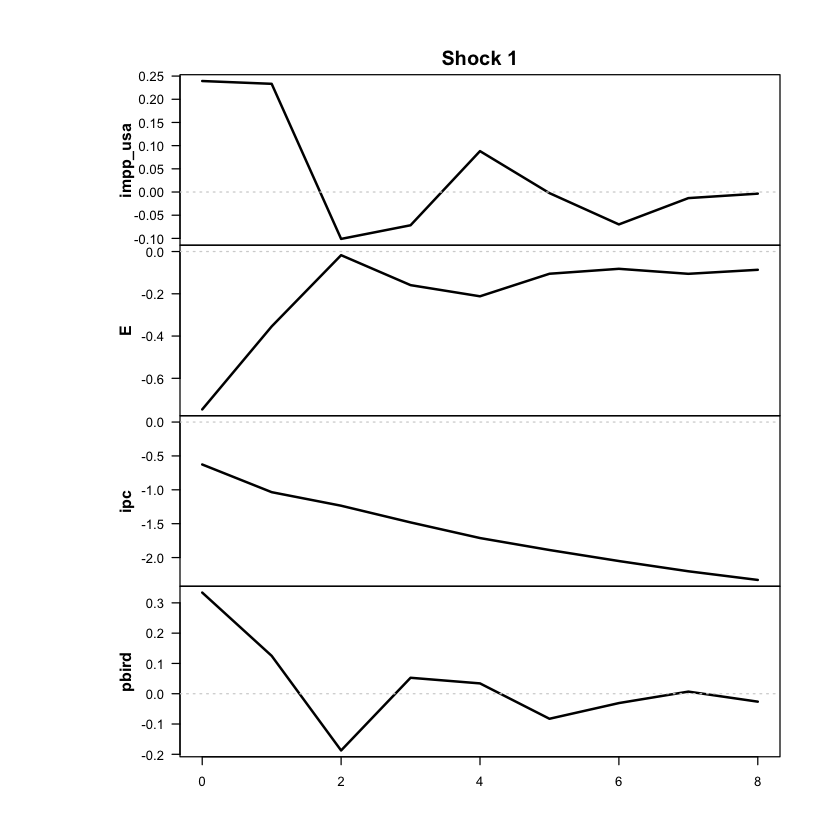

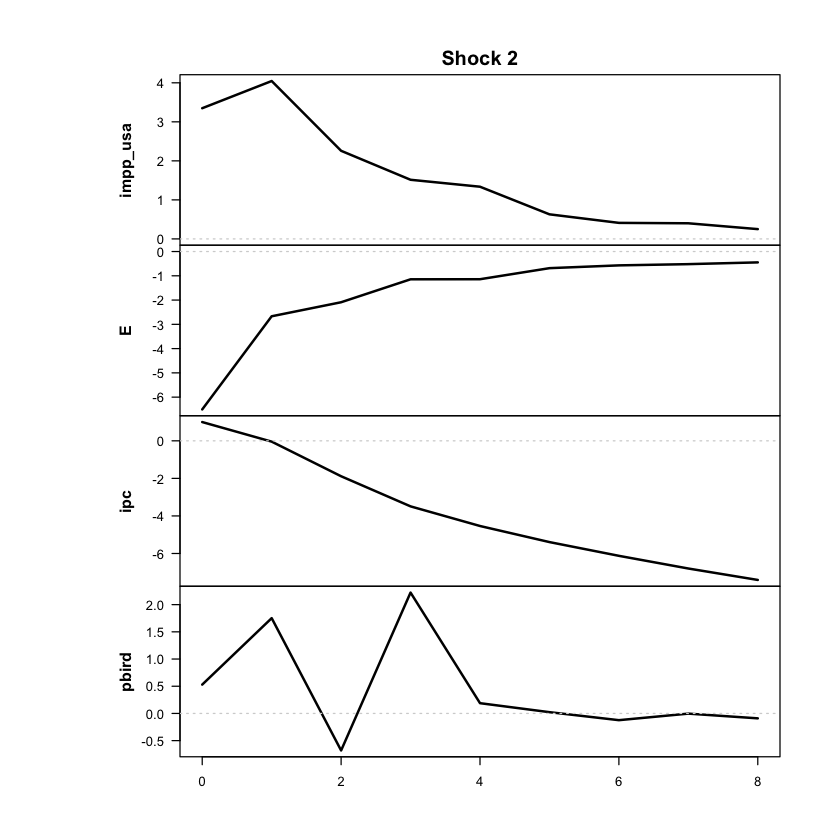

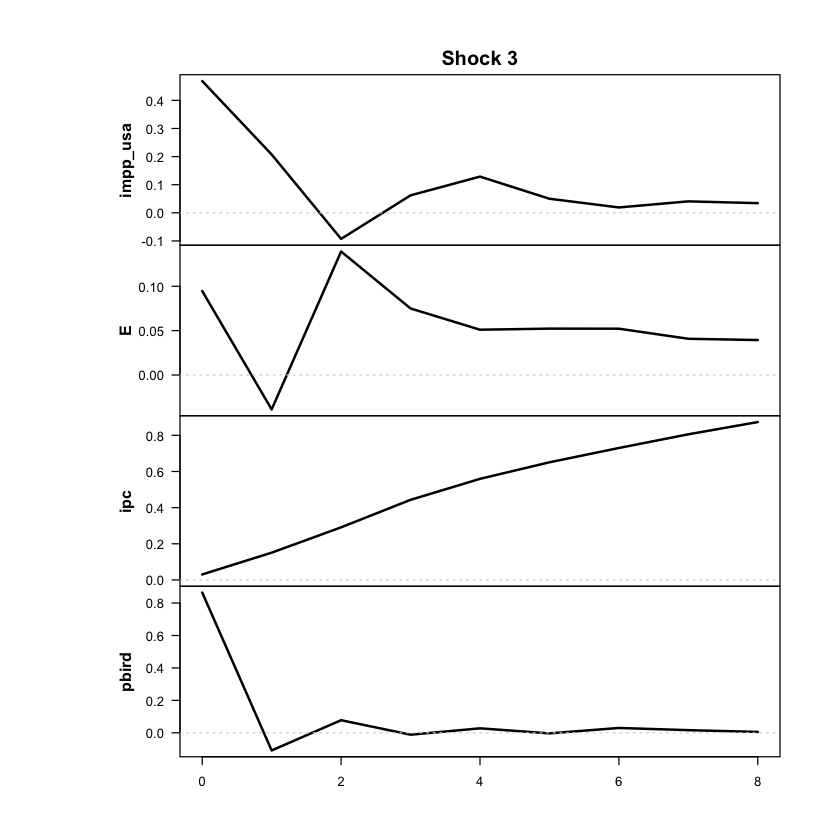

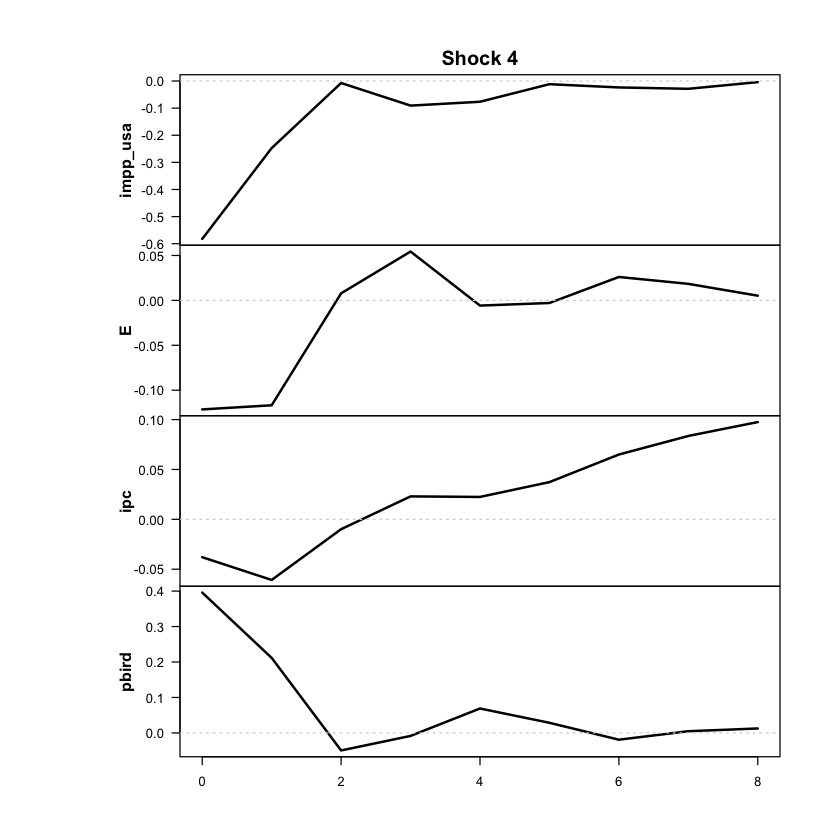

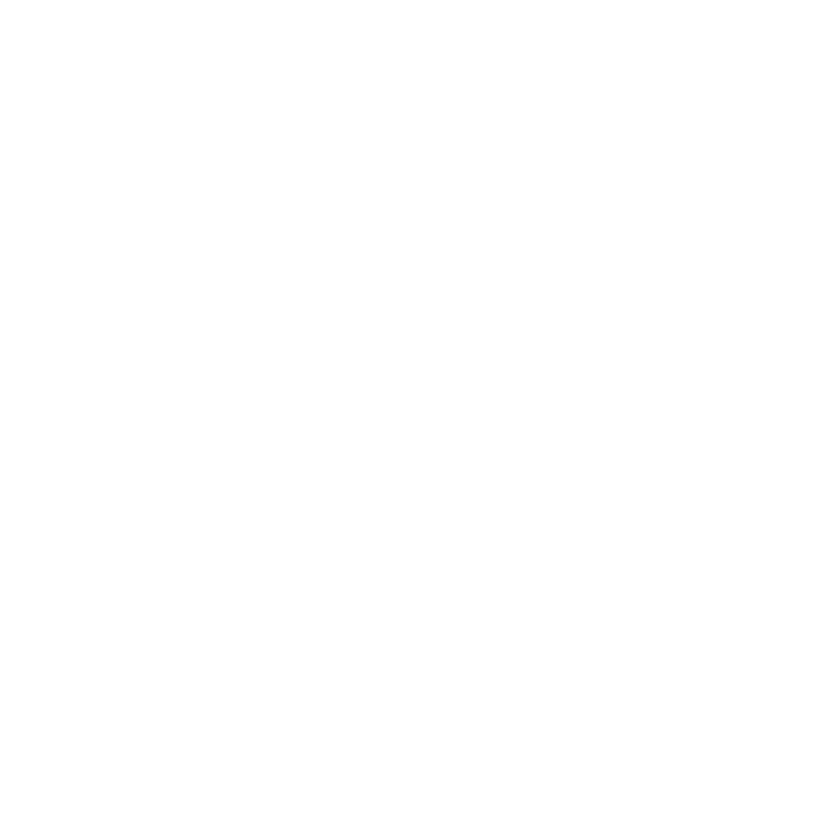

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 3,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [48]:
ic_tvar_p3_cap <- criterios_info(res, "TVAR p=3 cap")
print(ic_tvar_p3_cap)

        modelo regimenes parametros  loglik  AIC     HQ    BIC
1 TVAR p=3 cap         2        125 -992.51 2235 2419.1 2694.6


In [32]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 2 | rezagos: 3 | errores: Gaussian 
Umbrales: 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 206 | régimen 2 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.55      1.02
E             3.85     27.25
ipc           4.76     29.68
pbird         0.83     -0.03


In [33]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -992.51            12.5    NA         NA           206/86
 trim_reg_alto trim_transicion raiz_casi_unit cov_casi_singular descartar
            86               0          FALSE             FALSE     FALSE


In [34]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 3, M = 2, d = 4, #parameters = 125, #observations = 292 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.97 
Regime means: 0.22, 0.30, 0.47, 0.31

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.16 ] + [  0.53  0.15  0.00  0.04 ] y1.1 + [  0.01 -0.01 -0.38 -0.06
2 y2   [ 0.20 ]   [ -0.07  0.42  0.10 -0.06 ] y2.1   [  0.02 -0.13  0.15 -0.09
3 y3   [ 0.07 ]   [  0.01  0.14  0.64  0.02 ] y3.1   [  0.00  0.05  0.00 -0.05
4 y4   [ 0.26 ]   [  0.20 -0.09  0.06  0.22 ] y4.1   [  0.03 -0.12 -0.47  0.00
                A3                              Omega                     1/2
1 ] y1.2 + [  0.15  0.06  0.07  0.00 ] y1.3 + [  0.56  0.01  0.03  0.08 ]    
2 ] y2.2   [ -0.06 -0.03 -0.07  0.02 ] y2.3   [  0.01  0.24  0.03 -0.03 ]    
3 ] y3.2   [  0.02 -0.06  0.12  0.04 ] y3.3   [  0.03  0.03  0.05 -0.02 ]    
4 ] y4.2   [ -0.06  0.08

In [35]:
shock_tvar_p3_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar_p3_cap <- 2
shock_tvar_p3_cap

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0015 -0.0040  0.0078 -0.0115
  E        -0.0369  0.0608  0.0124 -0.0189
  ipc      -0.0246 -0.0074  0.0032 -0.0047
  pbird     0.0025 -0.0008  0.0175  0.0094

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.71    0.88    0.10    0.17 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.666  -0.122   0.256   0.249 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — tvar p3 cap

Correr solo si el modelo pasó el diagnóstico.

In [36]:
out_impp_usa_tvar_p3_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_p3_cap)

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_bajo_original reg_alto_original
1         0           -0.1222           -0.1222
2         1           -0.1054           -0.0135
3         2           -0.0051            0.1927
4         3            0.0275            0.3754
5         4            0.0359            0.5073
6         5            0.0546            0.6272
7         6            0.0751            0.7395
8         7            0.0879            0.8459
9         8            0.1002            0.9476


In [37]:
out_impp_usa_tvar_p3_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_p3_cap,
                      definicion = "acumulado")

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_bajo_original reg_alto_original
1         0           -0.1222           -0.1222
2         1           -0.0747           -0.0098
3         2           -0.0044            0.1140
4         3            0.0163            0.1987
5         4            0.0202            0.2424
6         5            0.0305            0.2812
7         6            0.0416            0.3144
8         7            0.0476            0.3430
9         8            0.0531            0.3686


Umbrales (inflación trimestral de t-1): 12.5% trimestral (60% anualizada) 
Trimestres por régimen: régimen 1 = 206 | régimen 2 = 86 


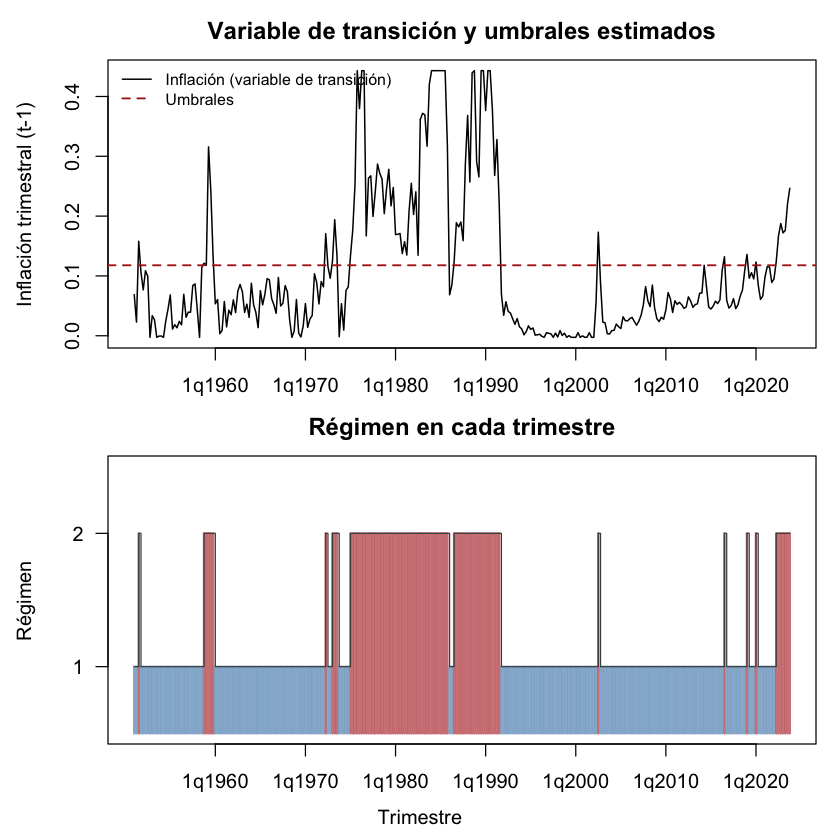

In [38]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar_p3_cap")

## VLSTAR, 2 regímenes, p = 2

Con cappeo y commodities, el VLSTAR daba soluciones válidas (γ ≈ 12, umbral ≈ 10,5%). Verificar si pasa lo mismo con impp_usa.

Se cargó exitosamente modelos preguardados  vlstar_2_2_500_41ff5d0a290dc29150bb88c804aa7292.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


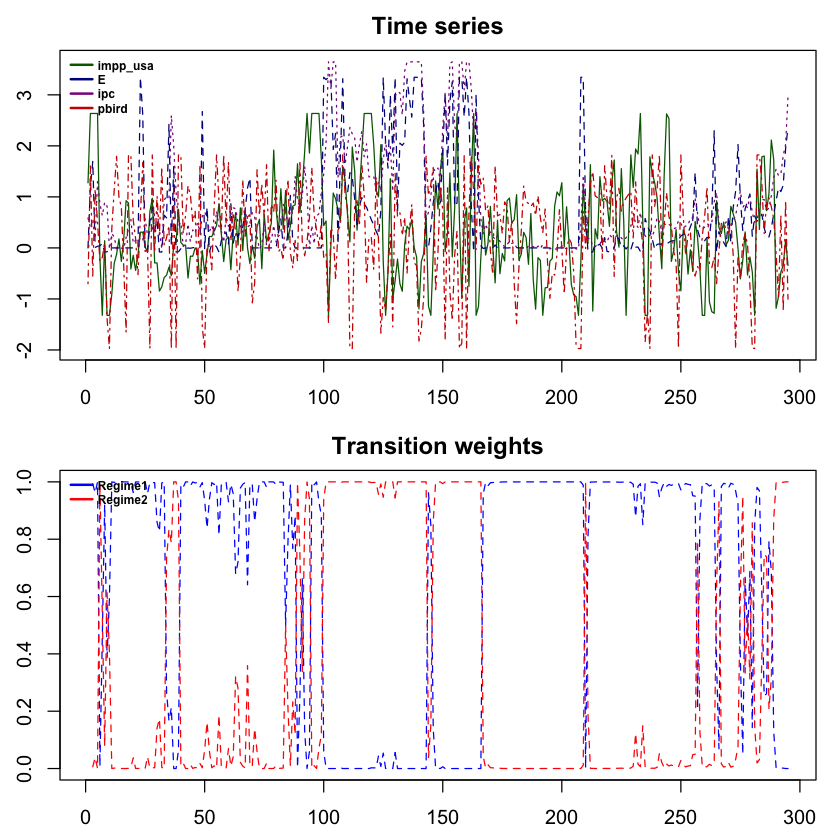

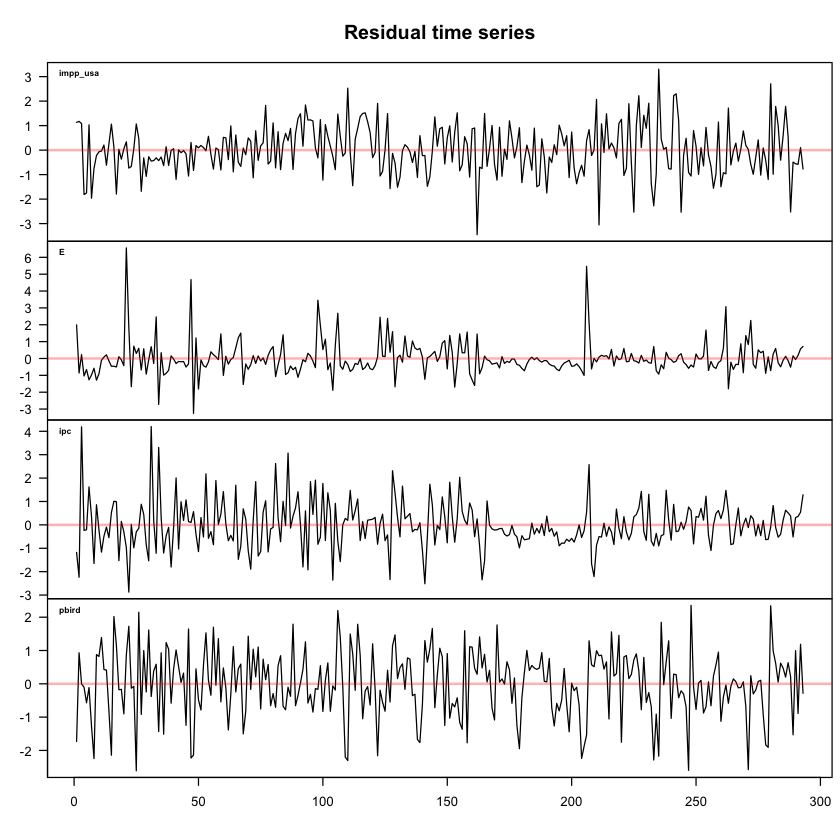

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



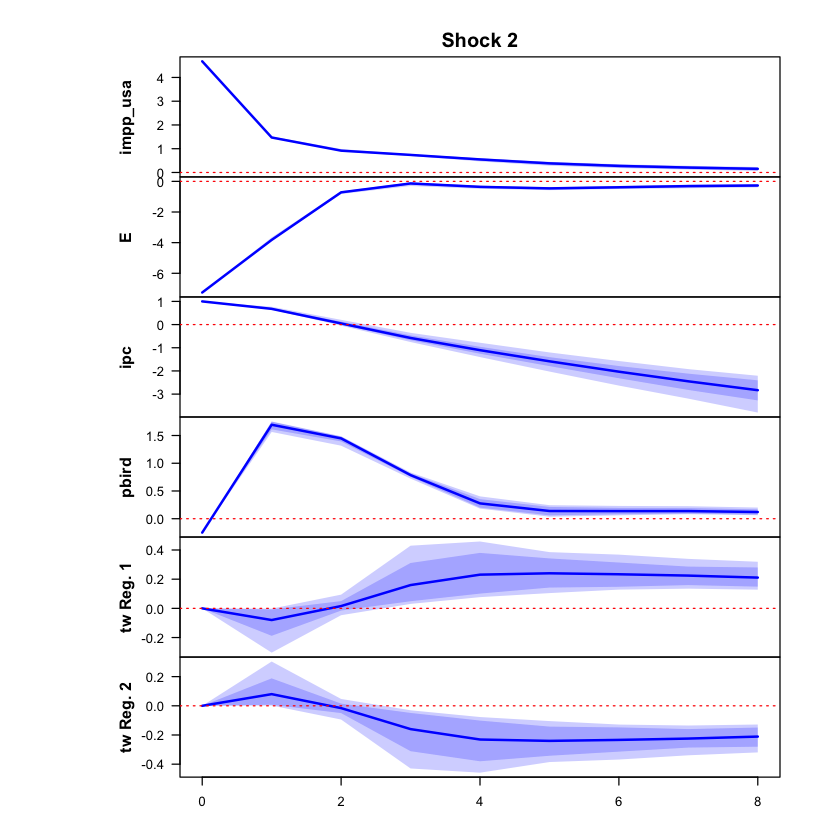

 >>> Linear IRF ( 1  shock units)


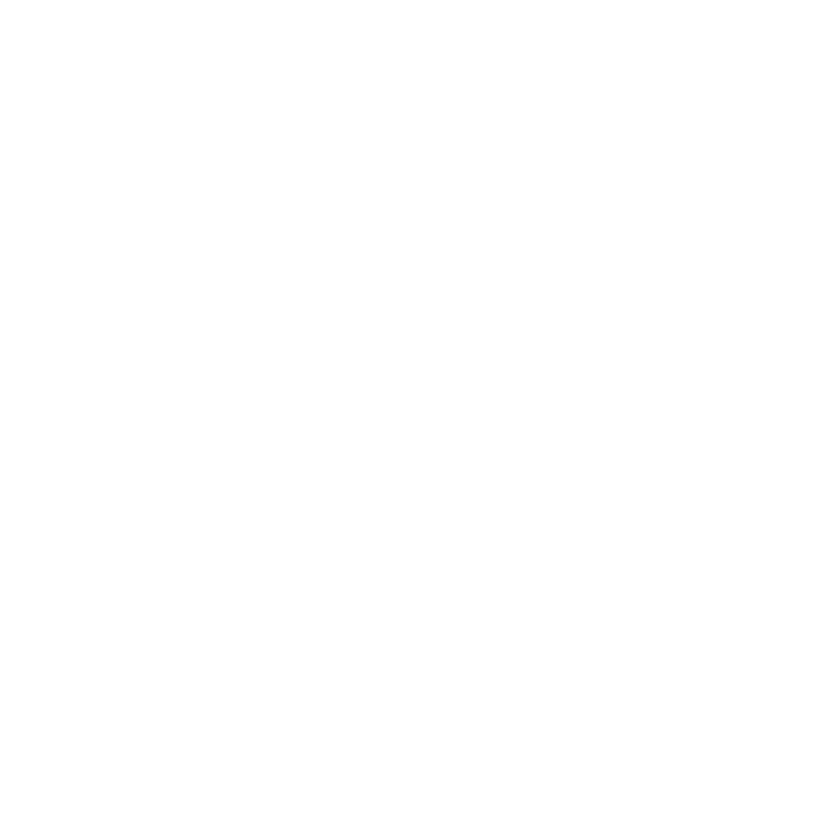

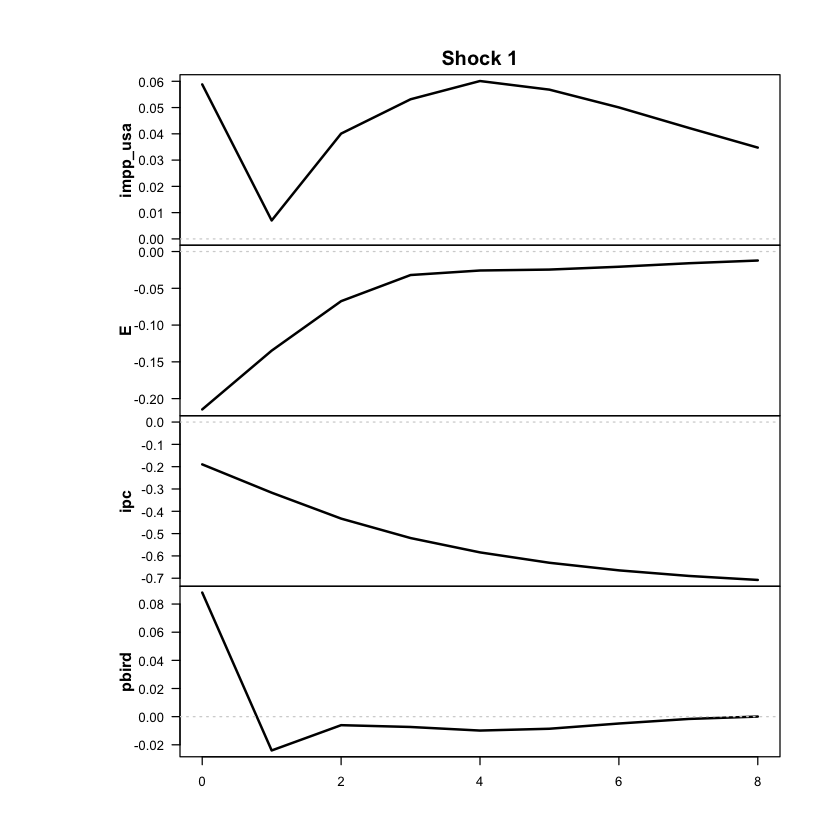

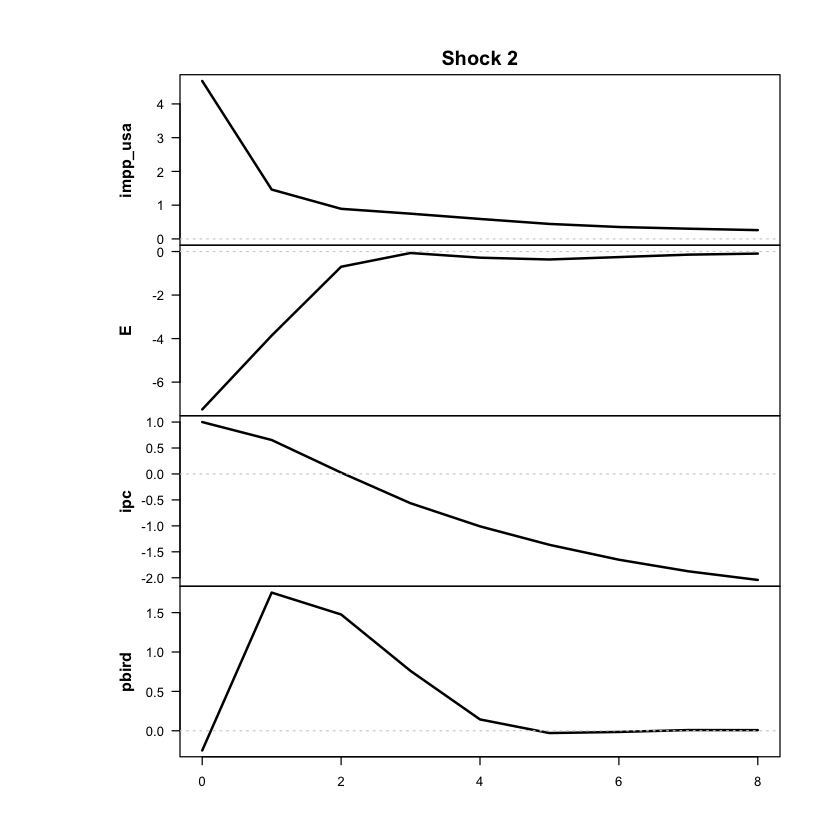

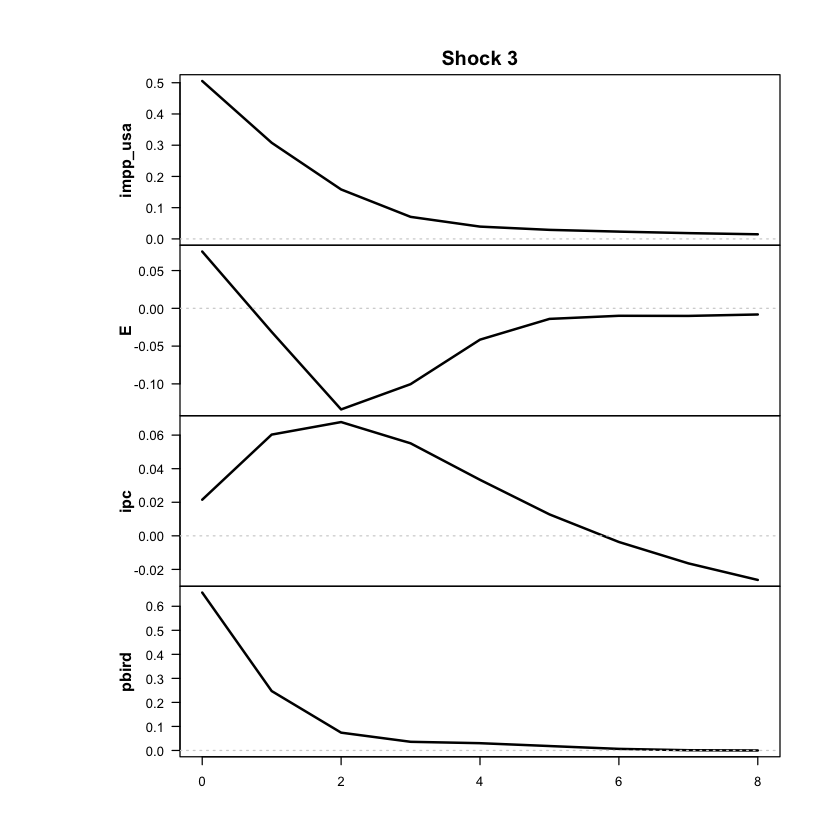

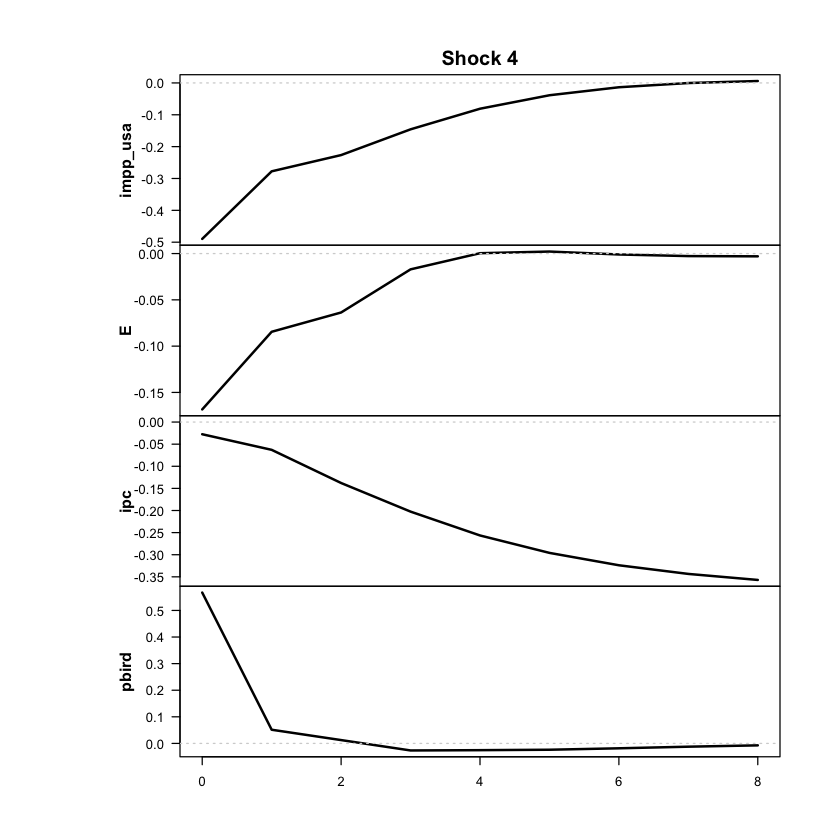

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



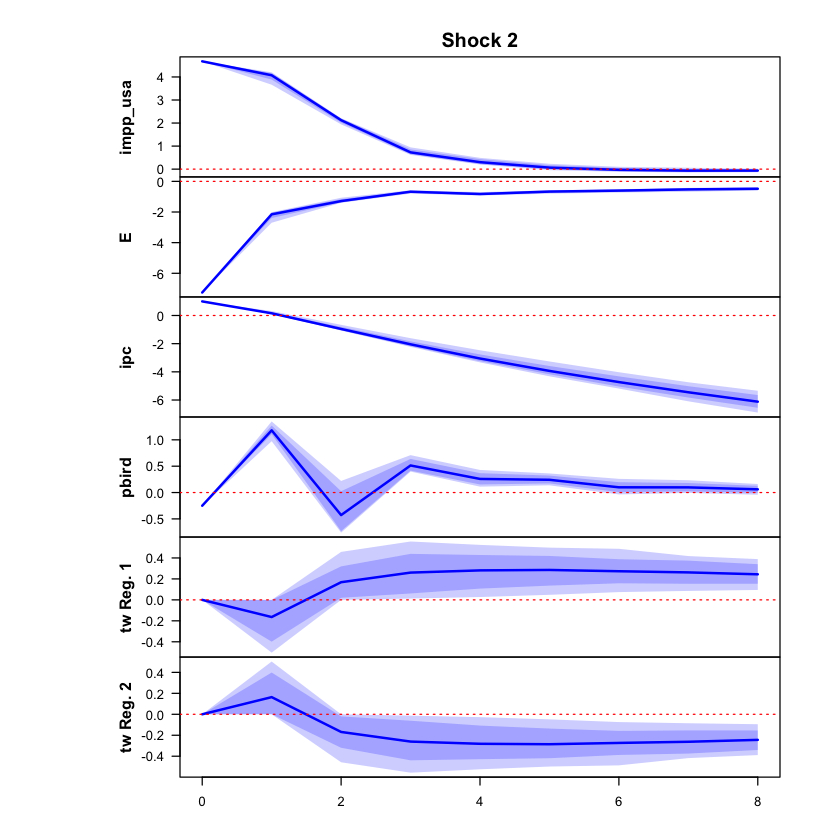

 >>> Linear IRF ( 1  shock units)


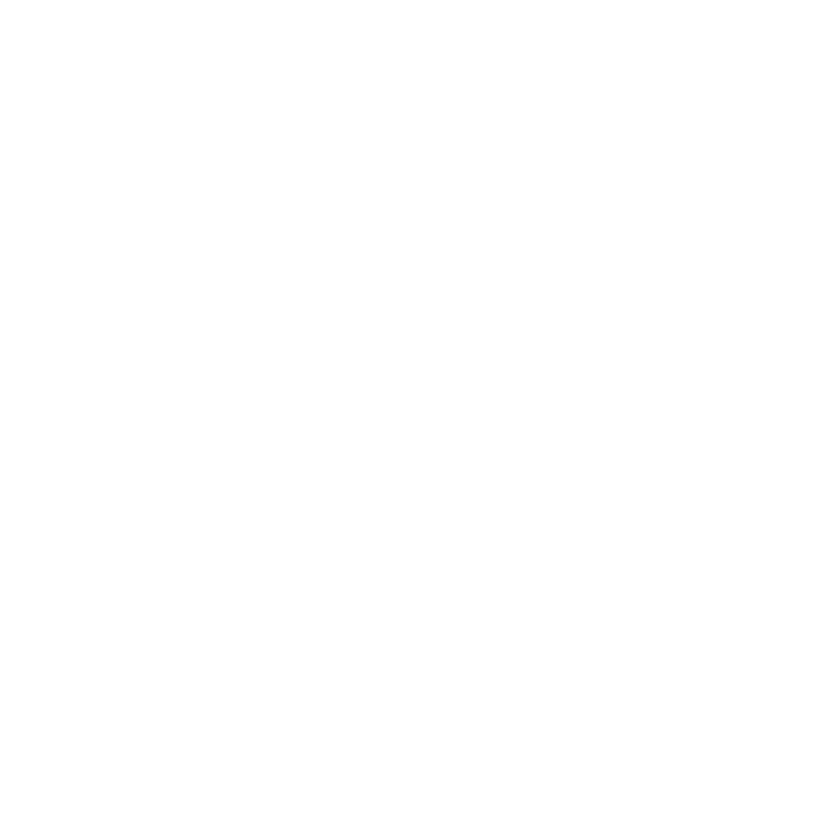

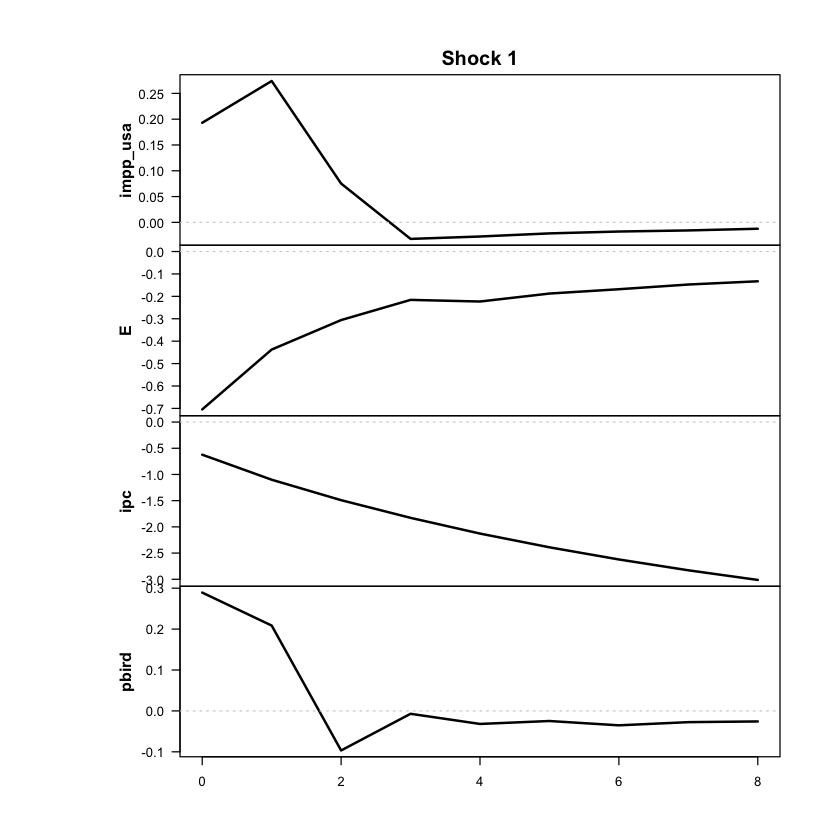

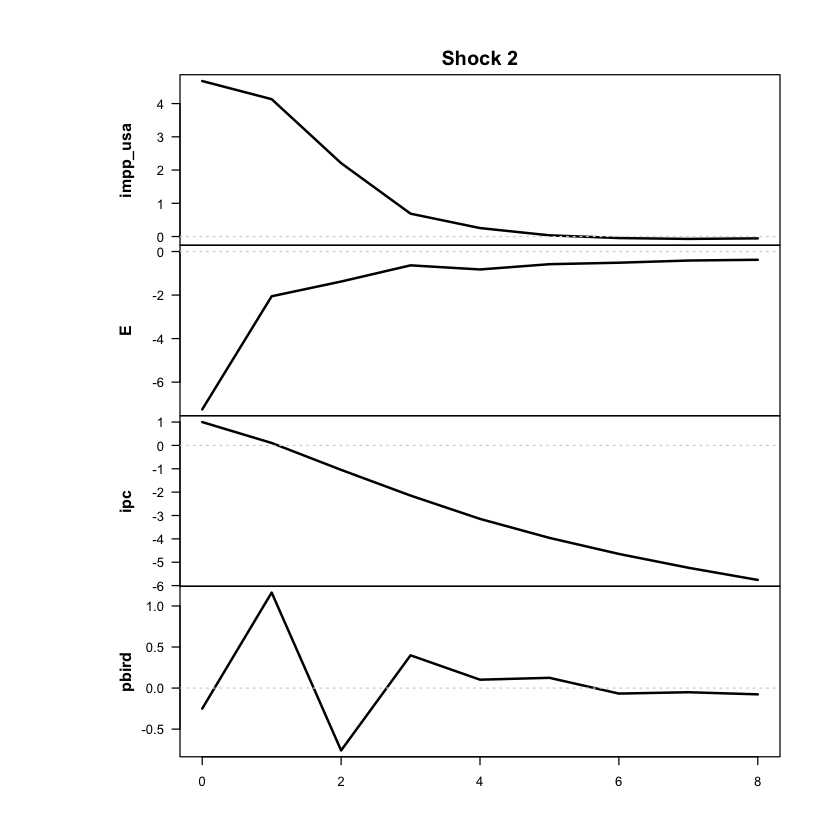

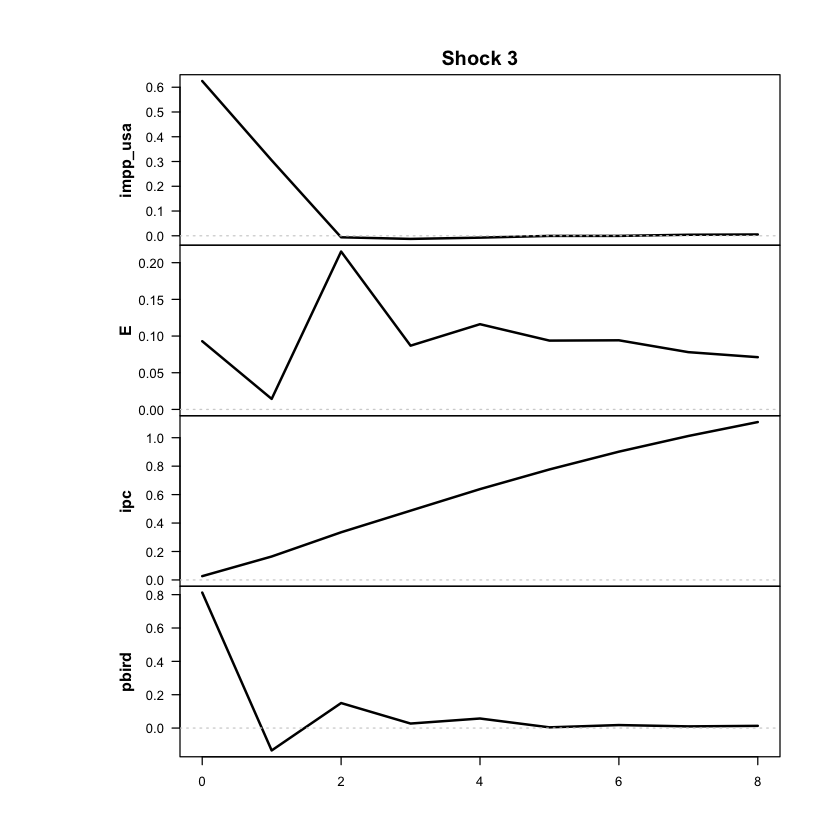

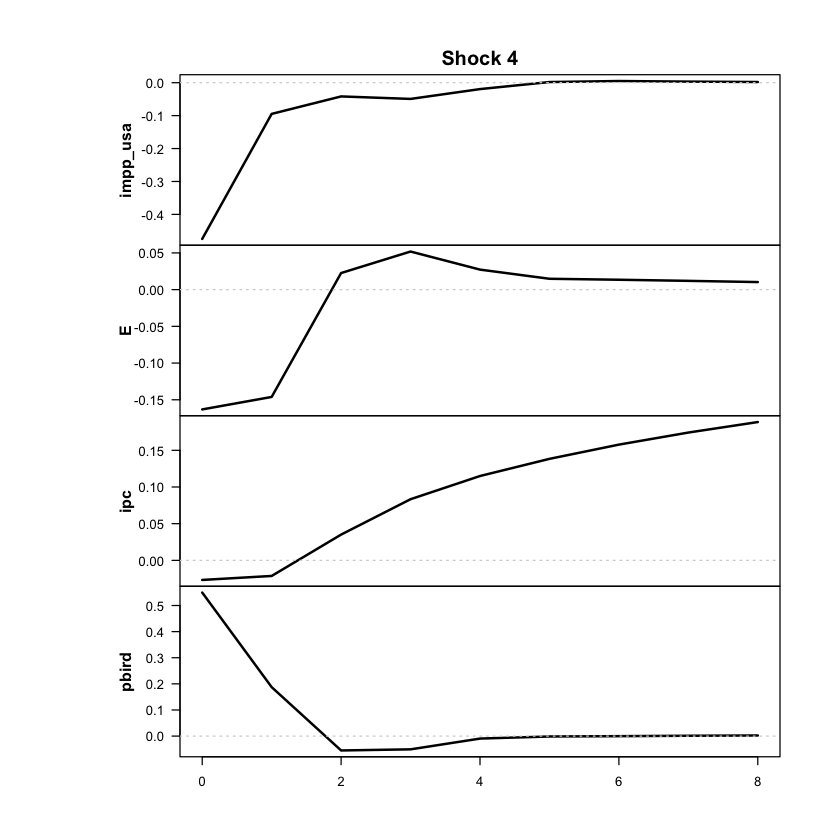

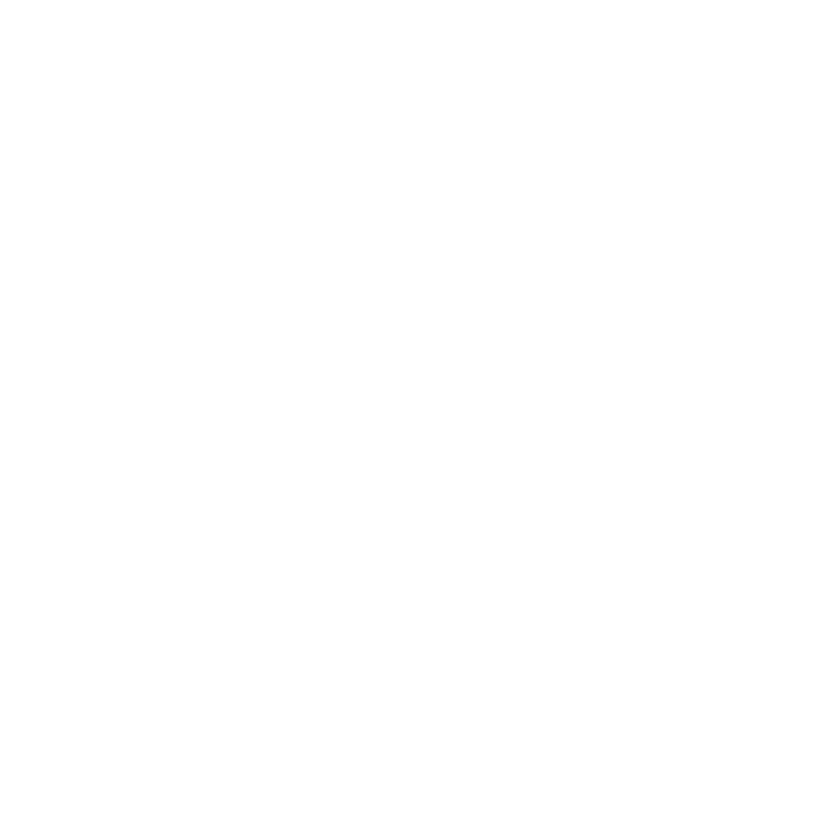

In [ ]:
res <- run_vlstar (
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [50]:
ic_vlstar_p2_cap <- criterios_info(res, "VLSTAR p=2 cap")
print(ic_vlstar_p2_cap)

          modelo regimenes parametros  loglik  AIC     HQ    BIC
1 VLSTAR p=2 cap         2         94 -1031.5 2251 2389.5 2596.9


In [42]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: Gaussian 
Umbral (c): 10.9 % trimestral ( 51 % anualizada) | gamma: 11.15 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 197 | régimen 2 = 96 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.60      0.91
E             3.90     24.76
ipc           4.47     27.60
pbird         0.87     -0.03


In [43]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -1031.5            10.9 11.15         NA           197/96
             7 -1031.5            10.9 11.14         NA           197/96
 trim_reg_alto trim_transicion raiz_casi_unit cov_casi_singular descartar
            80              42          FALSE             FALSE     FALSE
            80              42          FALSE             FALSE     FALSE


In [44]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 94, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Weight params: 0.85 (location), 11.15 (scale) 
Regime means: 0.26, 0.27, 0.41, 0.41

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.19 ] + [  0.55  0.15 -0.02  0.03 ] y1.1 + [  0.08 -0.06 -0.23 -0.07
2 y2   [ 0.19 ]   [ -0.07  0.50  0.09 -0.05 ] y2.1   [  0.00 -0.19  0.10 -0.11
3 y3   [ 0.11 ]   [  0.01  0.13  0.53  0.02 ] y3.1   [  0.02  0.03  0.12 -0.05
4 y4   [ 0.21 ]   [  0.18 -0.08  0.39  0.24 ] y4.1   [ -0.07 -0.14 -0.06 -0.01
             Omega                     1/2     
1 ] y1.2 + [  0.56  0.01  0.03  0.06 ]     eps1
2 ] y2.2   [  0.01  0.24  0.03 -0.06 ]     eps2
3 ] y3.2   [  0.03  0.03  0.04 -0.02 ]     eps3
4 ] y4.2   [  0.06 -0.06 -0.02  0.76 ]     eps4

Regime 2 
Regime means:  0.53,  1.18,  1.66, -0.03

   Y      phi0       

In [84]:
shock_vlstar_p2_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_p2_cap <- 2
shock_vlstar_p2_cap

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0011 -0.0050  0.0098 -0.0095
  E        -0.0328  0.0608  0.0115 -0.0257
  ipc      -0.0231 -0.0067  0.0026 -0.0033
  pbird     0.0021  0.0003  0.0154  0.0133

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.70    0.83    0.09    0.22 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.703  -0.110   0.228   0.130 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

### ERPT — vlstar p2 cap

Correr solo si el modelo pasó el diagnóstico.

In [85]:
out_impp_usa_vlstar_p2_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_p2_cap)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 6.3%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 171 | régimen 2 = 80 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.1096           -0.1096
2         1           -0.0797           -0.0190
3         2           -0.0130            0.0997
4         3            0.0547            0.2165
5         4            0.1143            0.3249
6         5            0.1697            0.4190
7         6            0.2238            0.5048
8         7            0.2748            0.5825
9         8            0.3219            0.6560

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.1096          -0.1096
2         1          -0.0754          -0.0145
3         2          -0.0059           0.1058
4         3           0.0627           0.2269
5         4        

In [86]:
out_impp_usa_vlstar_p2_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_p2_cap,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 6.3%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 171 | régimen 2 = 80 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.1096           -0.1096
2         1           -0.0532           -0.0145
3         2           -0.0086            0.0677
4         3            0.0327            0.1384
5         4            0.0667            0.1937
6         5            0.0955            0.2371
7         6            0.1218            0.2726
8         7            0.1458            0.3028
9         8            0.1669            0.3293

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.1096          -0.1096
2         1          -0.0495          -0.0113
3         2          -0.0037           0.0720
4         3           0.0382           0.1448
5         4        

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4             0.067             0.194
Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4             0.114             0.325


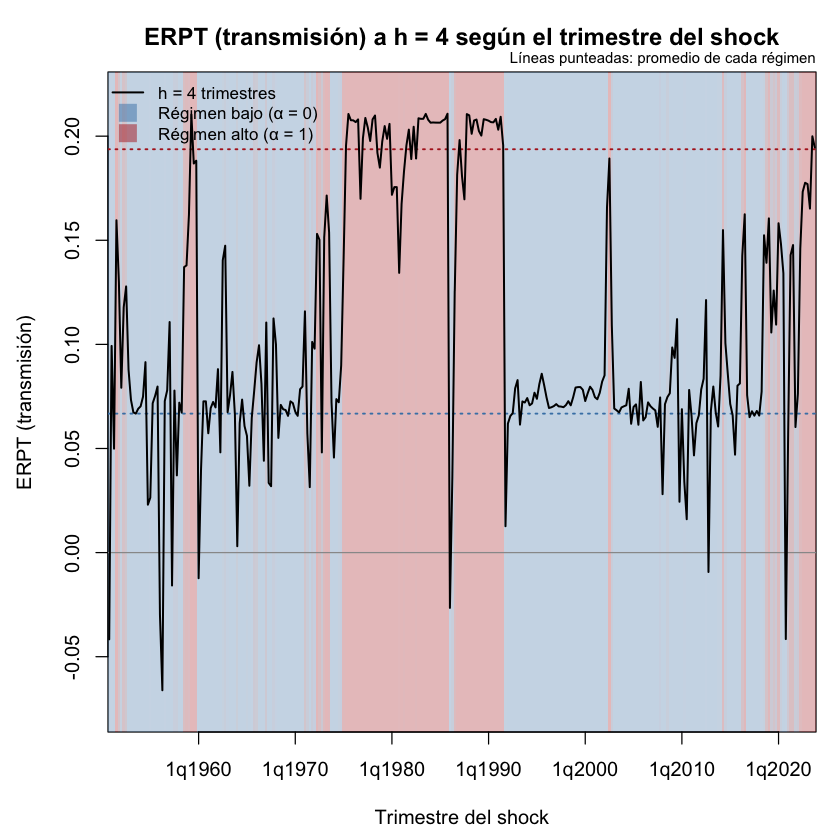

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         8             0.167             0.329


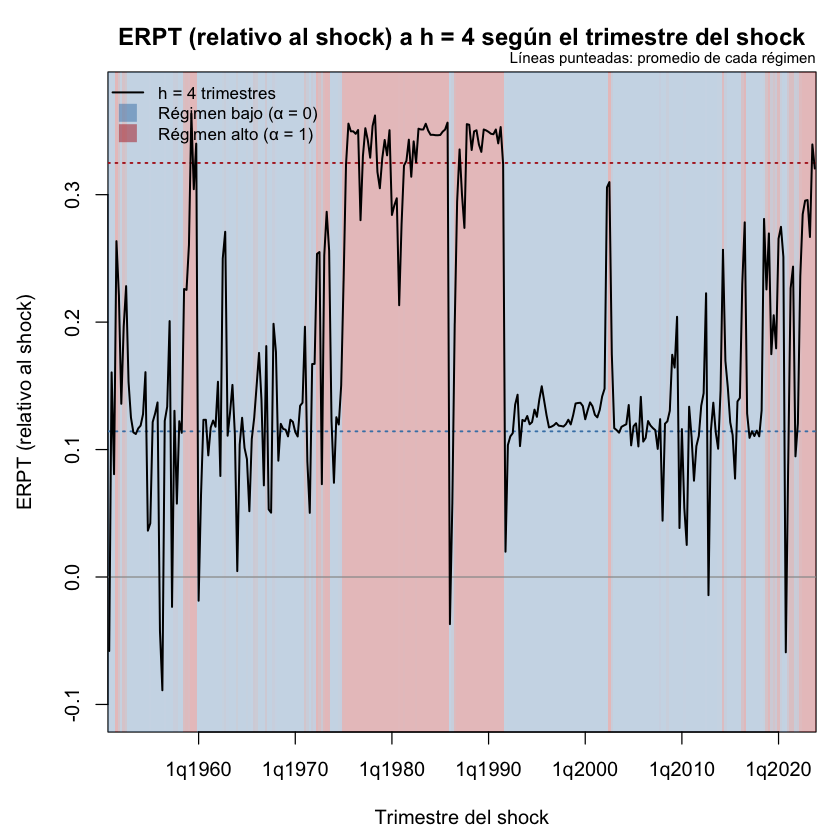

Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         8             0.322             0.656


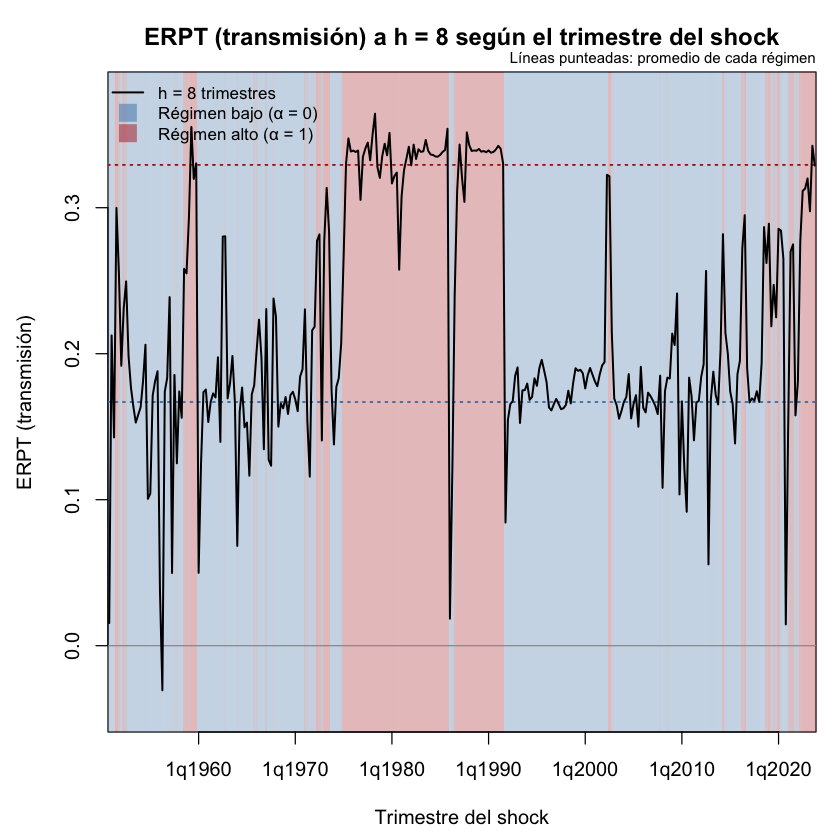

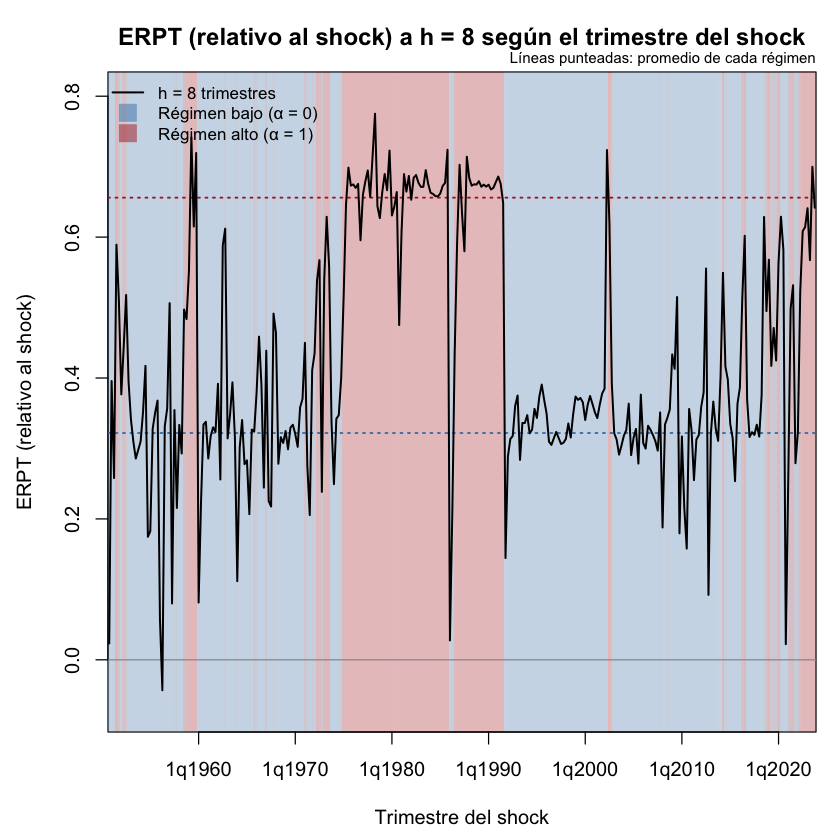

In [87]:
for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(out_impp_usa_vlstar_p2_cap_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_vlstar_p2_cap_acum_h", h))
  graficar_erpt_2d_bandas(out_impp_usa_vlstar_p2_cap, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_vlstar_p2_cap_h", h))
}

Parámetros usados -> c (escalado): 0.85 | gamma: 11.15 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.1037 | franja 10%-90%: 0.0797 a 0.1276 


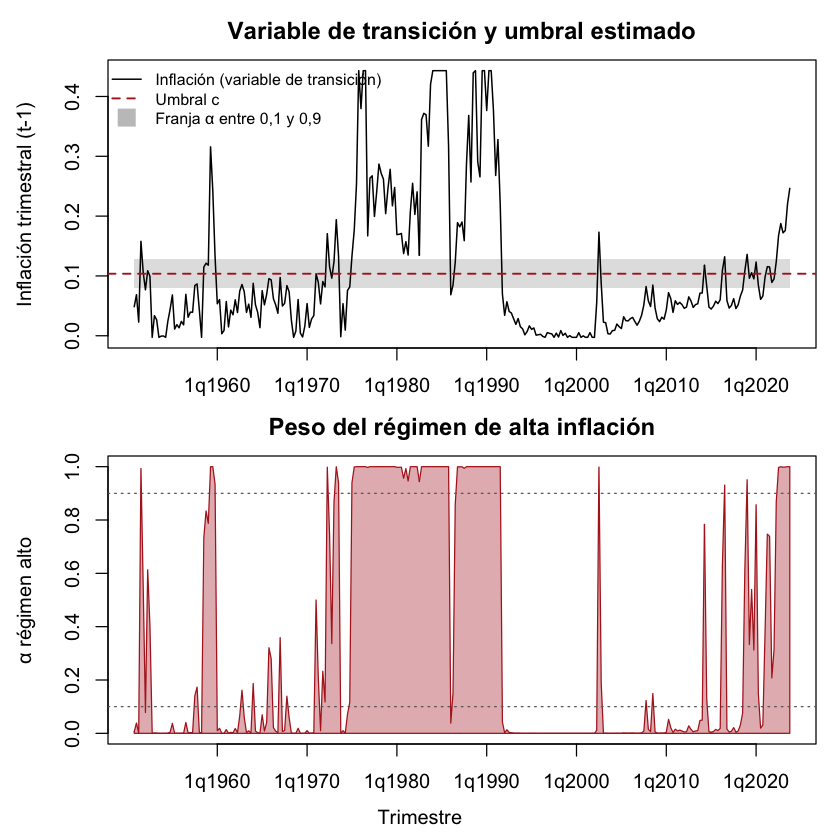

In [48]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_vlstar_p2_cap")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 6.3%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1096  0.0053
         1 -0.0740 -0.0306
         2 -0.0045 -0.0613
         3  0.0651 -0.0780
         4  0.1239 -0.0839
         5  0.1774 -0.0870
         6  0.2275 -0.0900
         7  0.2739 -0.0930
         8  0.3165 -0.0955

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1096  0.0053
         1 -0.0179 -0.0196
         2  0.1027 -0.0107
         3  0.2209 -0.0216
         4  0.3307 -0.0271
         5  0.4264 -0.0323
         6  0.5126 -0.0345
         7  0.5913 -0.0364
         8  0.6643 -0.0379


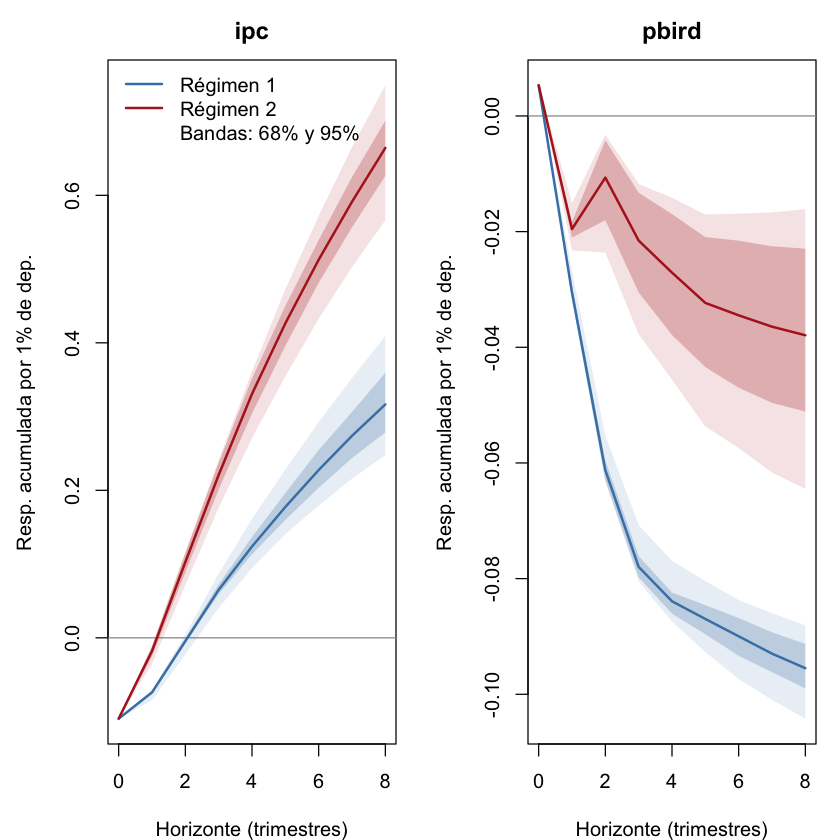

In [88]:
girf_impp_usa_vlstar_p2_cap <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_p2_cap,
                                        archivo = "girf_original_impp_usa_vlstar_p2_cap")

Promedio de ERPT por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         8             0.167             0.329


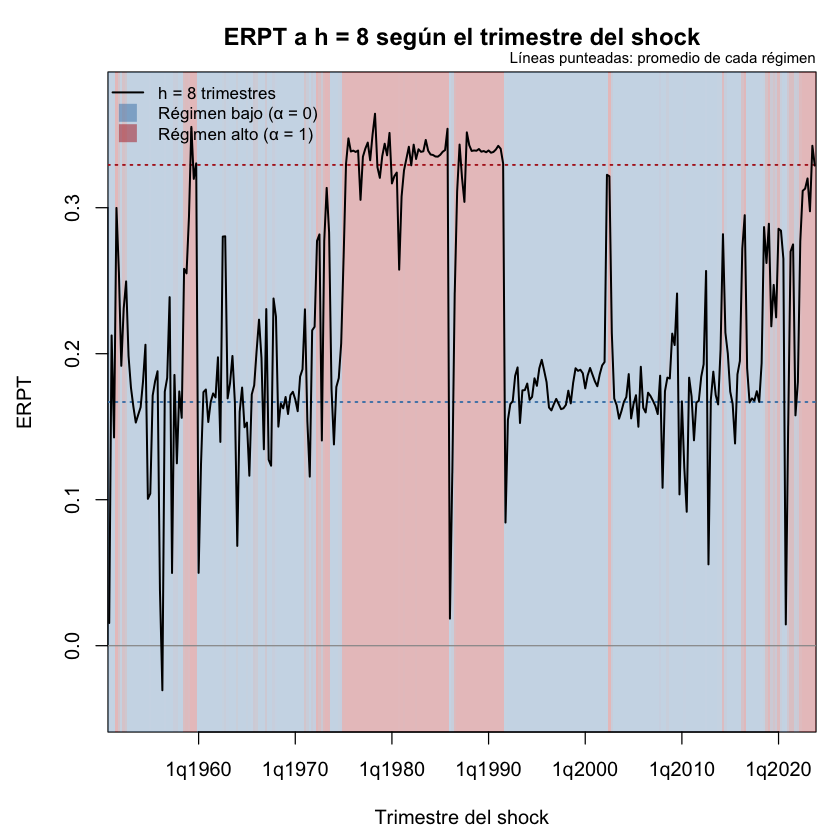

In [50]:
graficar_erpt_2d_bandas(out_impp_usa_vlstar_p2_cap_acum, horizontes = 8, archivo = "erpt_2d_bandas_impp_usa_vlstar_p2_cap_acum")

## VLSTAR, 2 regímenes, p = 3

Con cappeo y commodities, el VLSTAR daba soluciones válidas (γ ≈ 12, umbral ≈ 10,5%). Verificar si pasa lo mismo con impp_usa.

Se cargó exitosamente modelos preguardados  vlstar_3_2_500_61adfee444710eb1eb640dcc4b0e780d.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


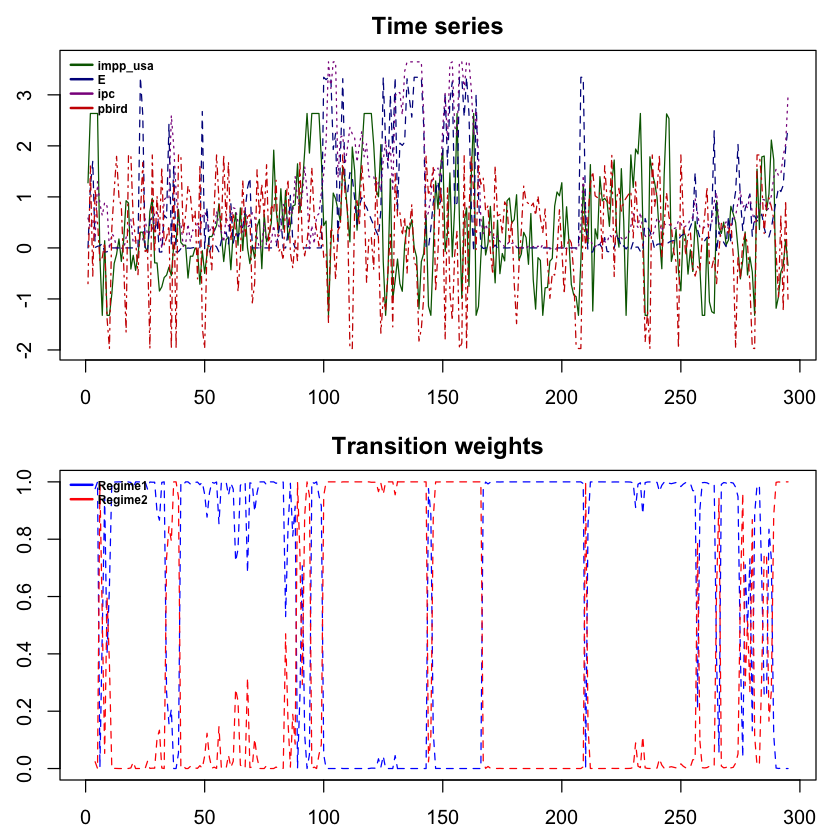

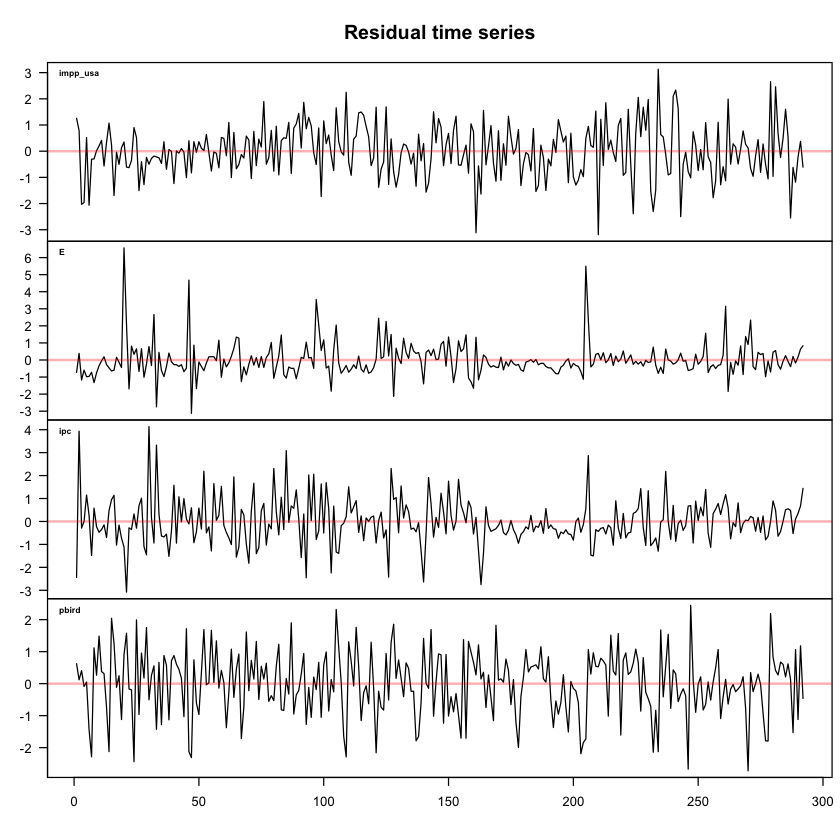

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



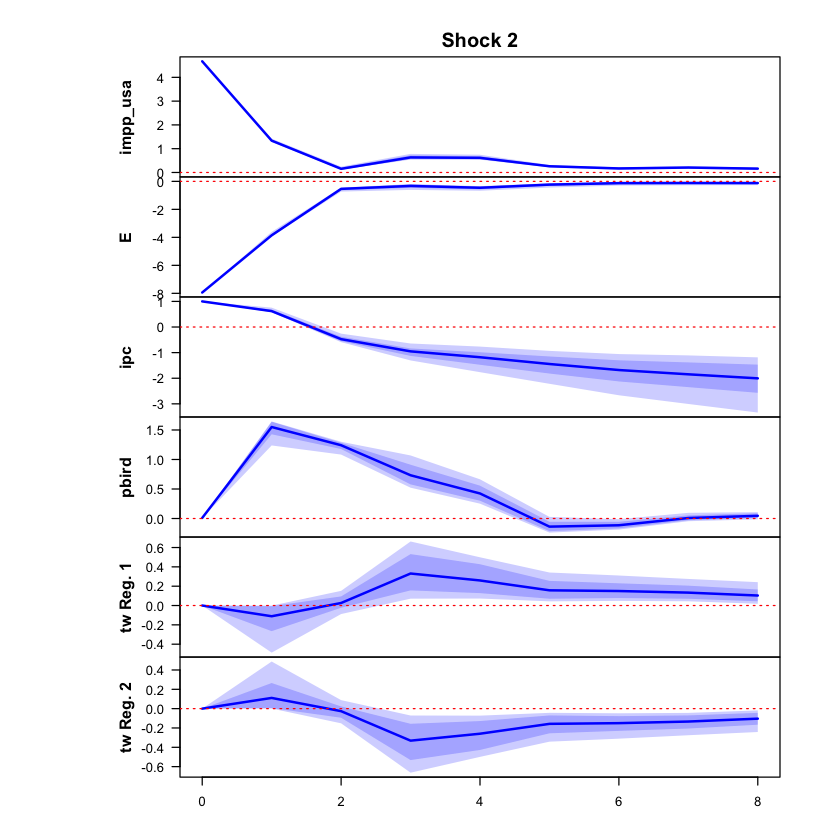

 >>> Linear IRF ( 1  shock units)


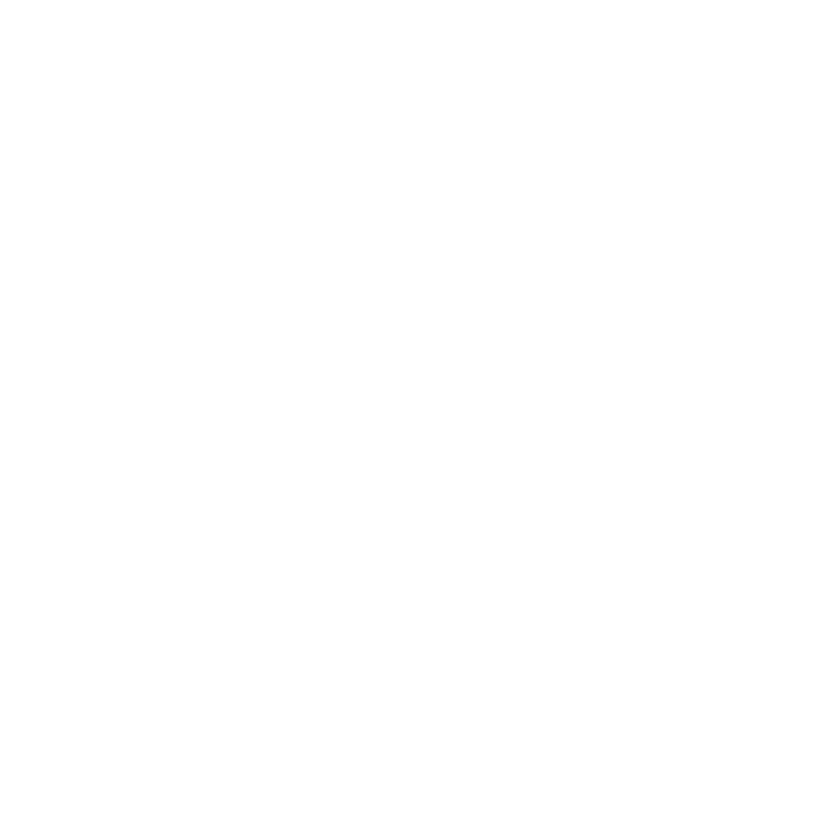

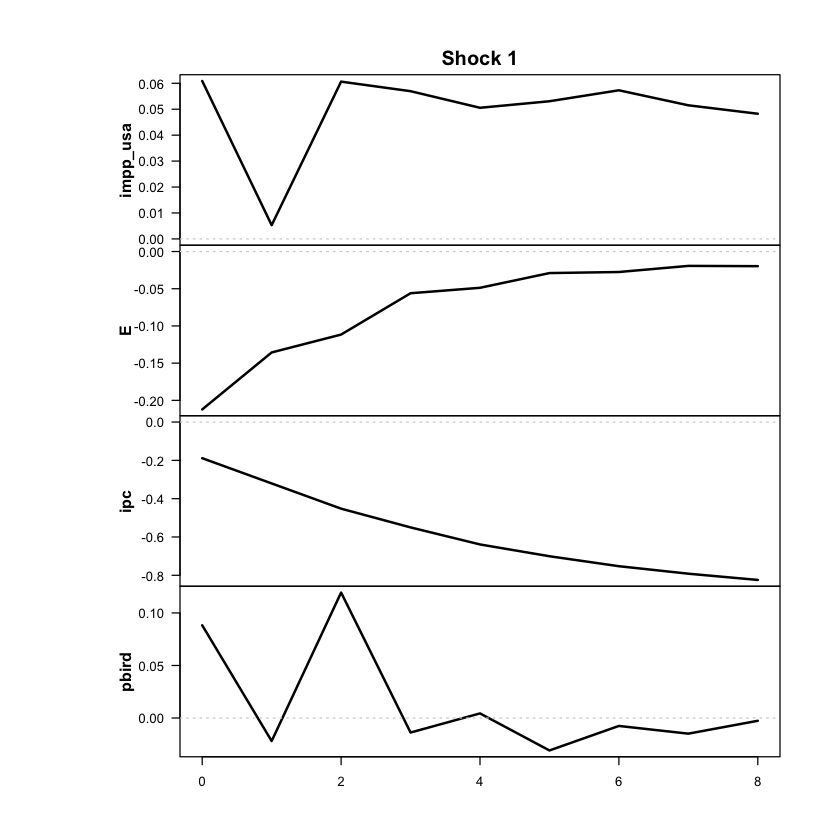

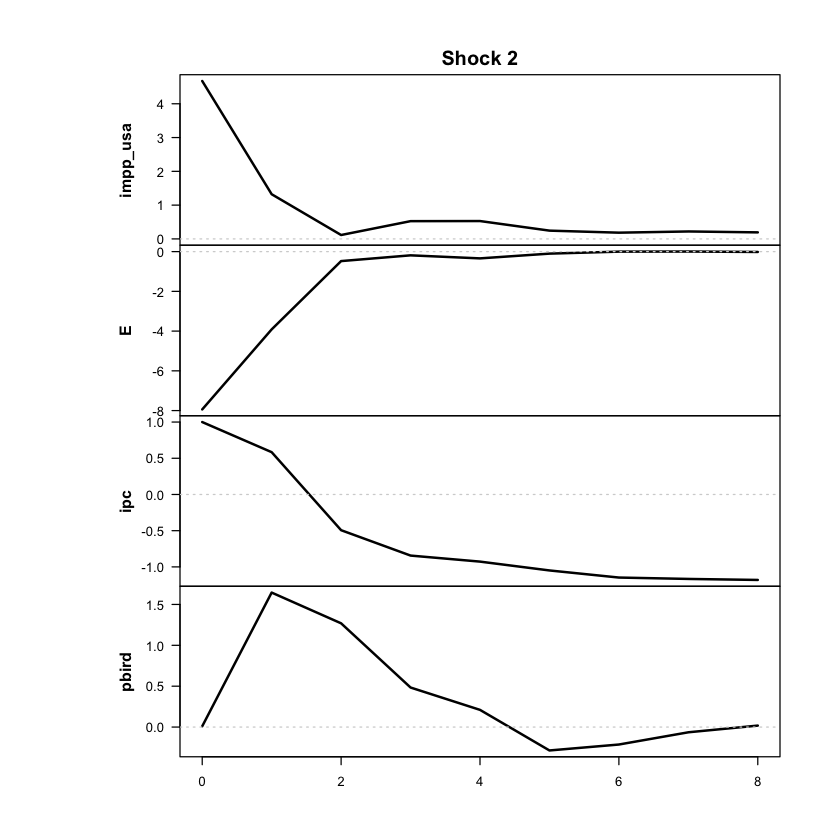

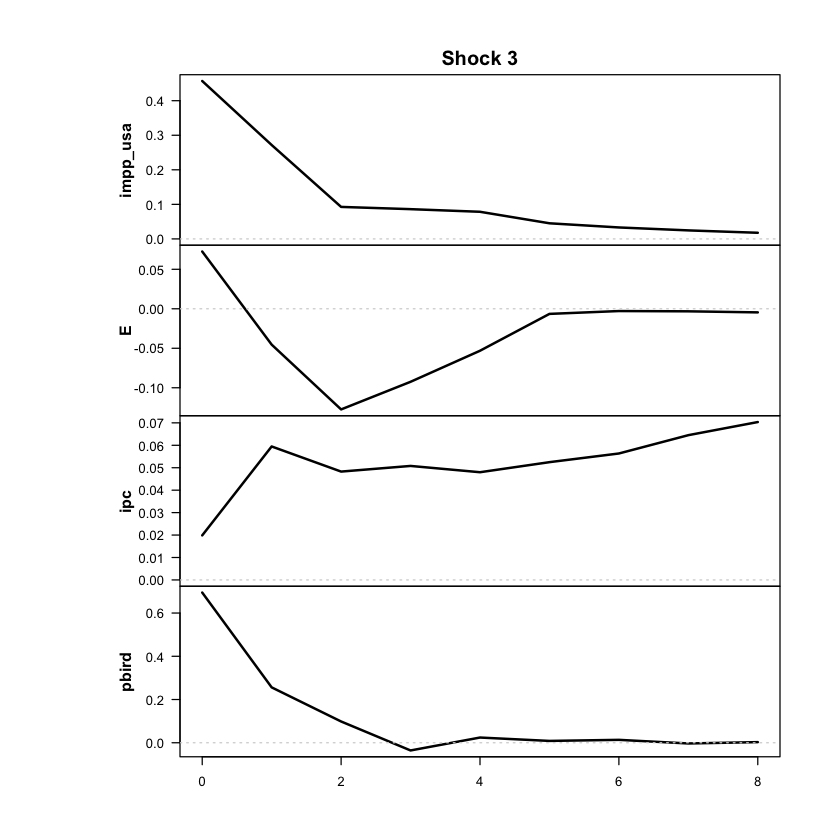

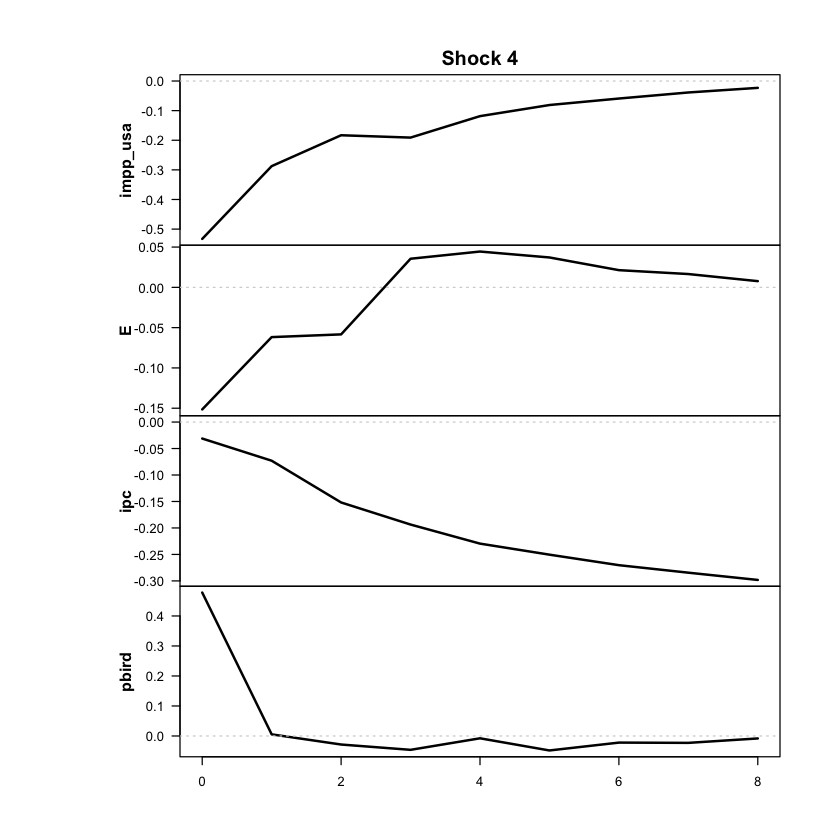

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



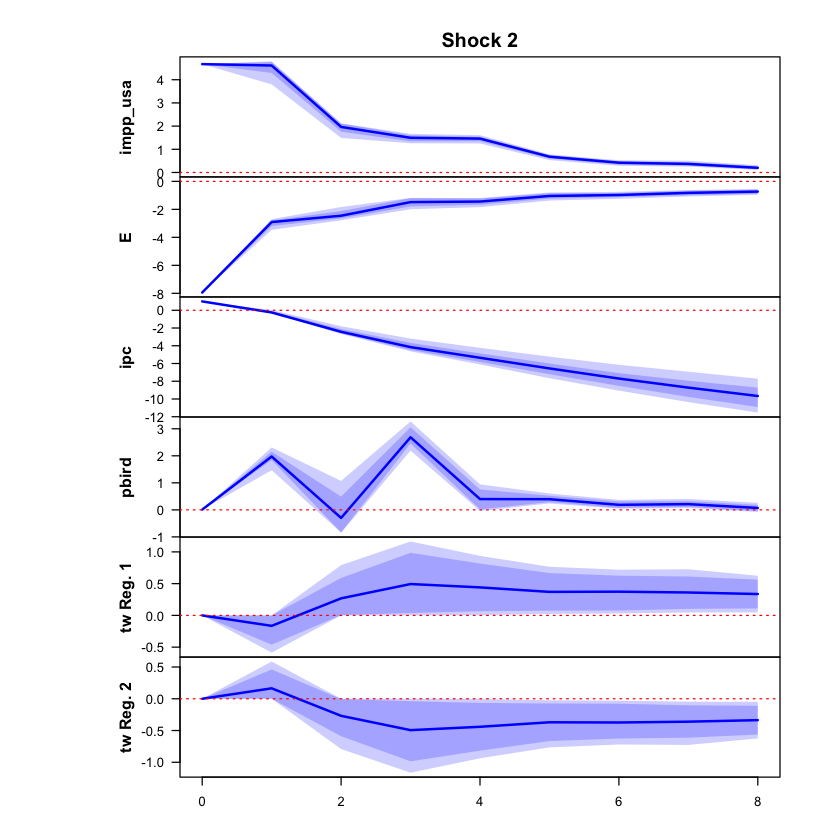

 >>> Linear IRF ( 1  shock units)


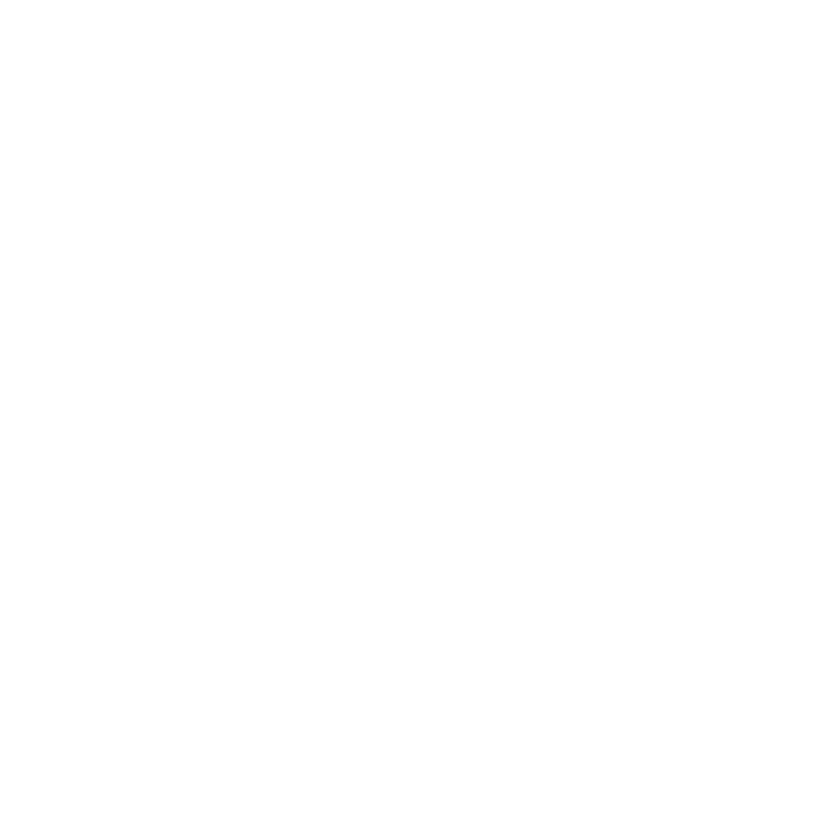

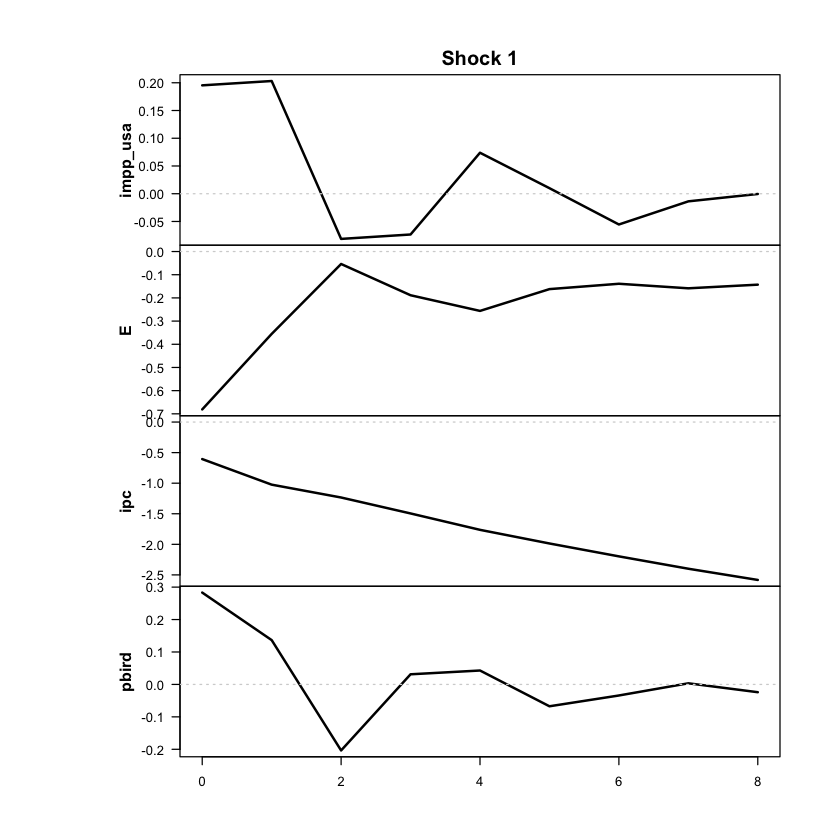

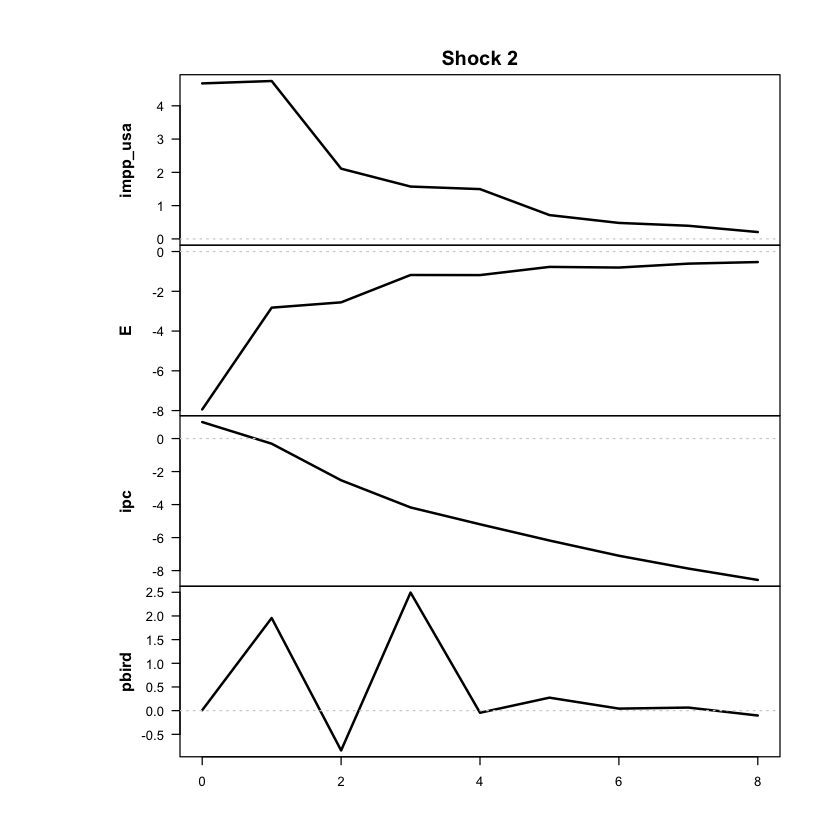

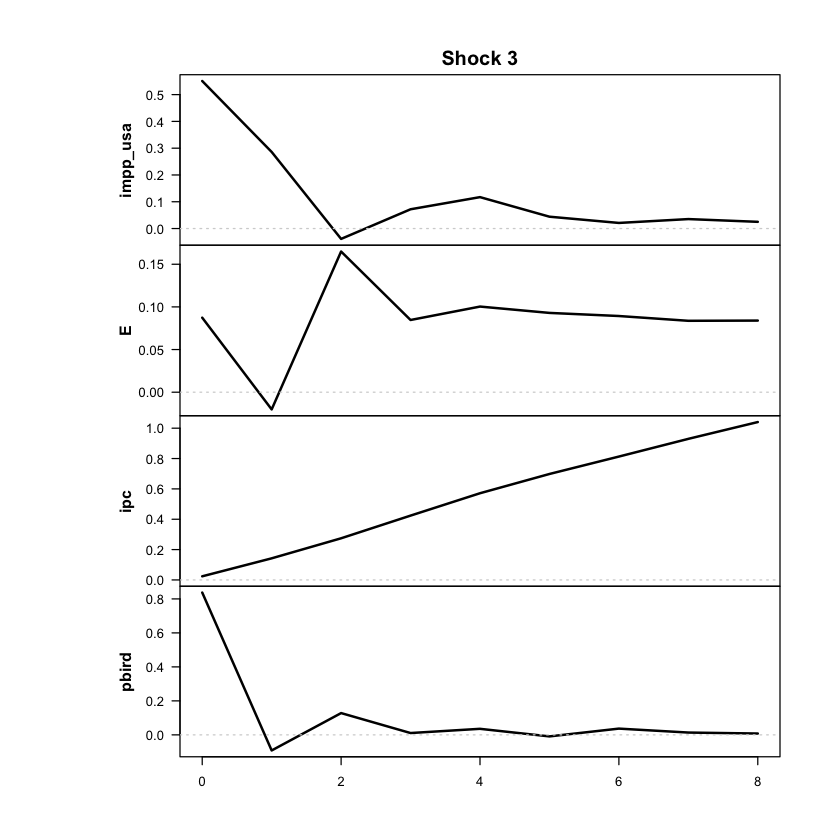

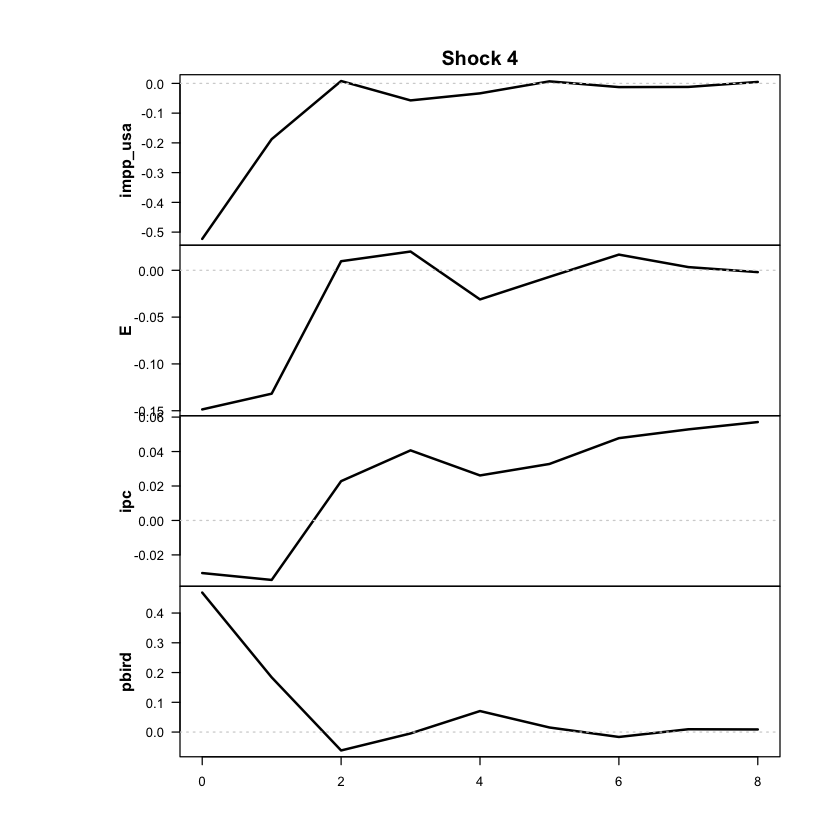

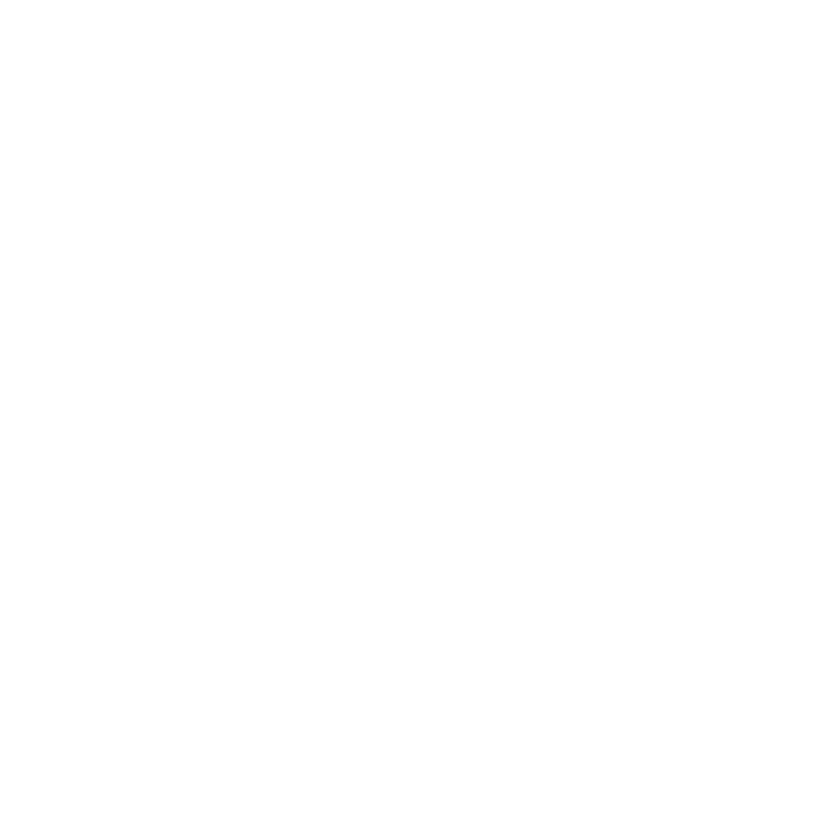

In [ ]:
res <- run_vlstar (
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 3,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [52]:
ic_vlstar_p3_cap <- criterios_info(res, "VLSTAR p=3 cap")
print(ic_vlstar_p3_cap)

          modelo regimenes parametros  loglik    AIC     HQ    BIC
1 VLSTAR p=3 cap         2        126 -999.68 2251.4 2436.9 2714.6


In [67]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: logistic | regímenes: 2 | rezagos: 3 | errores: Gaussian 
Umbral (c): 11.1 % trimestral ( 52 % anualizada) | gamma: 12.49 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 196 | régimen 2 = 96 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.57      0.91
E             3.78     24.76
ipc           4.45     27.60
pbird         0.88     -0.03


In [68]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest   loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1  -999.68            11.1 12.49         NA           196/96
             4  -999.68            11.1 12.48         NA           196/96
             7 -1024.58            25.4  1.57         NA           245/47
             8 -1044.27            26.3  1.49         NA           245/47
             9 -1048.79            23.2  1.47         NA           242/50
            10 -1049.98            30.1  1.35         NA           255/37
            11 -1050.58            20.7  1.33         NA           235/57
            12 -1053.65              33  1.28         NA           261/31
          

In [69]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 3, M = 2, d = 4, #parameters = 126, #observations = 292 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Weight params: 0.86 (location), 12.49 (scale) 
Regime means: 0.23, 0.31, 0.45, 0.36

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.17 ] + [  0.53  0.14  0.00  0.03 ] y1.1 + [  0.01 -0.03 -0.40 -0.07
2 y2   [ 0.19 ]   [ -0.08  0.46  0.14 -0.06 ] y2.1   [  0.02 -0.16  0.29 -0.11
3 y3   [ 0.08 ]   [  0.02  0.13  0.56  0.01 ] y3.1   [  0.00  0.06  0.11 -0.06
4 y4   [ 0.23 ]   [  0.19 -0.05  0.34  0.24 ] y4.1   [  0.00 -0.16 -0.69 -0.01
                A3                              Omega                     1/2
1 ] y1.2 + [  0.16  0.07  0.09  0.00 ] y1.3 + [  0.55  0.01  0.03  0.07 ]    
2 ] y2.2   [ -0.07 -0.05 -0.17  0.03 ] y2.3   [  0.01  0.23  0.03 -0.04 ]    
3 ] y3.2   [  0.02 -0.07  0.05  0.05 ] y3.3   [  0.03  0.03  0.04 -0.02 ]    
4

In [70]:
shock_vlstar_p3_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_p3_cap <- 2
shock_vlstar_p3_cap

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0012 -0.0045  0.0089 -0.0104
  E        -0.0324  0.0604  0.0111 -0.0232
  ipc      -0.0229 -0.0060  0.0024 -0.0038
  pbird     0.0021  0.0000  0.0163  0.0112

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.70    0.86    0.09    0.21 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.707  -0.100   0.218   0.163 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — vlstar p3 cap

Correr solo si el modelo pasó el diagnóstico.

In [71]:
out_impp_usa_vlstar_p3_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_p3_cap)

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 174 | régimen 2 = 80 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_bajo_original reg_alto_original
1         0           -0.1001           -0.1001
2         1           -0.0641            0.0205
3         2            0.0488            0.2315
4         3            0.1032            0.3969
5         4            0.1335            0.5123
6         5            0.1680            0.6261
7         6            0.2009            0.7348
8         7            0.2257            0.8318
9         8            0.2491            0.9230


In [72]:
out_impp_usa_vlstar_p3_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_p3_cap,
                      definicion = "acumulado")

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 174 | régimen 2 = 80 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_bajo_original reg_alto_original
1         0           -0.1001           -0.1001
2         1           -0.0441            0.0151
3         2            0.0304            0.1395
4         3            0.0623            0.2162
5         4            0.0768            0.2546
6         5            0.0940            0.2932
7         6            0.1102            0.3257
8         7            0.1219            0.3530
9         8            0.1323            0.3770


GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1001 -0.0002
         1 -0.0616 -0.0300
         2  0.0493 -0.0540
         3  0.0990 -0.0686
         4  0.1237 -0.0771
         5  0.1518 -0.0747
         6  0.1772 -0.0727
         7  0.1955 -0.0729
         8  0.2128 -0.0738

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.1001 -0.0002
         1  0.0237 -0.0384
         2  0.2398 -0.0329
         3  0.4100 -0.0844
         4  0.5289 -0.0923
         5  0.6471 -0.0996
         6  0.7596 -0.1031
         7  0.8607 -0.1074
         8  0.9545 -0.1089


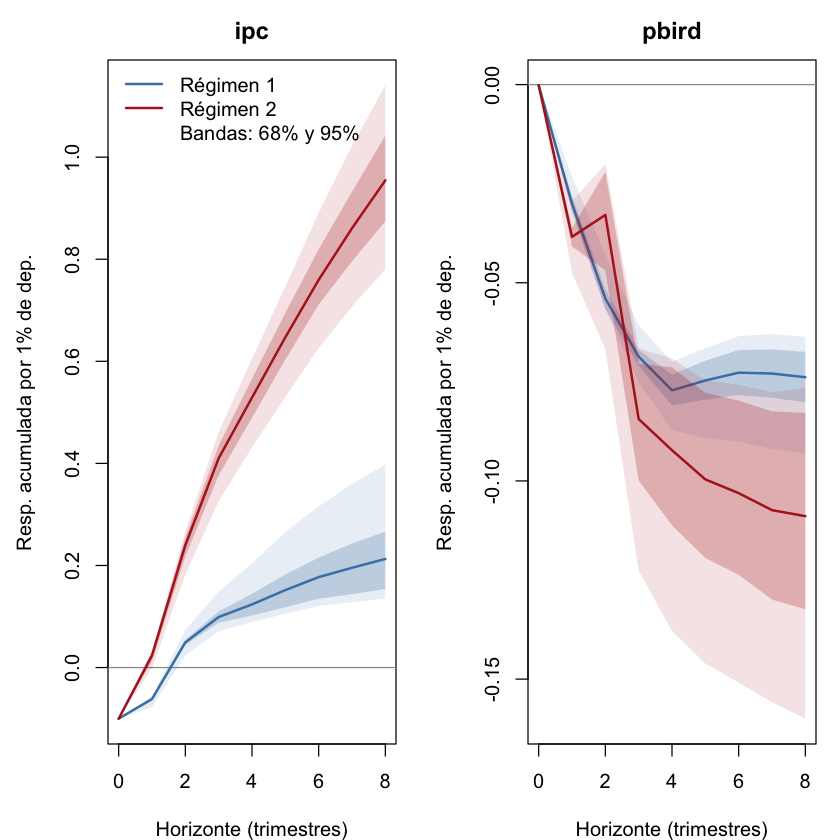

In [78]:
girf_impp_usa_vlstar_p3_cap <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_p3_cap,
                                        archivo = "girf_original_impp_usa_vlstar_p3_cap")

Parámetros usados -> c (escalado): 0.86 | gamma: 12.49 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.1049 | franja 10%-90%: 0.0835 a 0.1262 


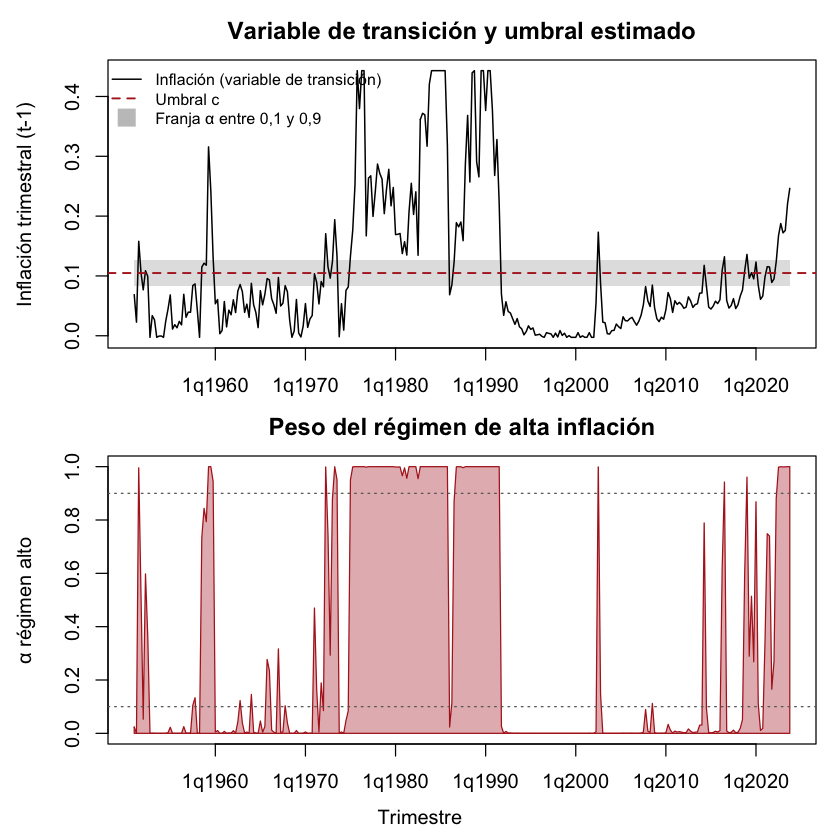

In [73]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_vlstar_p3_cap")

## TVAR, 3 regímenes, p = 2

Se cargó exitosamente modelos preguardados  threshold_tvar_2_3_500_20b09baa01f2f2bd27ff66072602abad.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


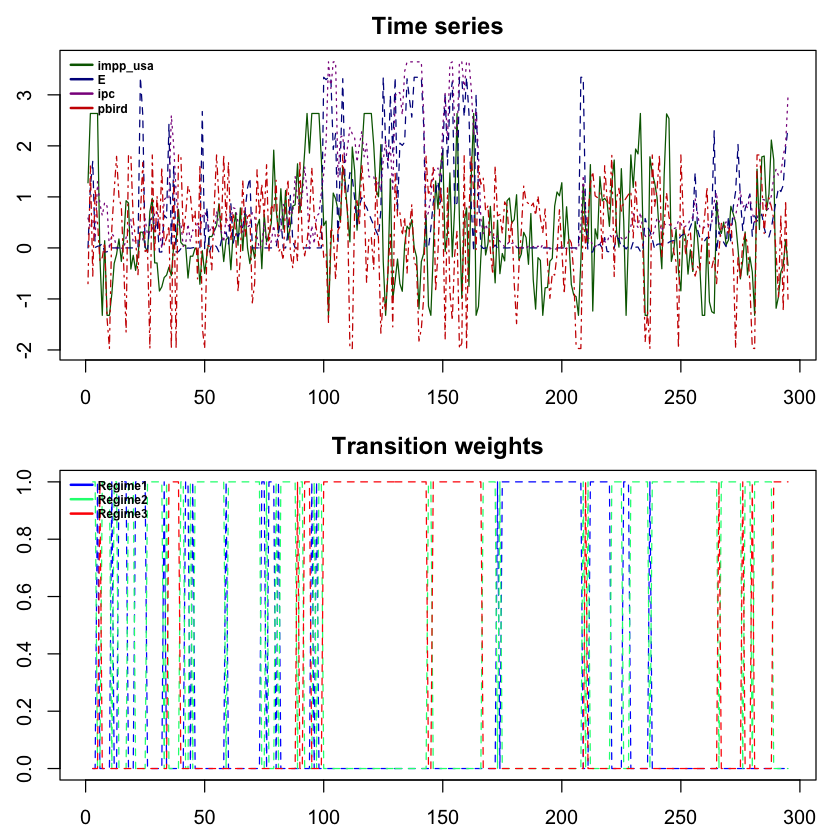

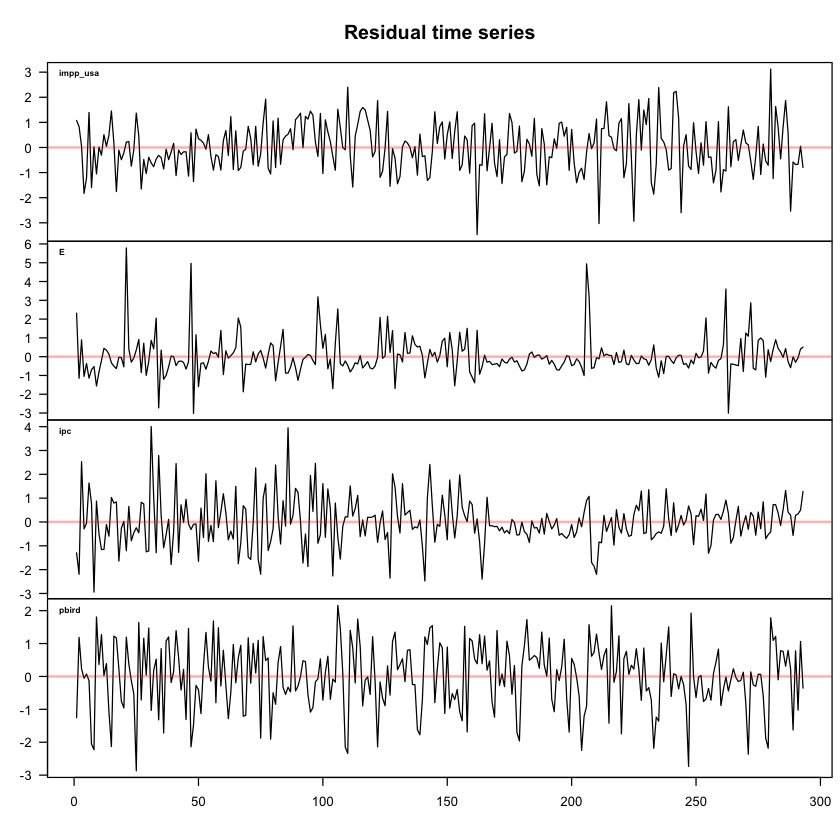

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



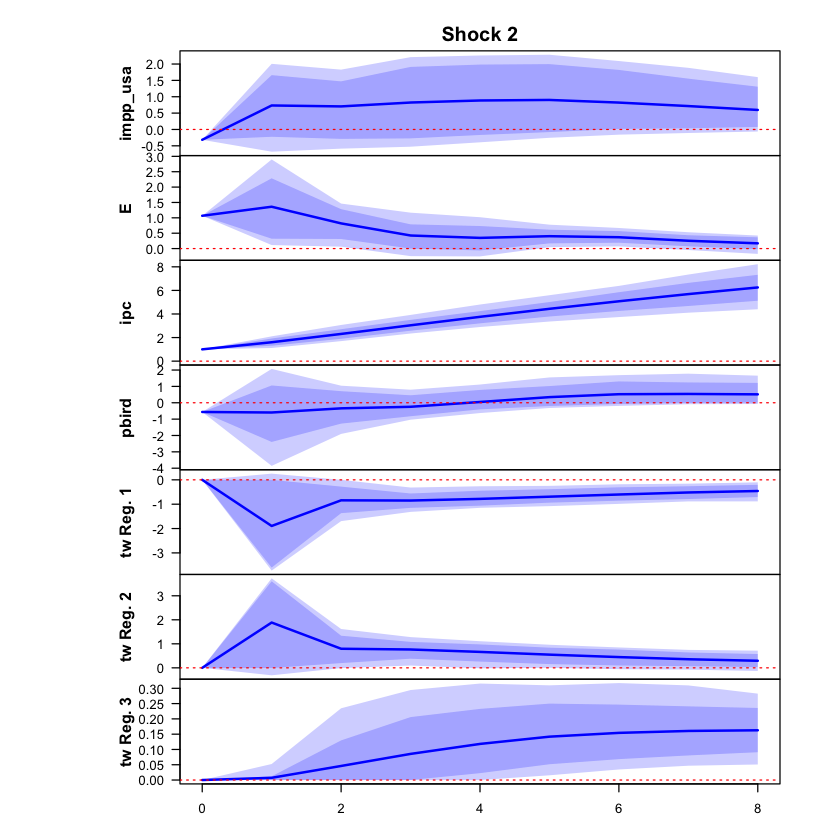

 >>> Linear IRF ( 1  shock units)


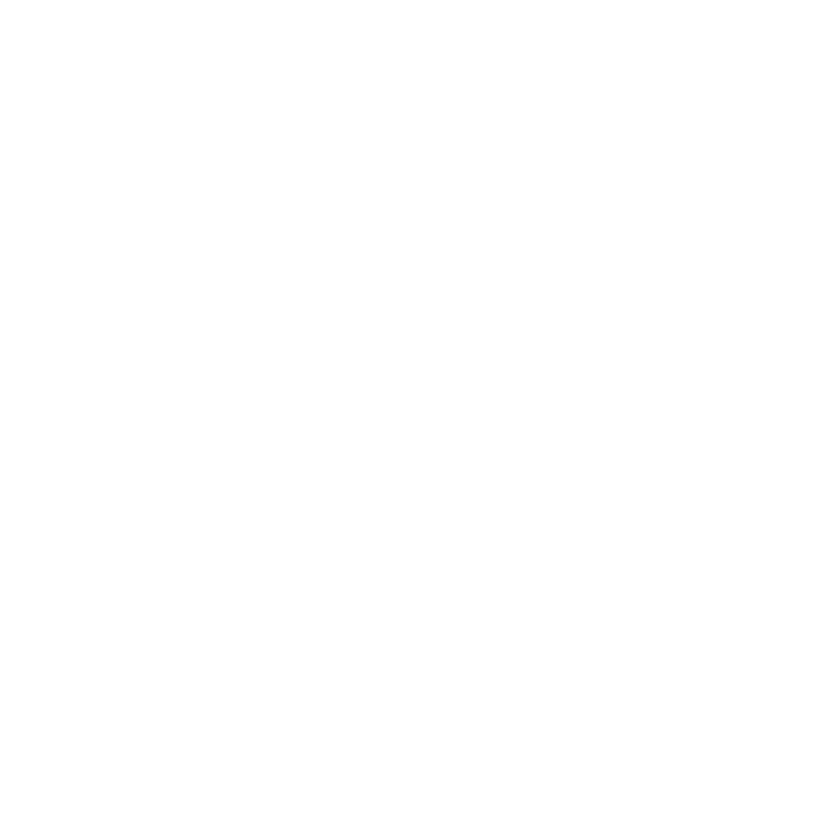

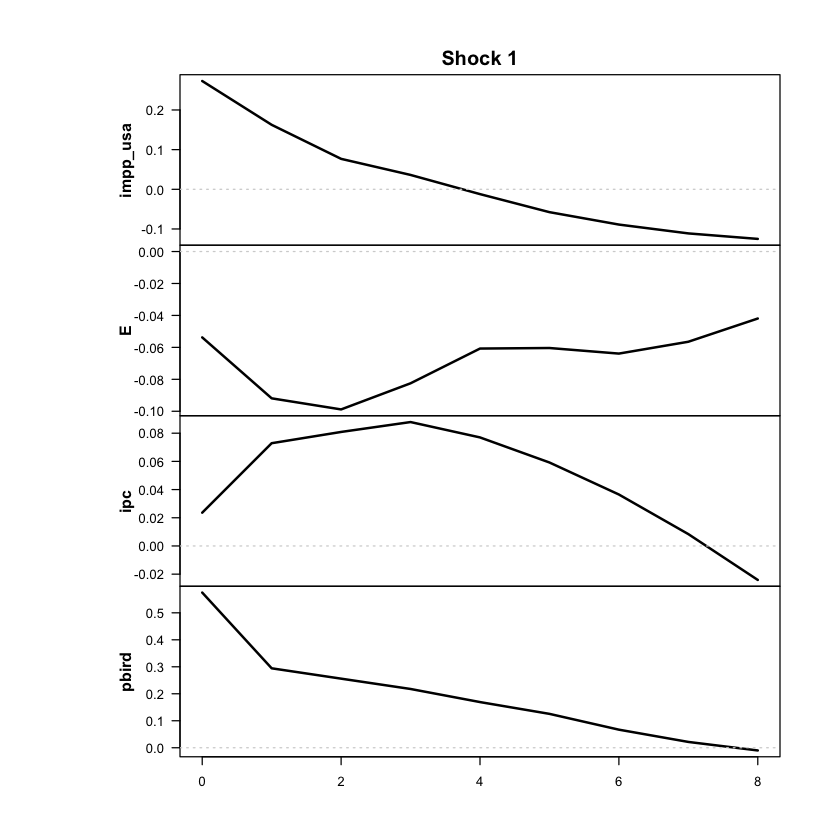

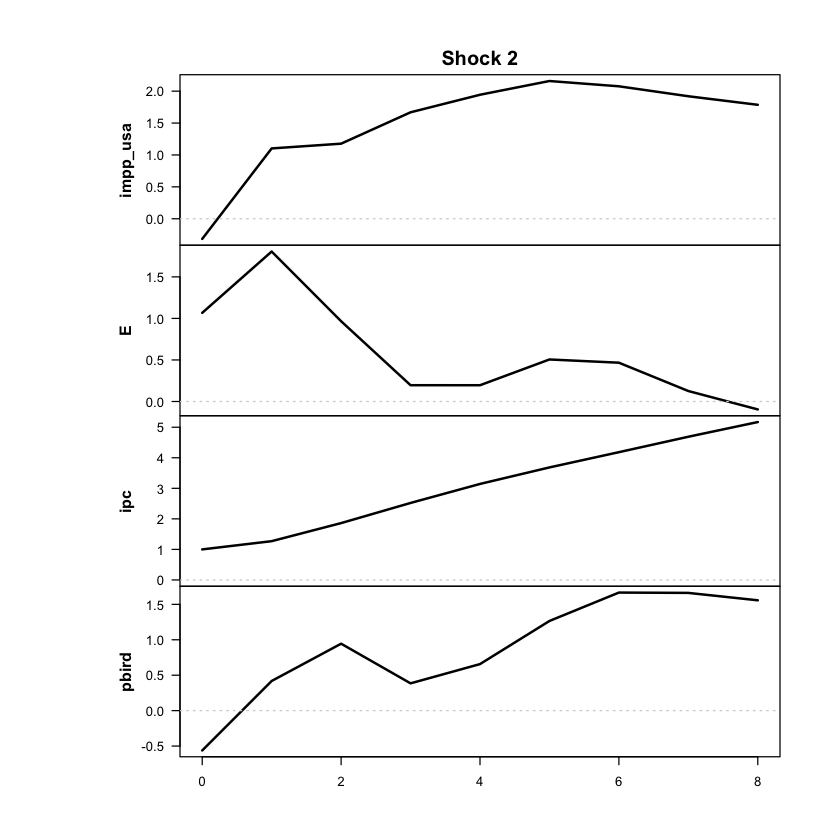

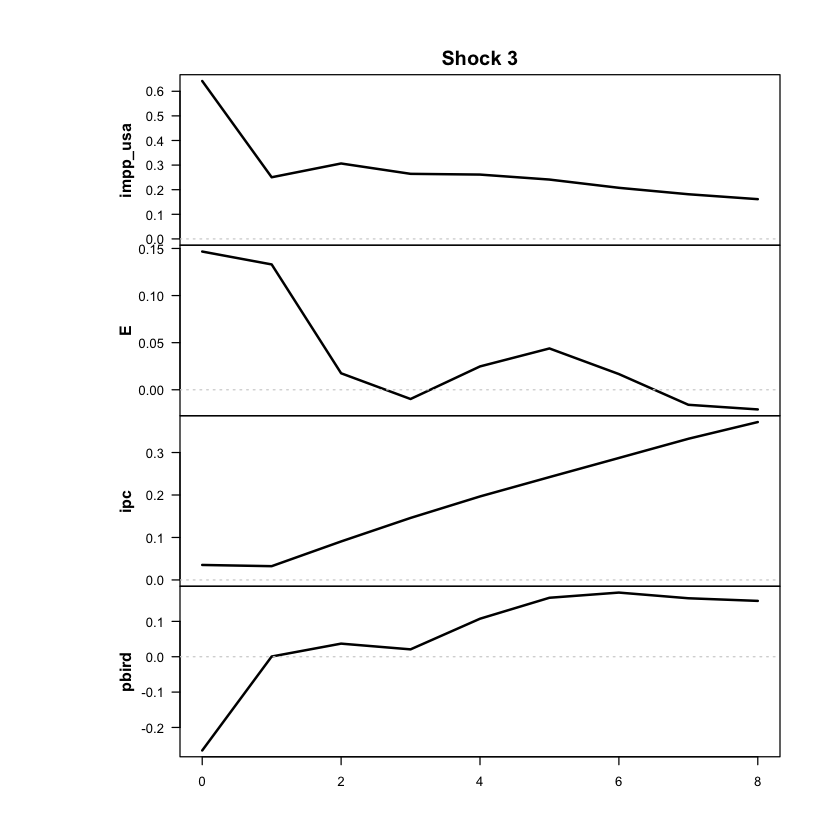

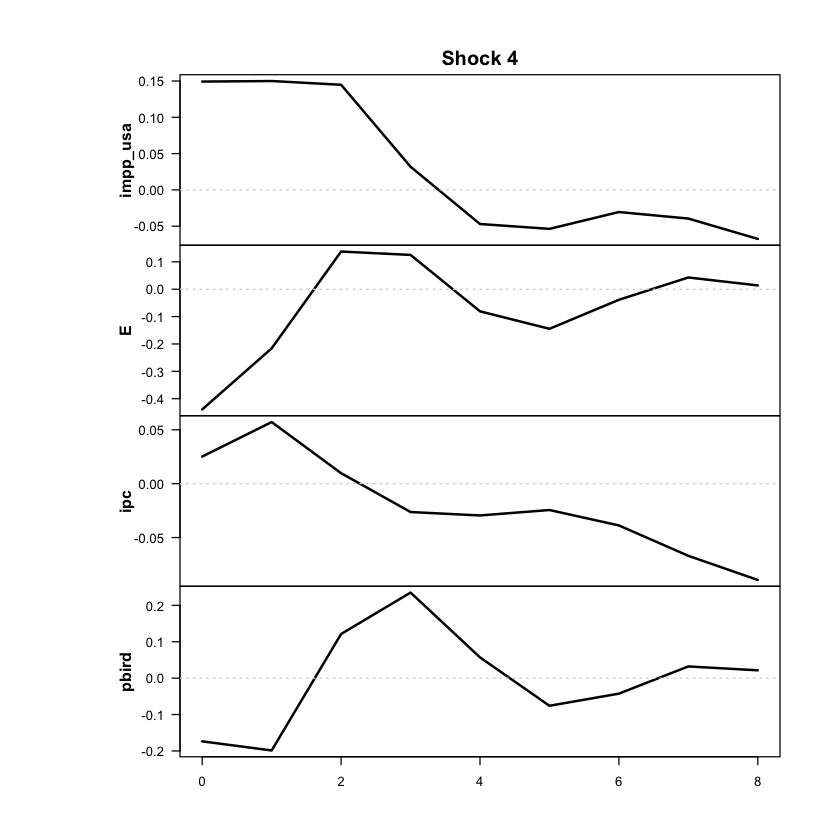

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



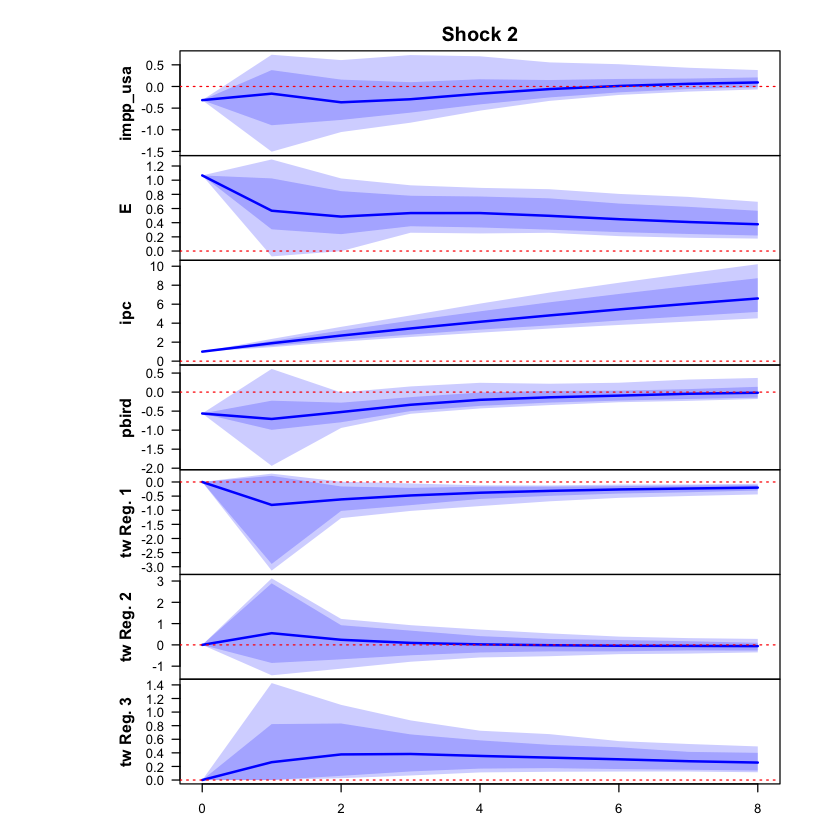

 >>> Linear IRF ( 1  shock units)


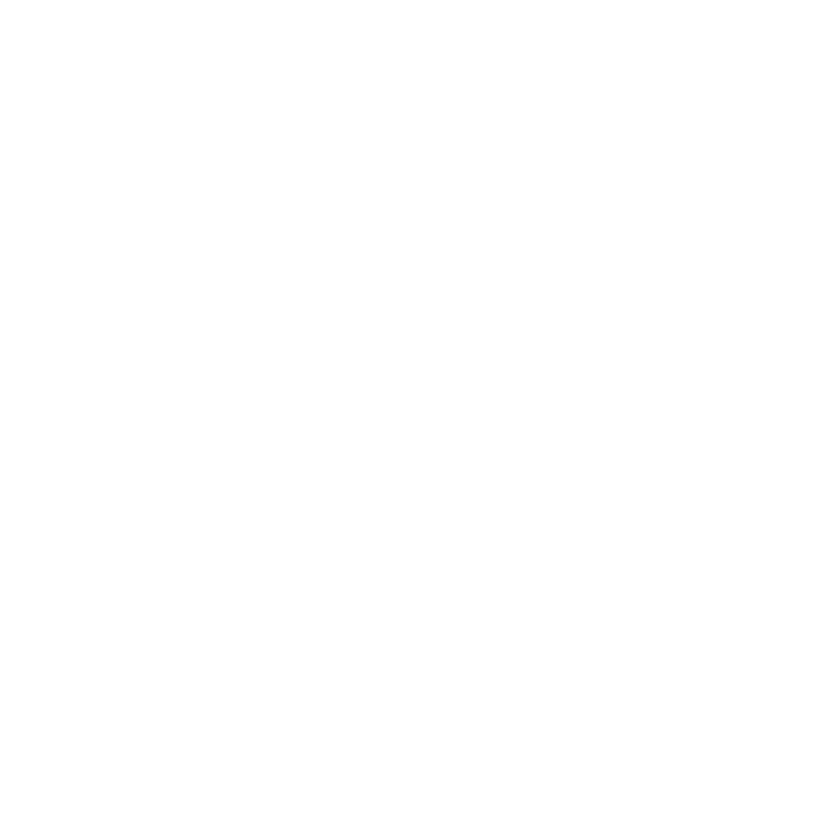

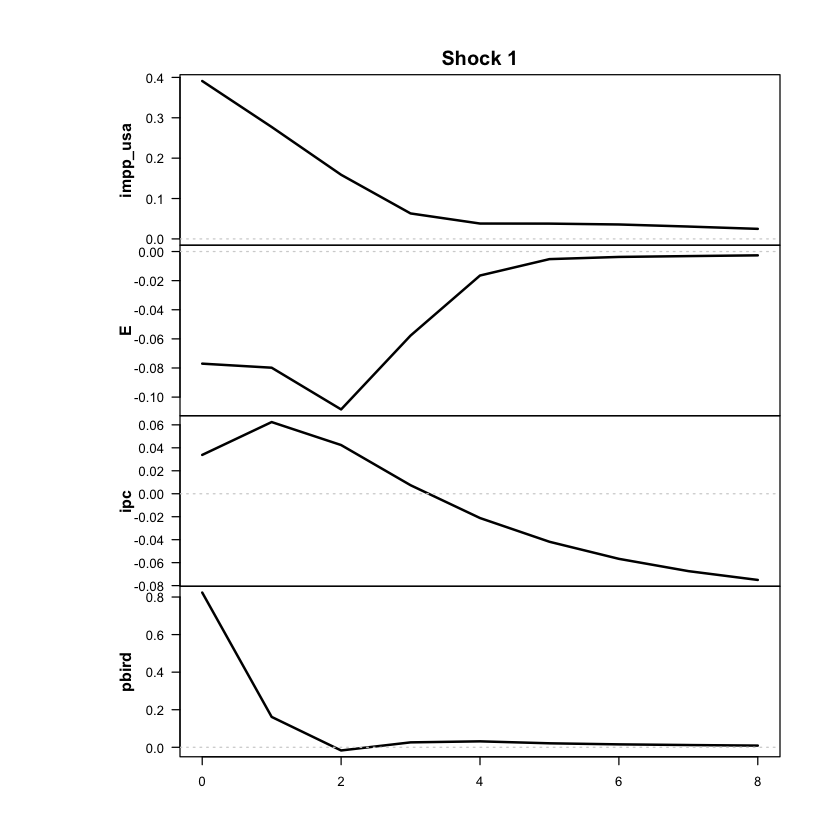

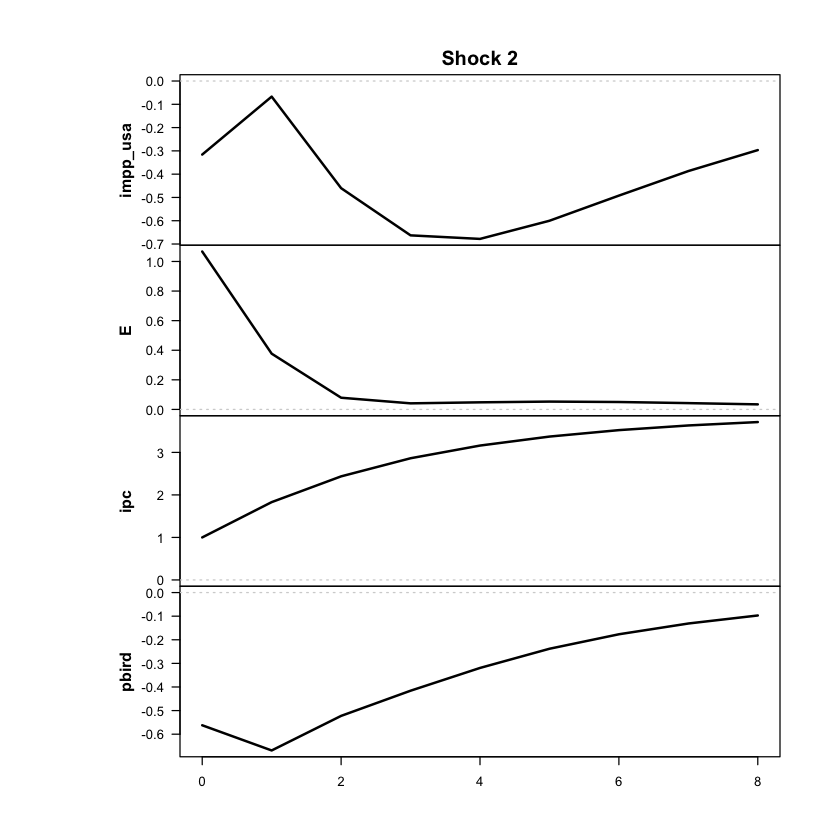

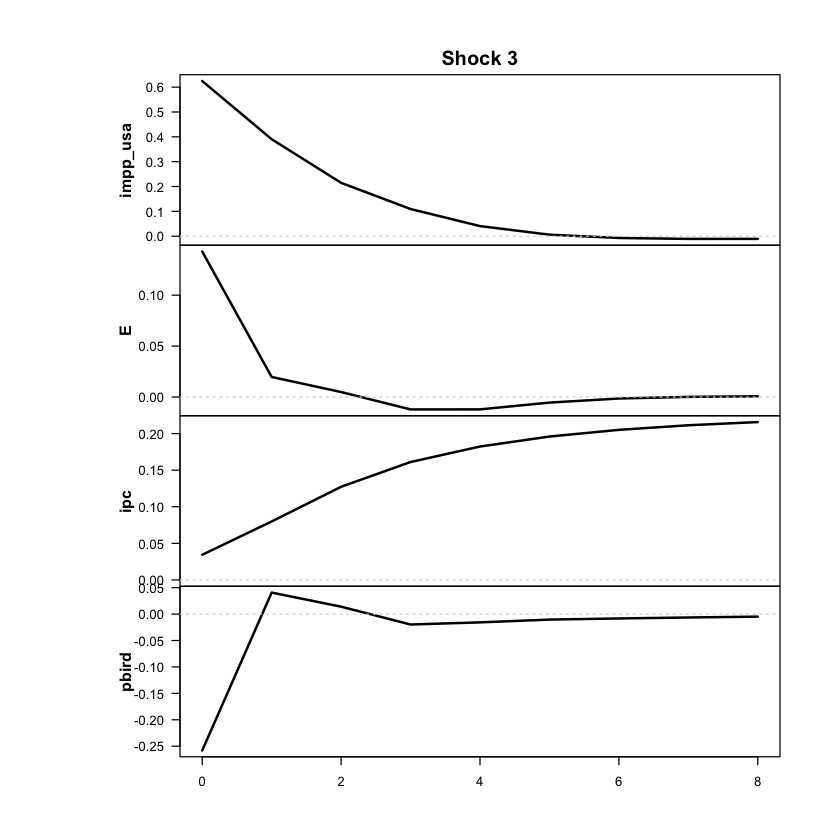

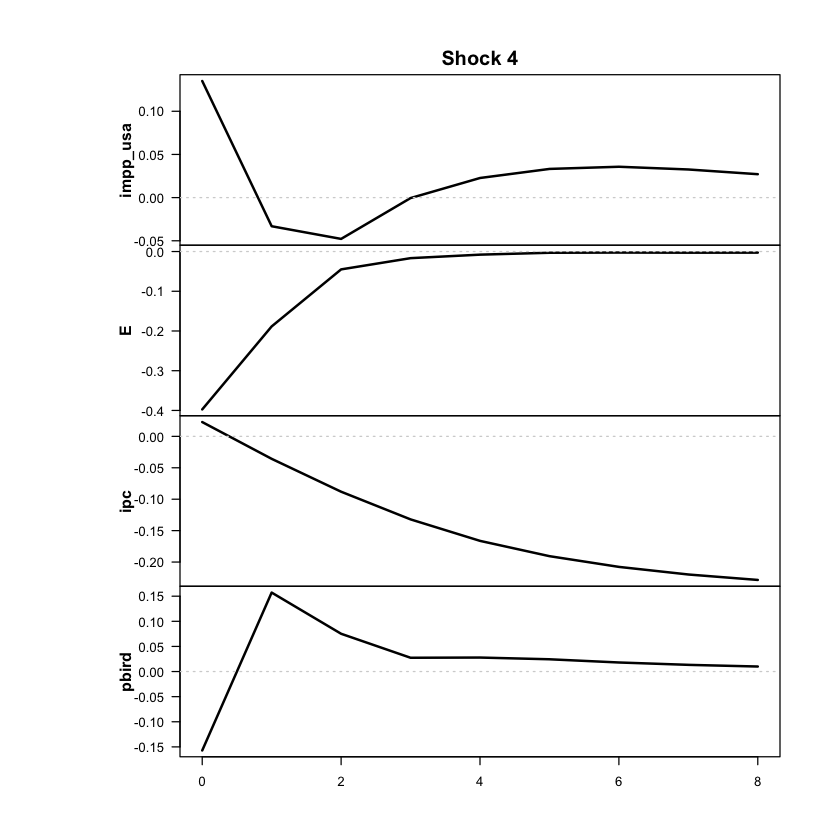

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



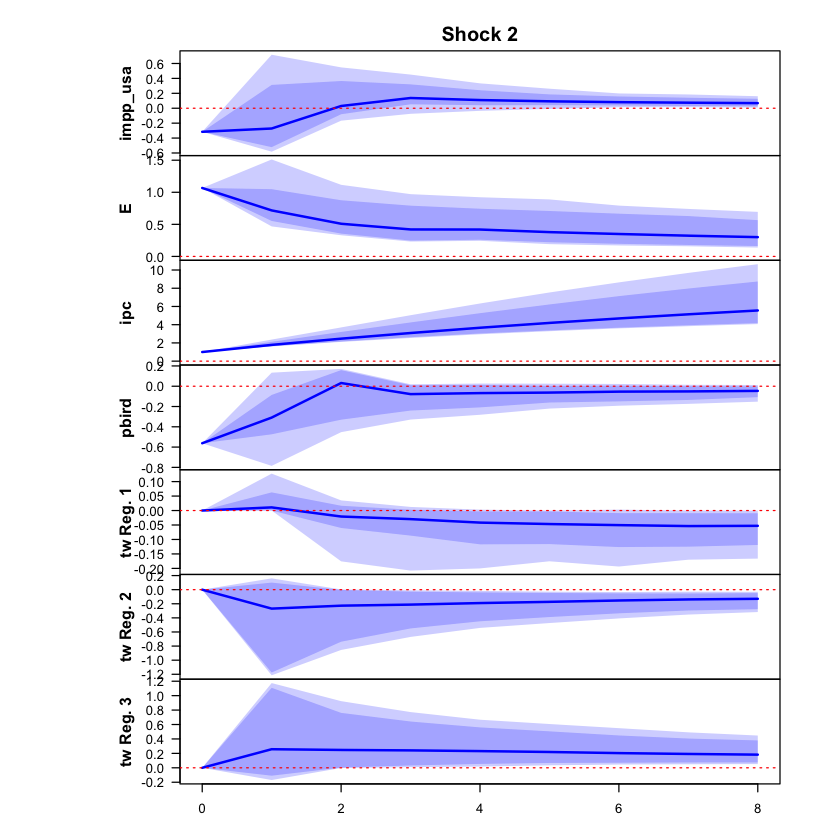

 >>> Linear IRF ( 1  shock units)


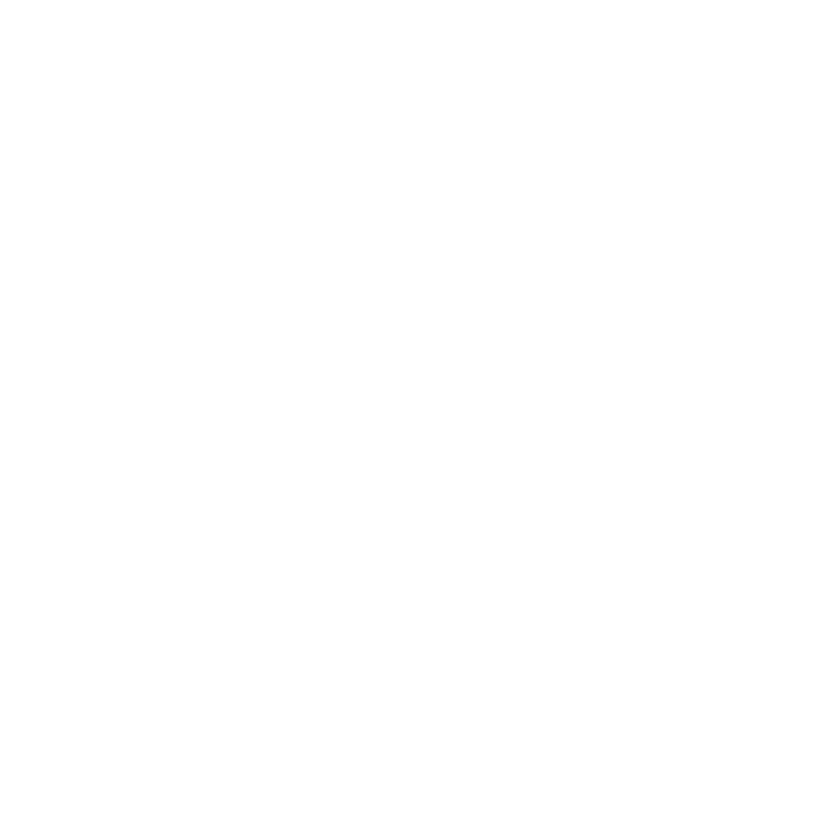

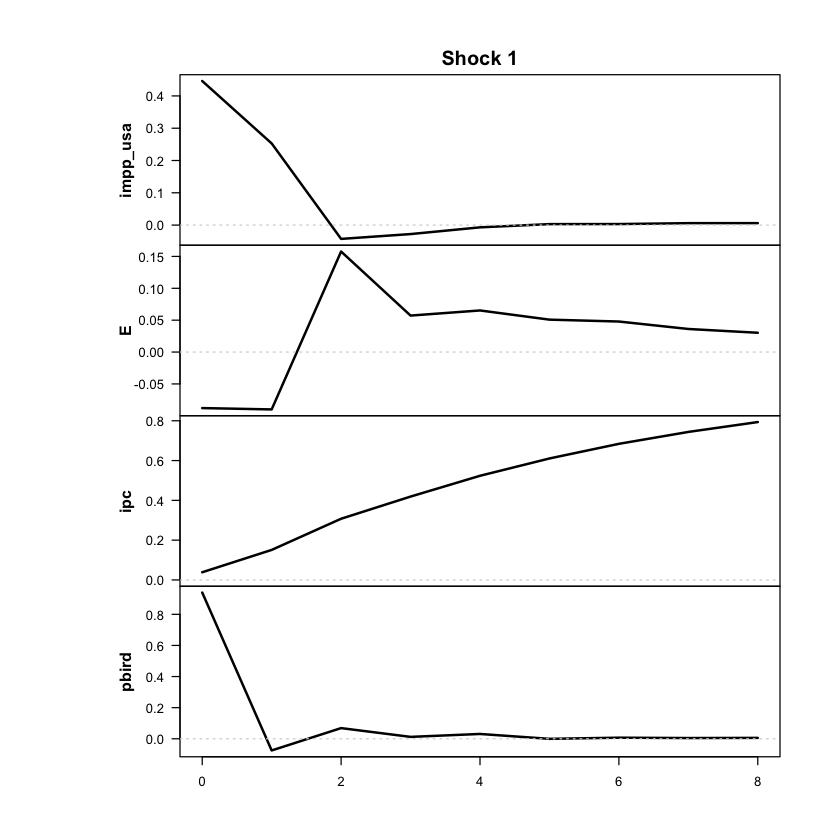

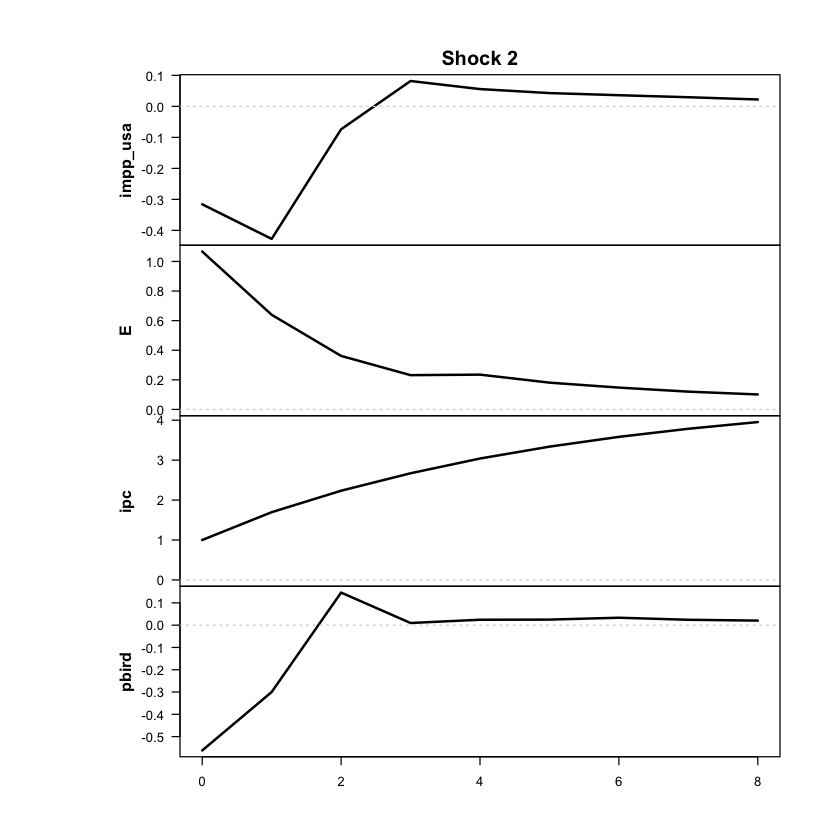

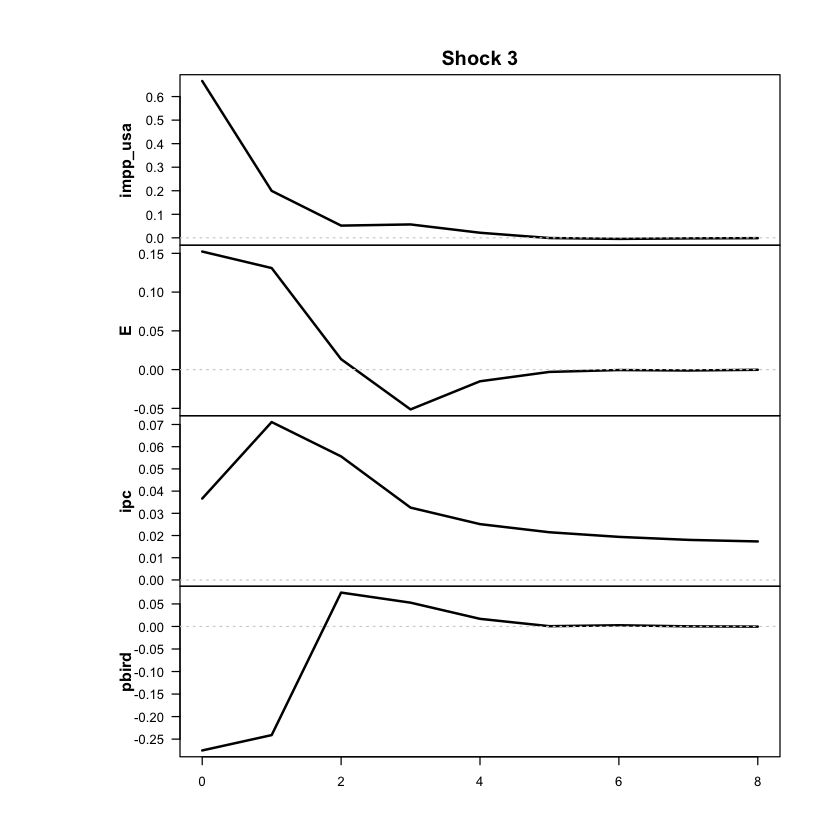

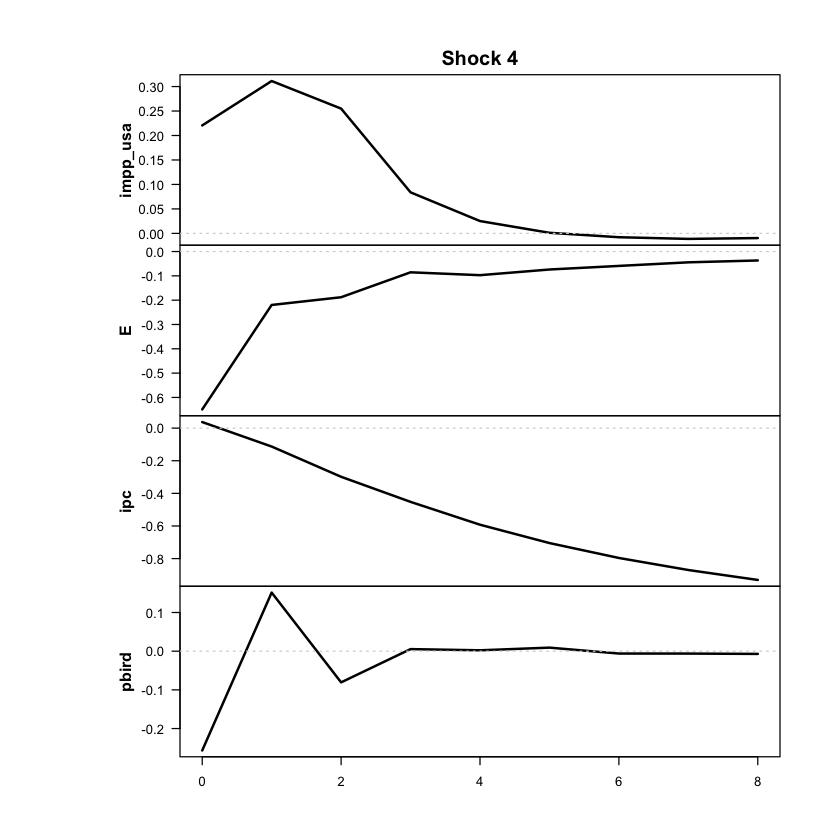

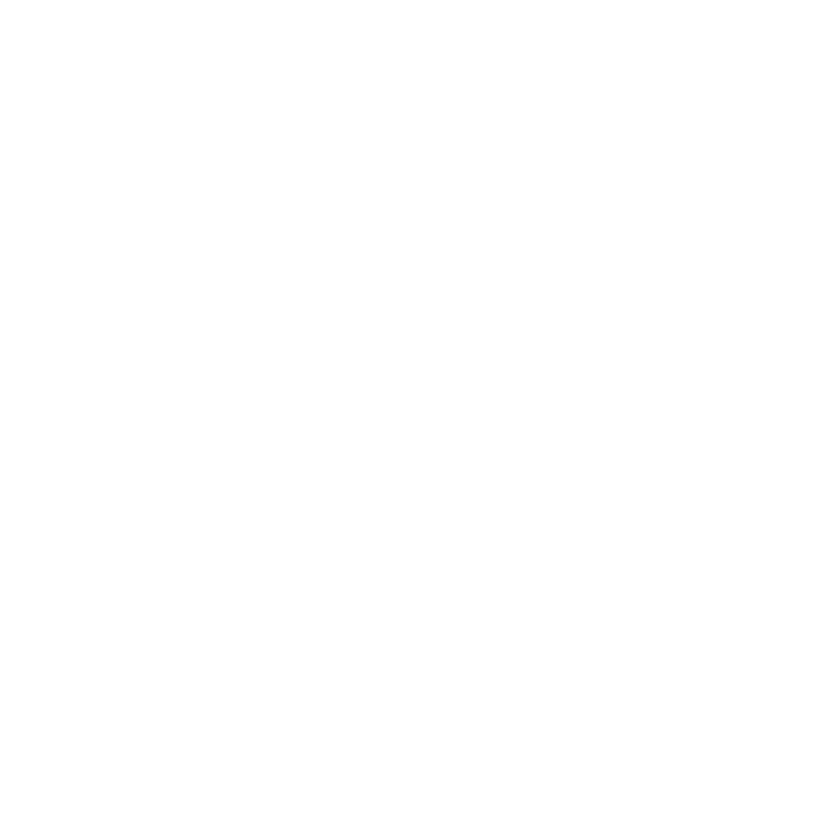

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [5]:
ic_tvar3_p2_cap <- criterios_info(res, "TVAR 3 reg p=2 cap")
print(ic_tvar3_p2_cap)

              modelo regimenes parametros  loglik    AIC     HQ  BIC
1 TVAR 3 reg p=2 cap         3        140 -972.88 2225.8 2432.1 2741


In [6]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 3 | rezagos: 2 | errores: Gaussian 
Umbrales: 2.5% trimestral (10% anualizada) | 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 72 | régimen 2 = 135 | régimen 3 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.46      0.63      1.02
E             2.36      4.83     27.25
ipc           1.88      6.35     29.68
pbird         0.69      0.89     -0.03


In [7]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -972.88      2.5 / 12.5    NA         NA        72/135/86
             3 -973.15      2.4 / 12.5    NA         NA        71/136/86
             5 -973.61      2.5 / 12.4    NA         NA        72/134/87
             6 -978.50      2.5 / 12.5    NA         NA        74/133/86
             7 -978.71      6.9 / 14.1    NA         NA        155/59/79
             8 -979.42      2.4 / 12.5    NA         NA        70/137/86
            10 -979.99      7.1 / 14.3    NA         NA        156/59/78
 trim_reg_alto trim_transicion raiz_casi_unit cov_casi_singular descartar
           135    

In [8]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 3, d = 4, #parameters = 140, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.20 
Regime means: 1.66, 0.33, 0.50, 1.45

   Y      phi0          A1                                 A2                  
1 y1 = [  0.08 ] + [  0.36 -0.15  1.40  0.04 ] y1.1 + [  0.22  0.15  0.43 -0.24
2 y2   [  0.18 ]   [ -0.04  0.59  1.09 -0.13 ] y2.1   [ -0.03 -0.44  0.09 -0.12
3 y3   [  0.07 ]   [  0.01 -0.07  0.38  0.06 ] y3.1   [  0.01  0.20  0.33 -0.06
4 y4   [ -0.07 ]   [  0.10  0.32  0.38  0.48 ] y4.1   [  0.08 -0.56  0.61  0.08
             Omega                     1/2     
1 ] y1.2 + [  0.50  0.02  0.02 -0.03 ]     eps1
2 ] y2.2   [  0.02  0.28  0.04  0.01 ]     eps2
3 ] y3.2   [  0.02  0.04  0.03 -0.01 ]     eps3
4 ] y4.2   [ -0.03  0.01 -0.01  0.45 ]     eps4

Regime 2 
Upper threshold: 0.97 
Regime means: 0.30, 0.31, 0.48, 0.39

   Y     phi0      

In [58]:
shock_tvar3_p2_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar3_p2_cap <- 2
shock_tvar3_p2_cap

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0053  0.0011  0.0125  0.0029
  E        -0.0082 -0.0285  0.0224 -0.0671
  ipc       0.0029 -0.0213  0.0043  0.0031
  pbird     0.0135  0.0023 -0.0062 -0.0041

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.08    0.67    0.21    0.89 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
 -0.349   0.745   0.191  -0.046 

>>> Shock sugerido como cambiario: 4 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 4

### ERPT — tvar3 p2 cap

Correr solo si el modelo pasó el diagnóstico.

In [10]:
out_impp_usa_tvar3_p2_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p2_cap)

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 6.9%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 72 | régimen 2 = 135 | régimen 3 = 86 
Shock usado:4| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0456        -0.0456        -0.0456
2         1        -0.0520         0.0442         0.1224
3         2         0.0090         0.1548         0.3326
4         3         0.0672         0.2707         0.5222
5         4         0.1072         0.3839         0.7032
6         5         0.1417         0.4918         0.8673
7         6         0.1816         0.5947         1.0159
8         7         0.2224         0.6884         1.1525
9         8         0.2622         0.7736         1.2792

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0456       -0.0456       -0.0456
2         1       -0.0638        0

In [11]:
out_impp_usa_tvar3_p2_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p2_cap,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 6.9%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 72 | régimen 2 = 135 | régimen 3 = 86 
Shock usado:4| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0456        -0.0456        -0.0456
2         1        -0.0346         0.0305         0.0908
3         2         0.0050         0.0974         0.2047
4         3         0.0467         0.1622         0.2933
5         4         0.0717         0.2154         0.3606
6         5         0.0880         0.2586         0.4123
7         6         0.1093         0.2976         0.4530
8         7         0.1329         0.3315         0.4867
9         8         0.1551         0.3613         0.5154

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0456       -0.0456       -0.0456
2         1       -0.0425        0

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 6.9%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!

GIRF del régimen 3...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0456  0.0607
         1 -0.0104  0.0622
         2  0.0748  0.0148
         3  0.1566 -0.0223
         4  0.2216 -0.0288
         5  0.2809 -0.0198
         6  0.3462 -0.0136
         7  0.4134 -0.0115
         8  0.4757 -0.0064

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0456  0.0607
         1  0.0468  0.0205
         2  0.1567 -0.0126
         3  0.2702 -0.0314
         4  0.3771 -0.0386
         5  0.4790 -0.0412
         6  0.5769 -0.0426
         7  0.6701 -0.0443
         8  0.7574 -0.0445

+++ Régimen 3 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc  pbird
         0 -0.0456 0.0607
         1  0.1252 0.0242
         2  0.3379 0.0334
         3  0.5298 0.0266
         4  0.7166 0.0209
         5  0.88

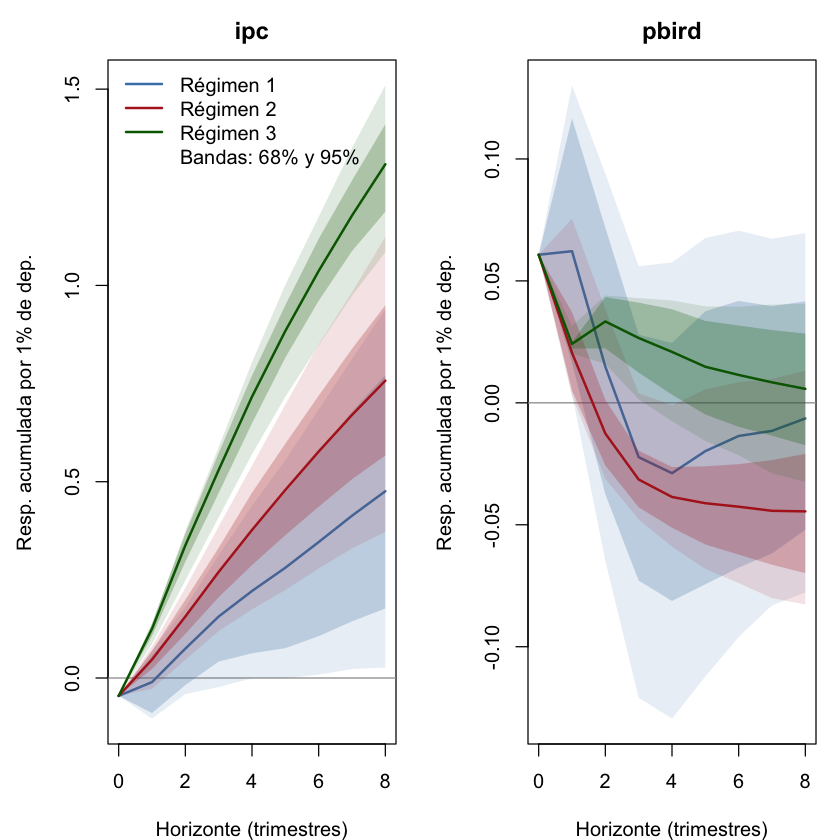

In [59]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                       shock_num = shock_tvar3_p2_cap, regimenes = 1:3,
                       archivo = "girf_original_impp_usa_tvar3_p2_cap")

In [60]:
ls(pattern = "^out_impp_usa_tvar3_p2_cap")
out_impp_usa_tvar3_p2_cap_acum$chequeo

[1] "out_impp_usa_tvar3_p2_cap"      "out_impp_usa_tvar3_p2_cap_acum"

horizonte,reg_1_original,reg_2_original,reg_3_original
<int>,<dbl>,<dbl>,<dbl>
0,-0.045554114,-0.04555411,-0.04555411
1,-0.034556965,0.03049237,0.09075361
2,0.005038477,0.09743087,0.20466603
3,0.046707221,0.16220431,0.29333696
4,0.071706546,0.21544293,0.36064176
5,0.088019933,0.25855186,0.41229319
6,0.109267626,0.29758222,0.45304912
7,0.132910919,0.33152413,0.48668604
8,0.155070692,0.36125619,0.51538194


Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         4          0.072          0.215          0.361
Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         4          0.107          0.384          0.703


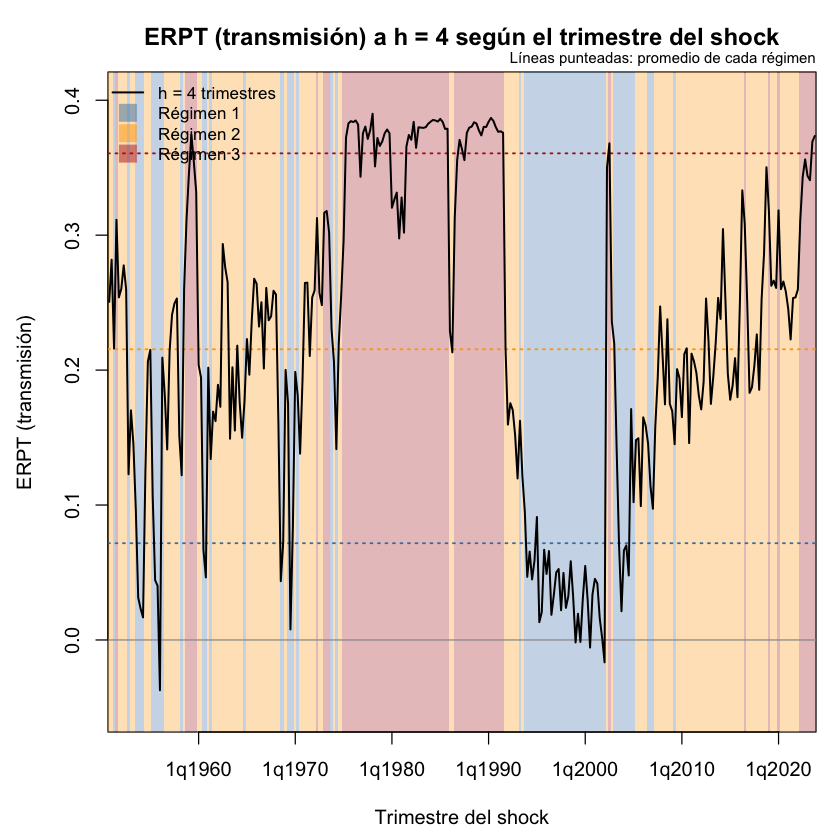

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         8          0.155          0.361          0.515


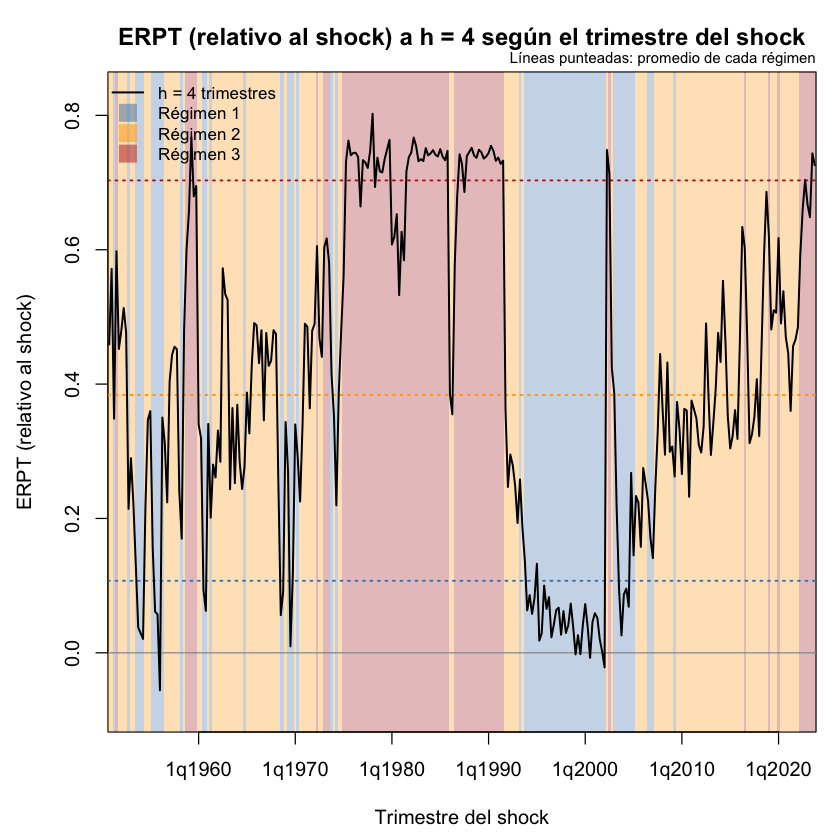

Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         8          0.262          0.774          1.279


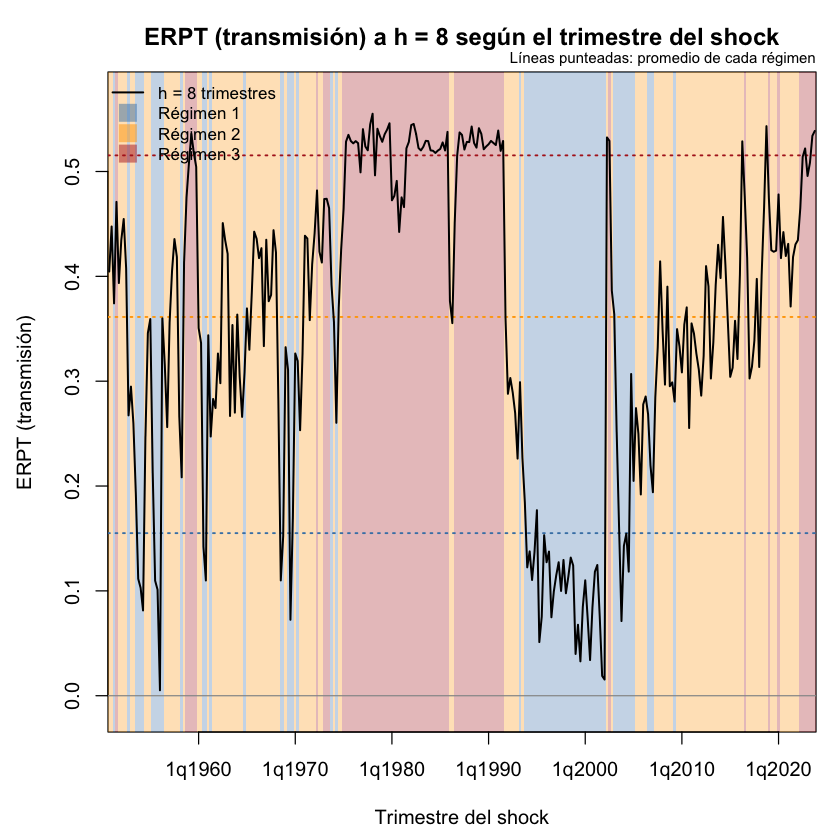

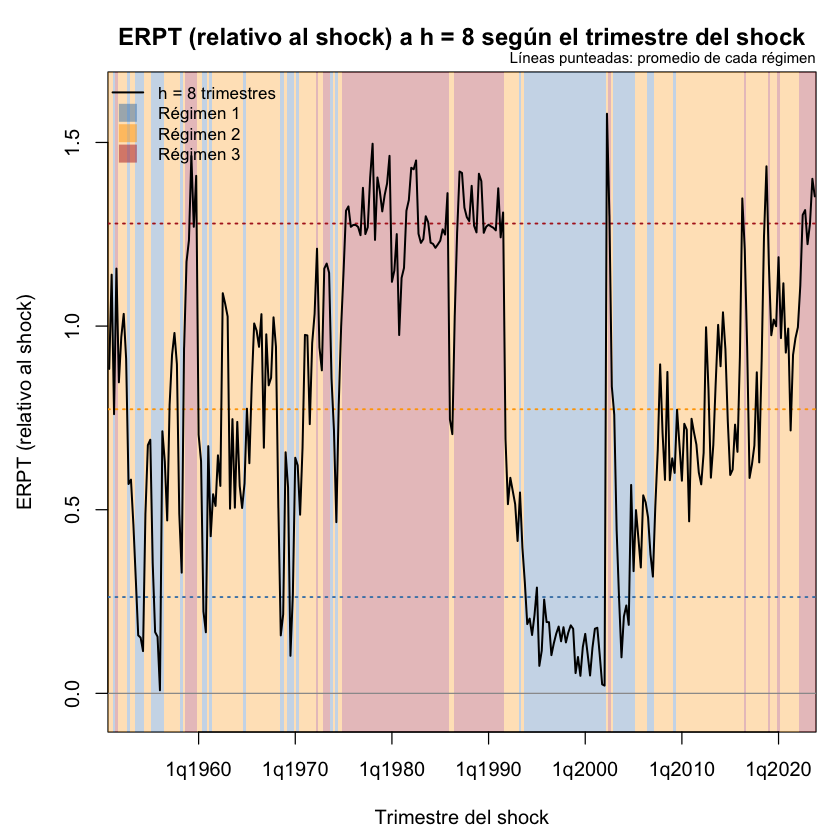

In [61]:
for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(out_impp_usa_tvar3_p2_cap_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p2_cap_acum_h", h))
  graficar_erpt_2d_bandas(out_impp_usa_tvar3_p2_cap, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p2_cap_h", h))
}

Umbrales (inflación trimestral de t-1): 2.5% trimestral (10% anualizada) | 12.5% trimestral (60% anualizada) 
Trimestres por régimen: régimen 1 = 72 | régimen 2 = 135 | régimen 3 = 86 


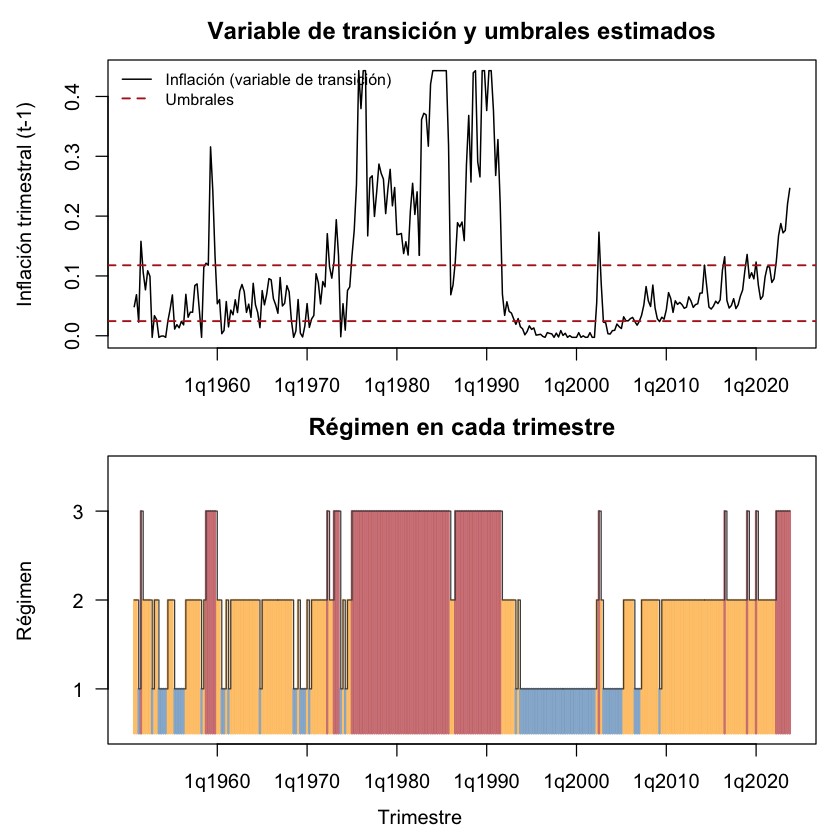

In [62]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar3_p2_cap")

## TVAR, 3 regímenes, p = 3

Se cargó exitosamente modelos preguardados  threshold_tvar_3_3_500_f213d0e1d4e80bfa86055ba87f06e192.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


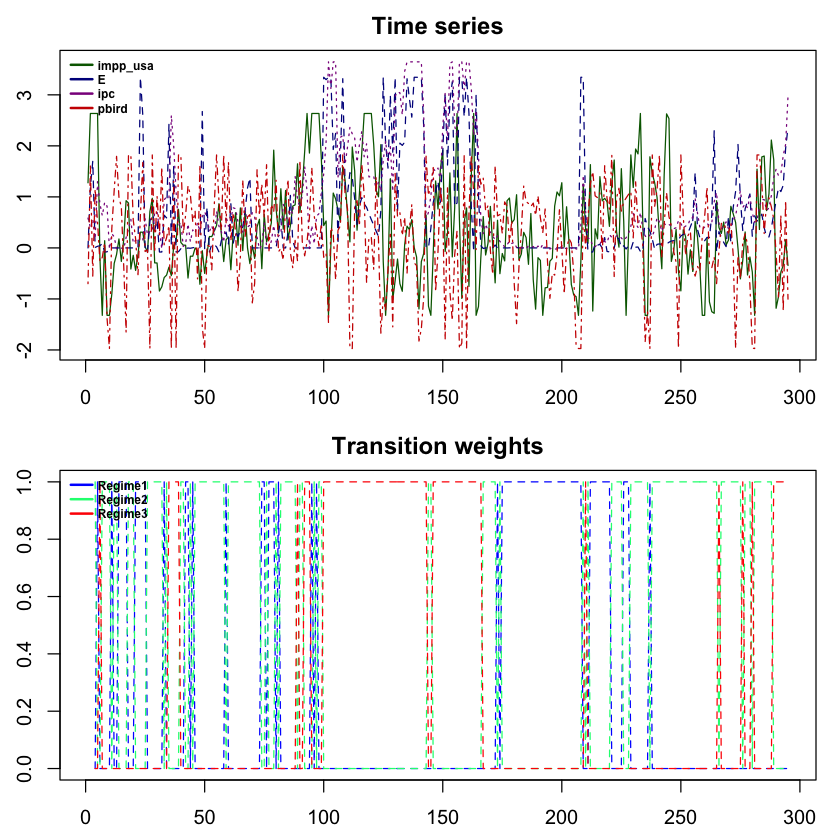

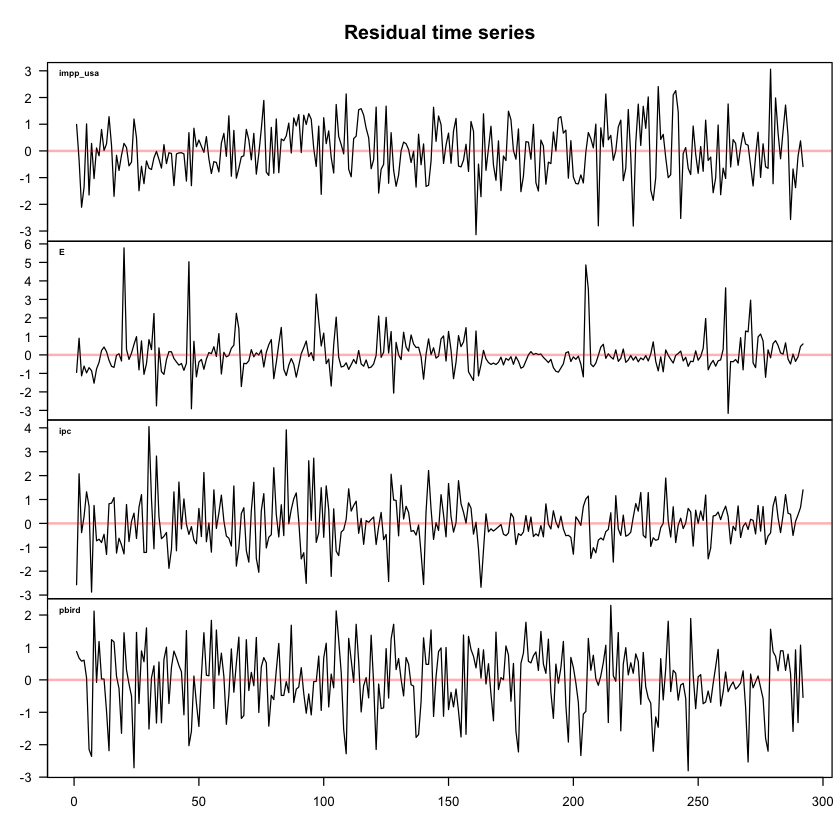

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



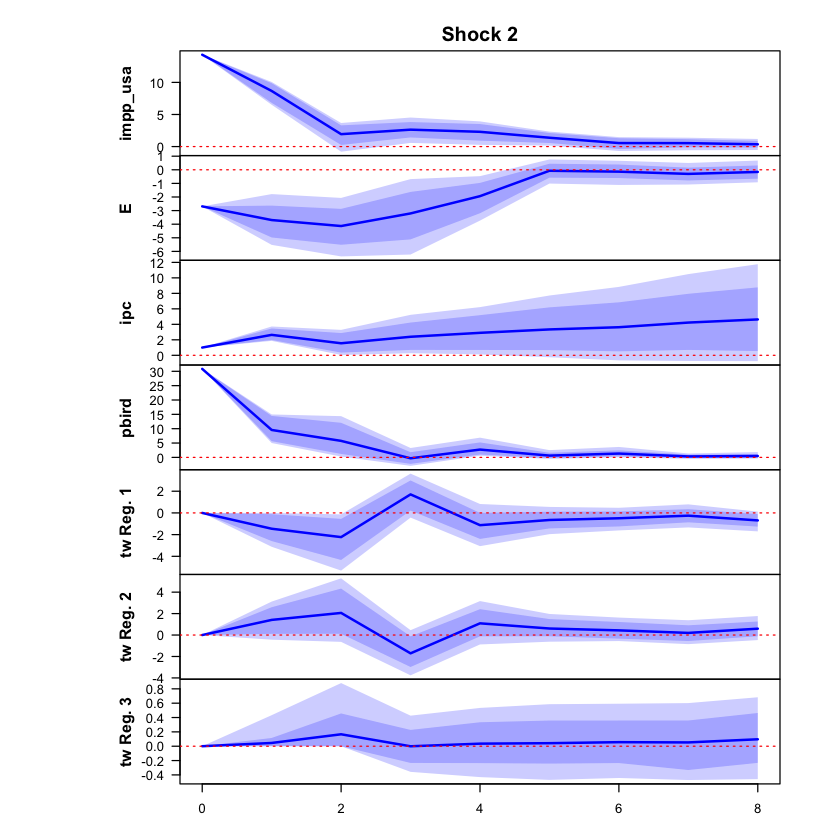

 >>> Linear IRF ( 1  shock units)


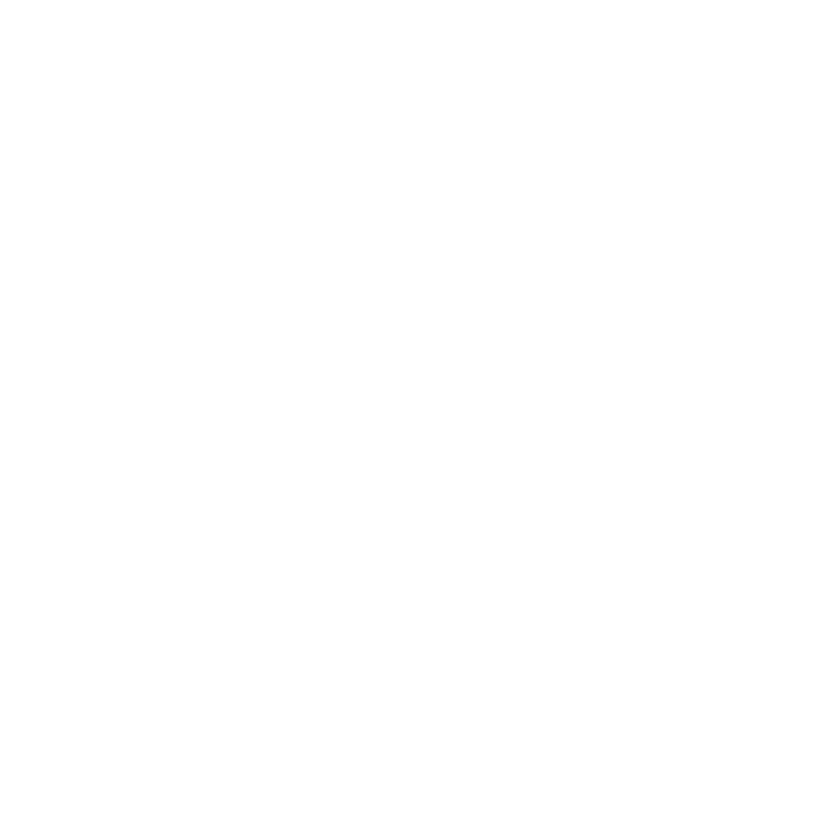

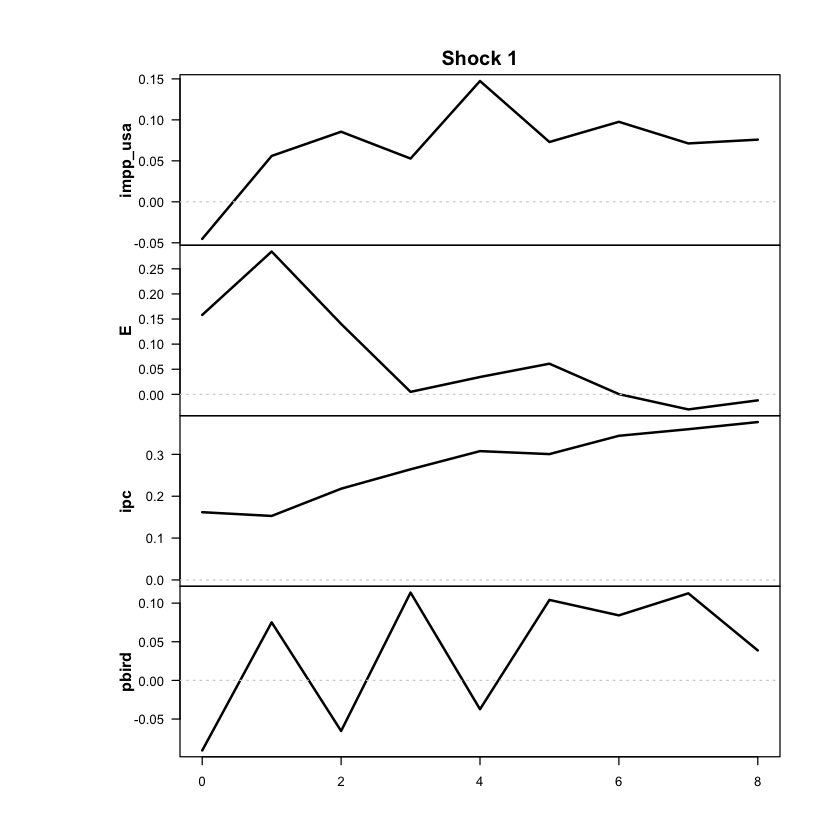

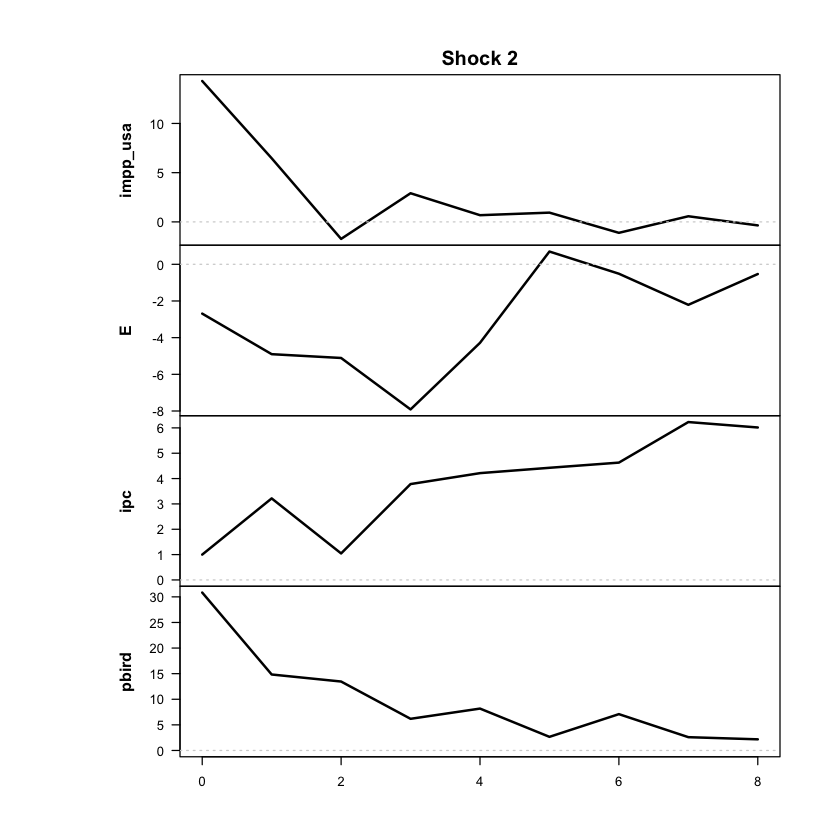

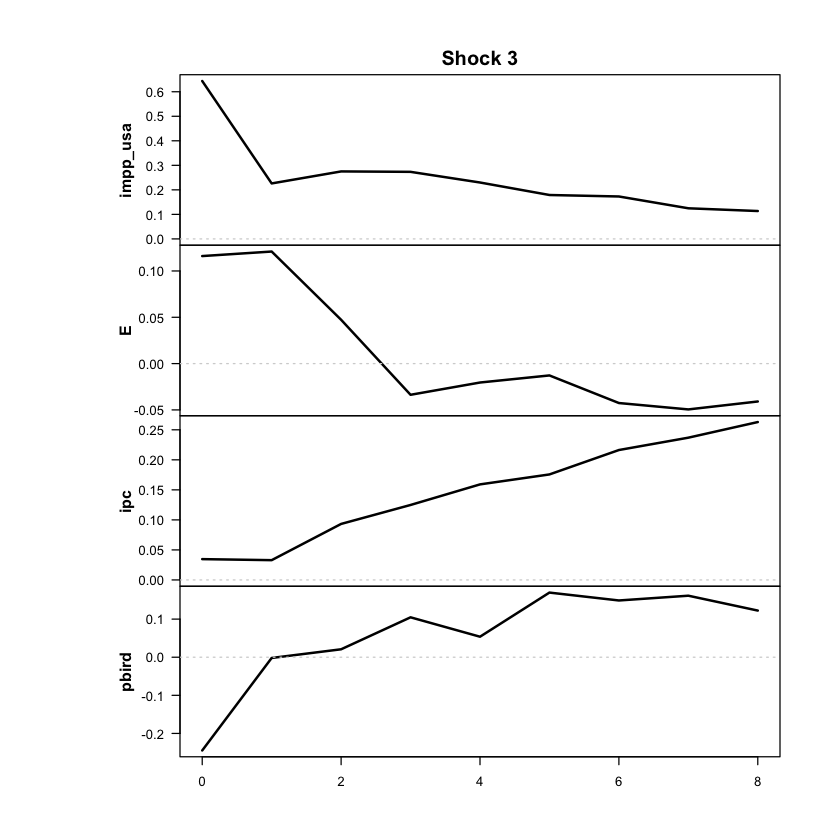

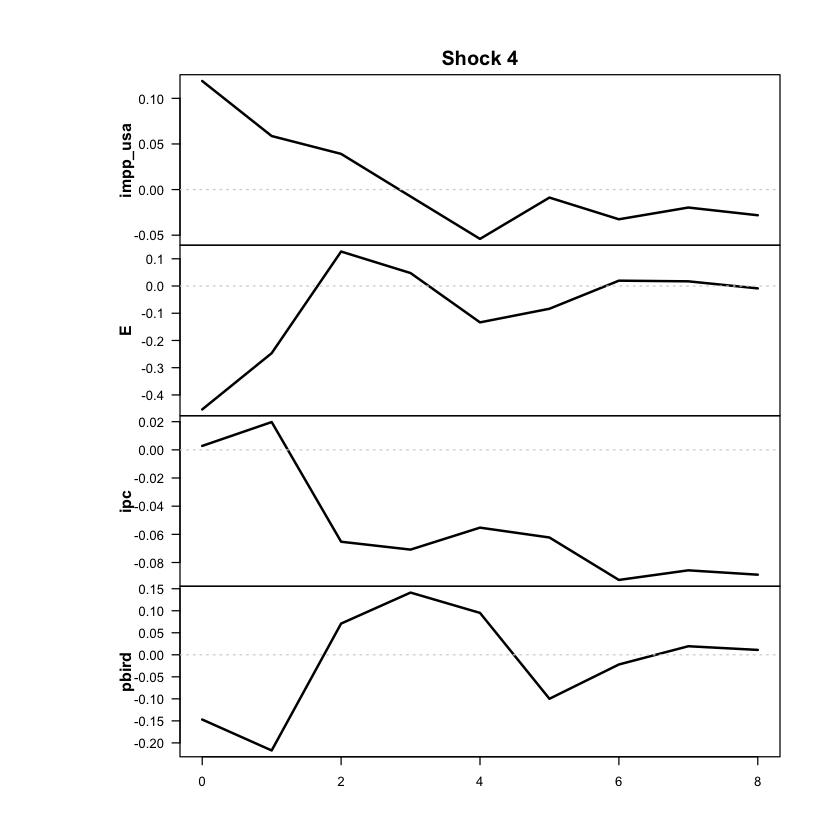

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



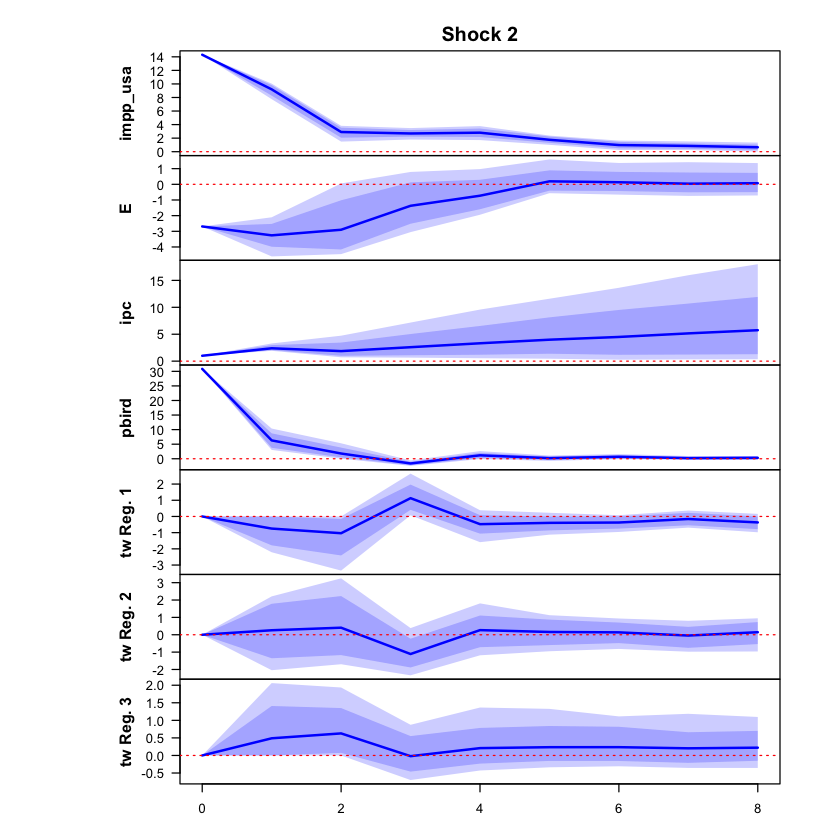

 >>> Linear IRF ( 1  shock units)


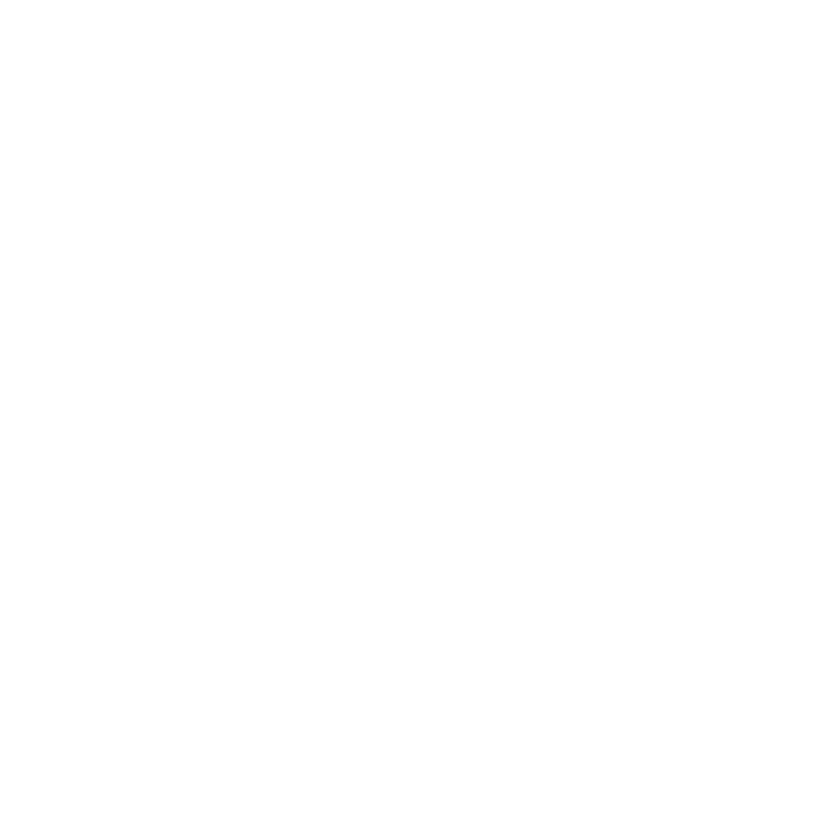

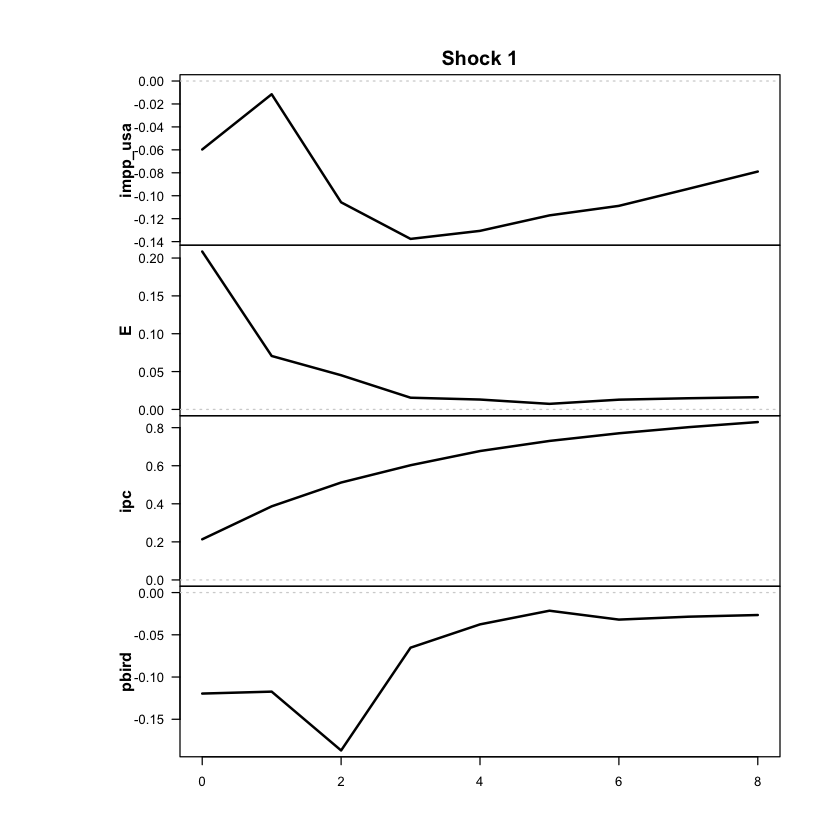

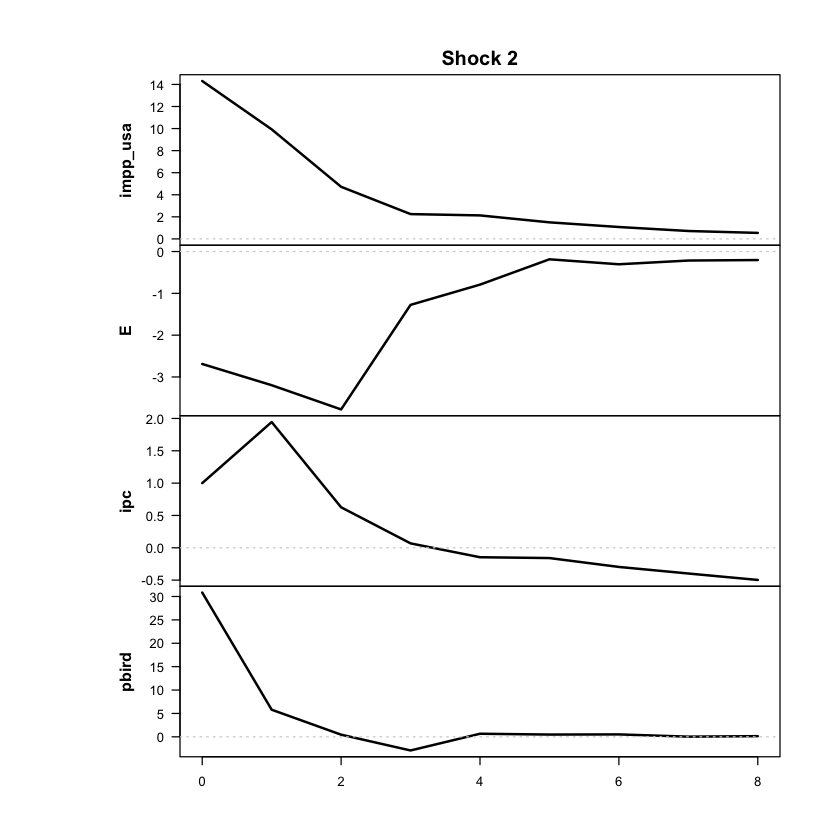

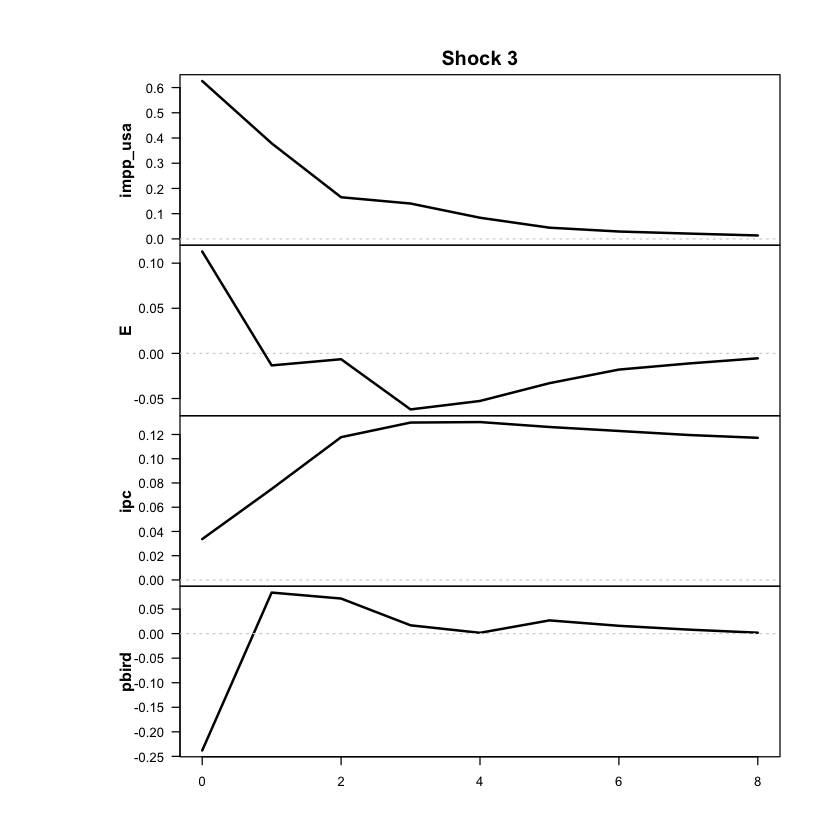

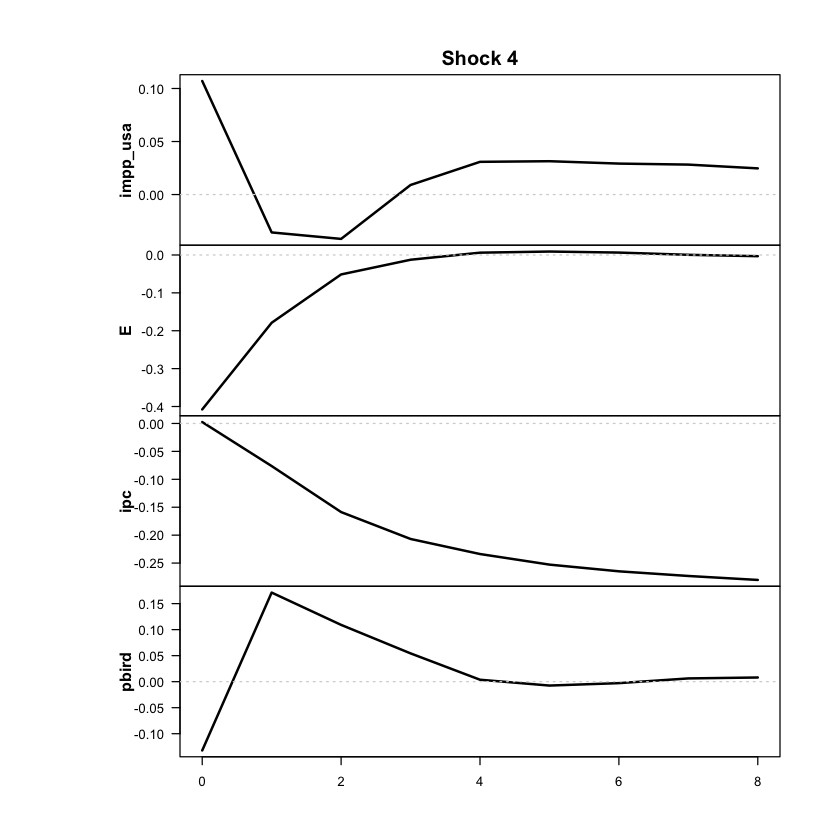

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



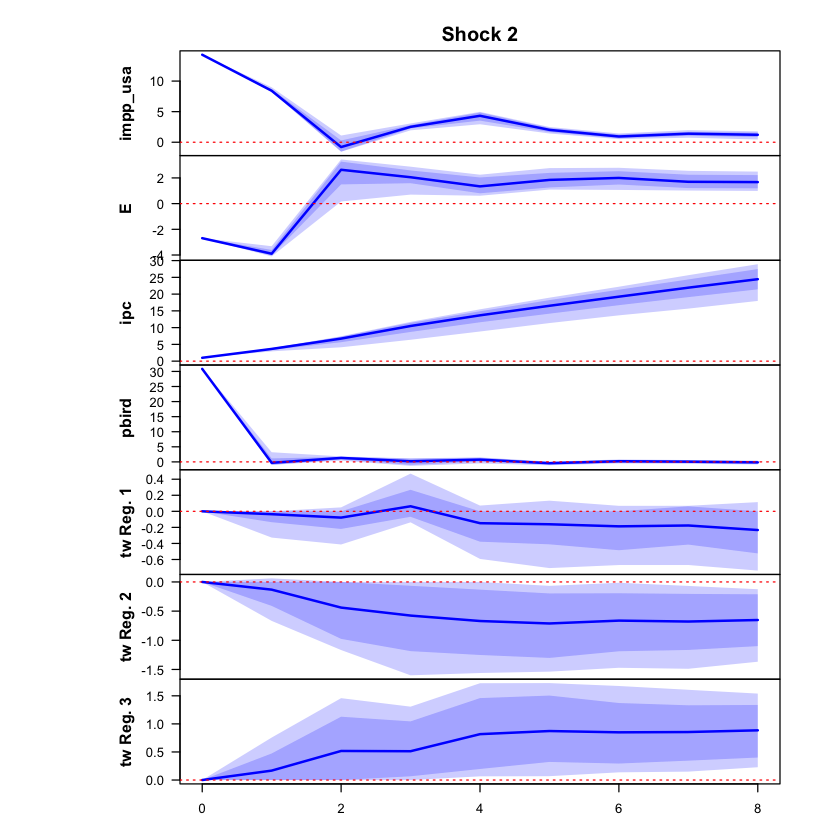

 >>> Linear IRF ( 1  shock units)


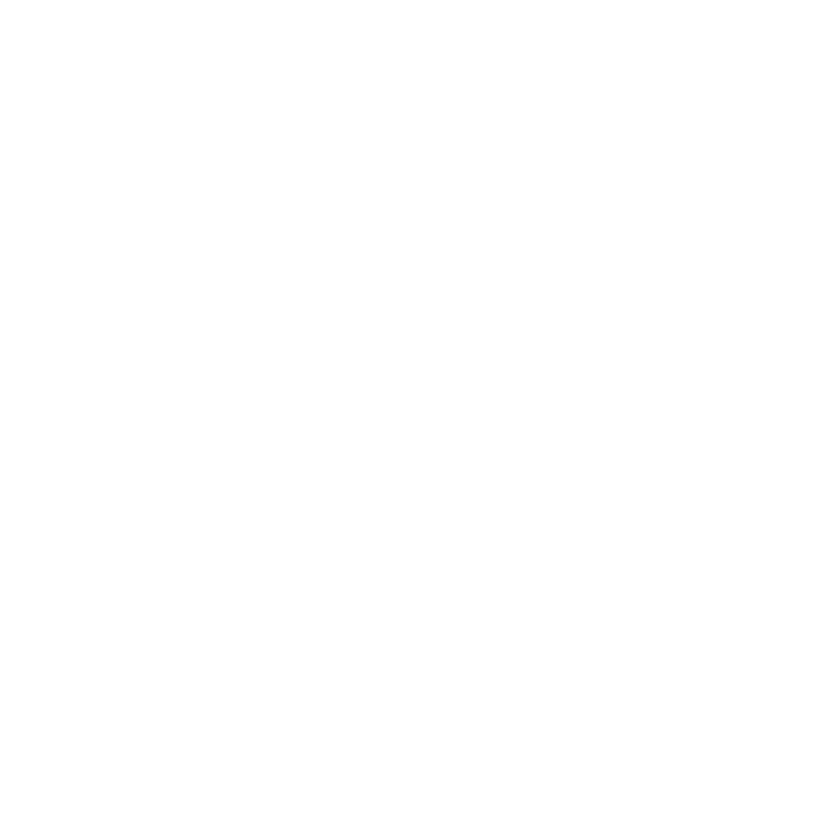

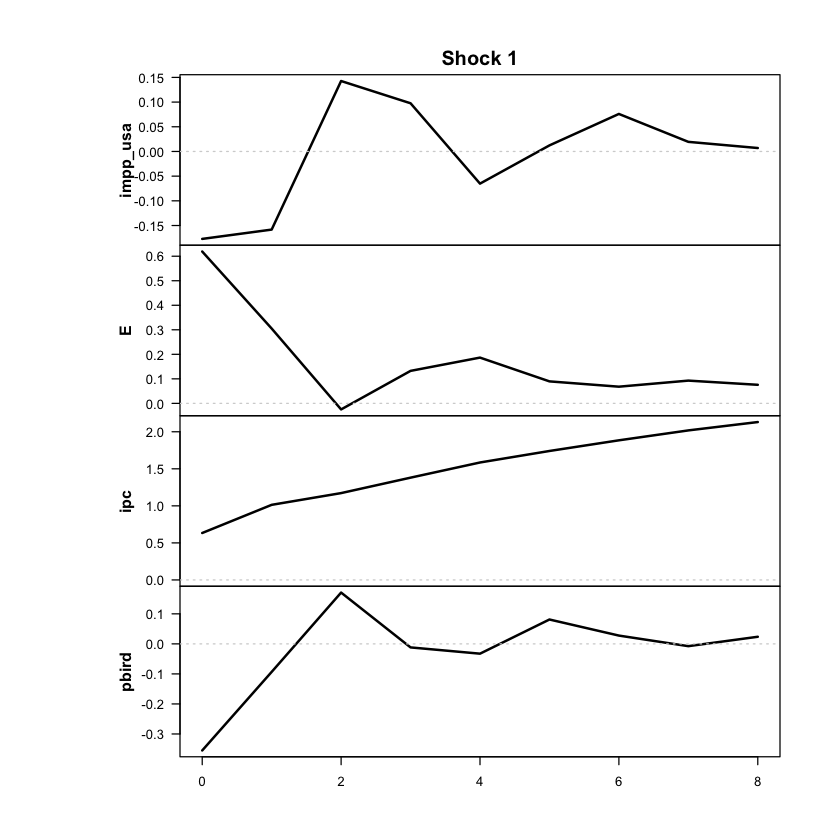

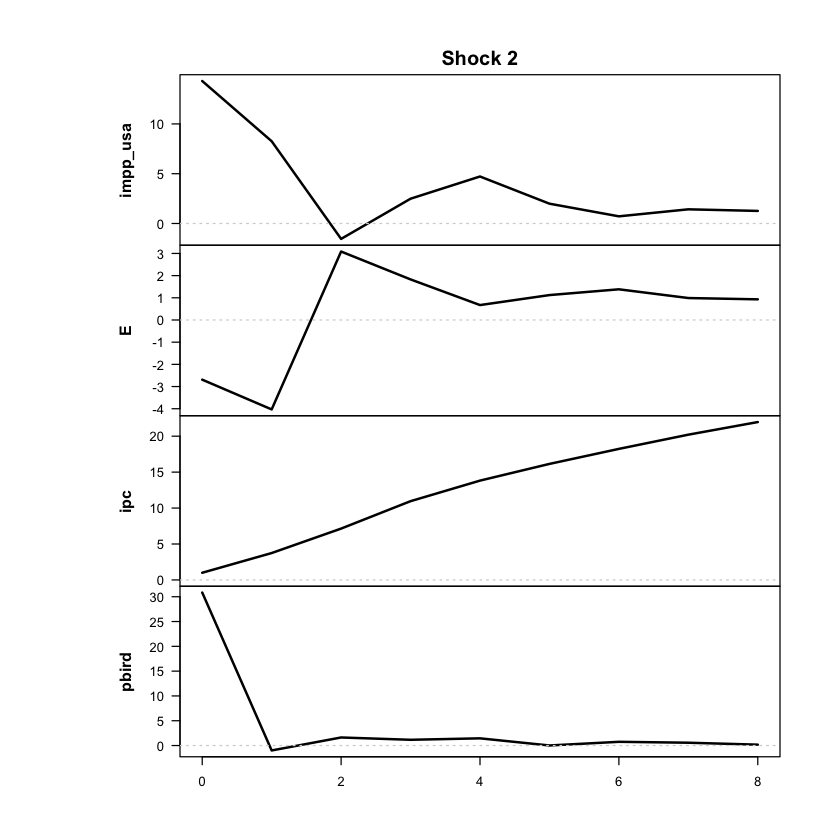

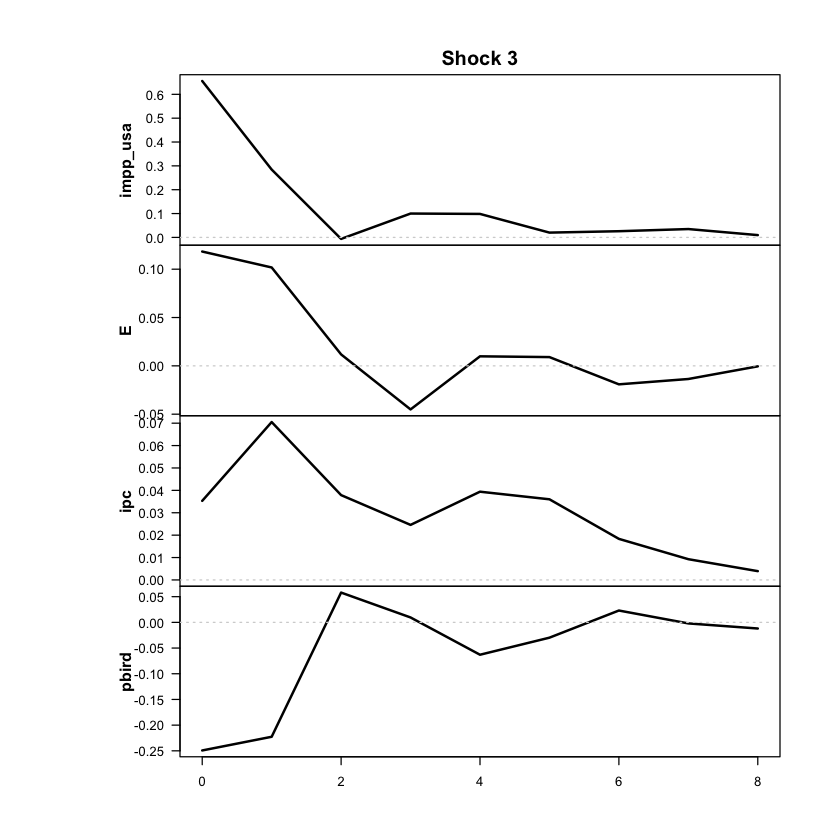

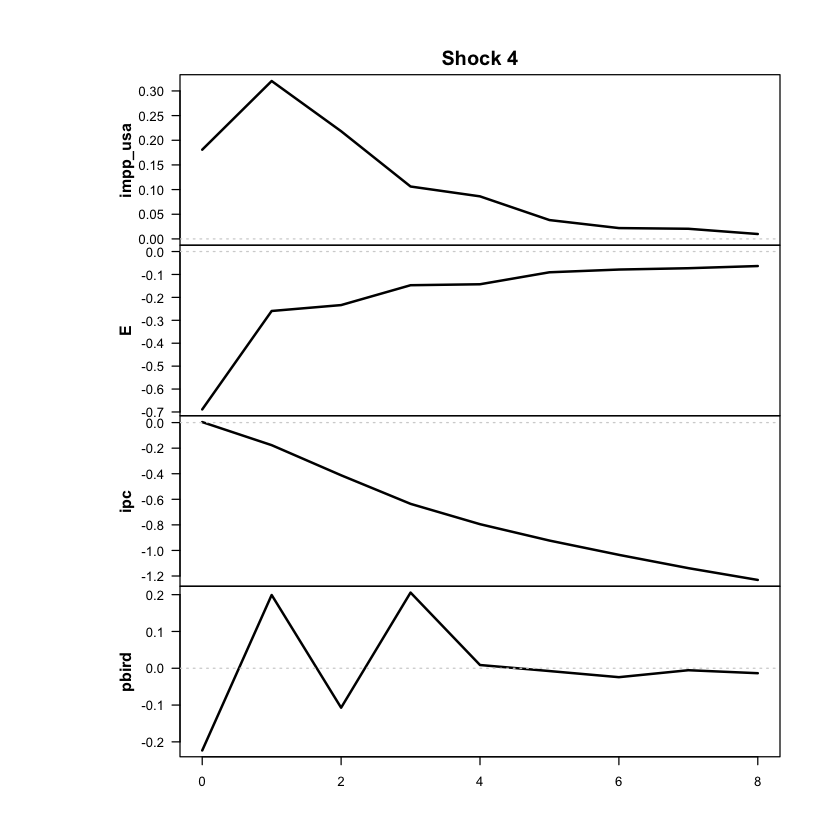

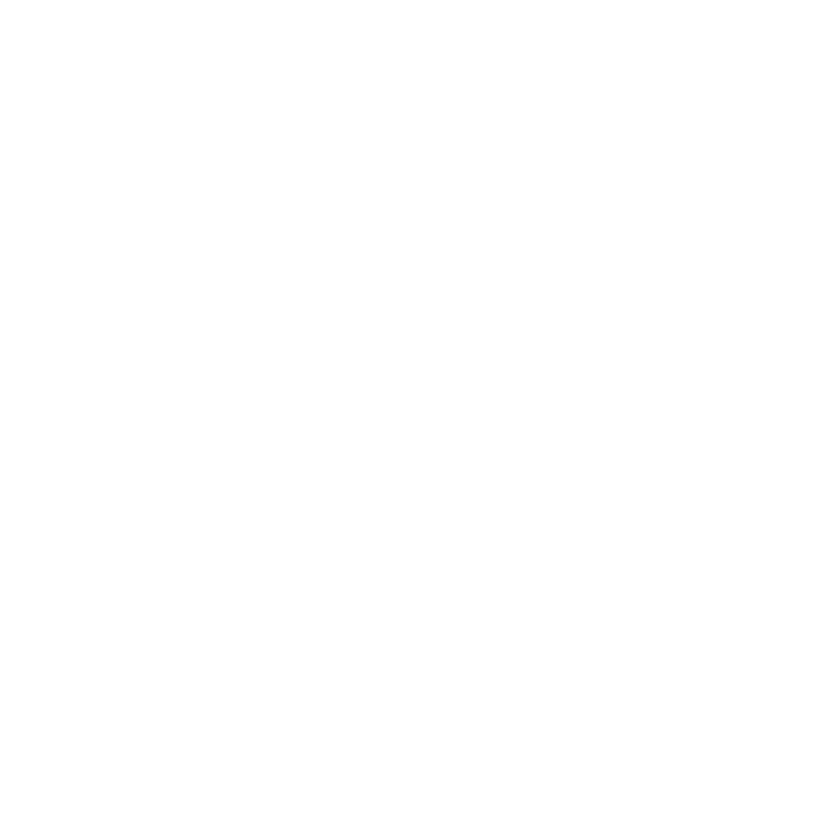

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 3,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [18]:
ic_tvar3_p3_cap <- criterios_info(res, "TVAR 3 reg p=3 cap")
print(ic_tvar3_p3_cap)

              modelo regimenes parametros  loglik    AIC     HQ    BIC
1 TVAR 3 reg p=3 cap         3        188 -931.19 2238.4 2515.3 2929.6


In [19]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 3 | rezagos: 3 | errores: Gaussian 
Umbrales: 2.5% trimestral (10% anualizada) | 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 72 | régimen 2 = 134 | régimen 3 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.46      0.59      1.02
E             2.36      4.66     27.25
ipc           1.88      6.35     29.68
pbird         0.69      0.91     -0.03


In [20]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -922.88      0.6 / 12.4    NA         NA        40/165/87
             2 -923.39      0.6 / 12.5    NA         NA        40/165/87
             3 -931.19      2.5 / 12.5    NA         NA        72/134/86
             4 -931.62      2.4 / 12.5    NA         NA        71/135/86
             5 -936.05      0.7 / 12.5    NA         NA        41/164/87
             6 -936.15      2.5 / 11.5    NA         NA        72/128/92
             7 -938.26      2.5 / 11.2    NA         NA        72/126/94
             8 -940.72     12.4 / 14.4    NA         NA        205/11/76
             9 -940

In [21]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 3, M = 3, d = 4, #parameters = 188, #observations = 292 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.20 
Regime means: 0.74, 0.33, 0.22, 0.46

   Y      phi0          A1                                 A2                  
1 y1 = [  0.06 ] + [  0.34 -0.05  0.50  0.03 ] y1.1 + [  0.18  0.12  0.28 -0.27
2 y2   [  0.20 ]   [ -0.03  0.59  1.10 -0.13 ] y2.1   [ -0.01 -0.46  0.34 -0.13
3 y3   [  0.04 ]   [  0.03 -0.05  0.03  0.05 ] y3.1   [  0.01  0.23  0.18 -0.10
4 y4   [ -0.09 ]   [  0.09  0.36  0.39  0.46 ] y4.1   [  0.12 -0.56 -0.59  0.14
                A3                              Omega                     1/2
1 ] y1.2 + [  0.19  0.05 -0.06  0.13 ] y1.3 + [  0.48  0.03  0.01 -0.02 ]    
2 ] y2.2   [ -0.10  0.12 -0.22  0.01 ] y2.3   [  0.03  0.27  0.04  0.01 ]    
3 ] y3.2   [  0.04 -0.09  0.13  0.10 ] y3.3   [  0.01  0.04  0.03 -0.01 ]    
4 ] y4.2   [  0.01 

In [65]:
shock_tvar3_p3_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar3_p3_cap <- 2
shock_tvar3_p3_cap

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa -0.0009  0.0049  0.0125  0.0023
  E         0.0242 -0.0072  0.0177 -0.0693
  ipc       0.0197  0.0021  0.0042  0.0003
  pbird    -0.0021  0.0127 -0.0057 -0.0034

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.64    0.08    0.17    0.92 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.814  -0.296   0.237  -0.005 

>>> Shock sugerido como cambiario: 4 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 4

### ERPT — tvar3 p3 cap

Correr solo si el modelo pasó el diagnóstico.

In [23]:
out_impp_usa_tvar3_p3_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p3_cap)

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 7.2%.



Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 72 | régimen 2 = 134 | régimen 3 = 86 
Shock usado:4| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0049        -0.0049        -0.0049
2         1         0.0367         0.1265         0.1938
3         2         0.1700         0.3048         0.4605
4         3         0.2411         0.4380         0.7223
5         4         0.2759         0.5399         0.9314
6         5         0.3138         0.6426         1.1220
7         6         0.3651         0.7373         1.3030
8         7         0.3990         0.8168         1.4790
9         8         0.4288         0.8964         1.6454

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0049       -0.0049       -0.0049
2         1        0.0249        0

In [24]:
out_impp_usa_tvar3_p3_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p3_cap,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 7.2%.

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 72 | régimen 2 = 134 | régimen 3 = 86 
Shock usado:4| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0049        -0.0049        -0.0049
2         1         0.0250         0.0876         0.1401
3         2         0.1154         0.1883         0.2665
4         3         0.1663         0.2465         0.3629
5         4         0.1761         0.2825         0.4142
6         5         0.1894         0.3197         0.4586
7         6         0.2189         0.3541         0.4958
8         7         0.2398         0.3805         0.5279
9         8         0.2548         0.4037         0.5565

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0049       -0.0049       -0.0049
2         1        0.0165        0

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 7.2%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!

GIRF del régimen 3...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 4...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0049  0.0498
         1  0.0694  0.0444
         2  0.2134  0.0032
         3  0.3021 -0.0251
         4  0.3545 -0.0332
         5  0.4140 -0.0248
         6  0.4784 -0.0207
         7  0.5291 -0.0205
         8  0.5754 -0.0207

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0049  0.0498
         1  0.1280  0.0051
         2  0.3076 -0.0362
         3  0.4471 -0.0701
         4  0.5574 -0.0782
         5  0.6672 -0.0750
         6  0.7700 -0.0730
         7  0.8632 -0.0736
         8  0.9527 -0.0743

+++ Régimen 3 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0049  0.0498
         1  0.1957  0.0053
         2  0.4657  0.0156
         3  0.7316 -0.0348
         4  0.9453 -0.0445
         5

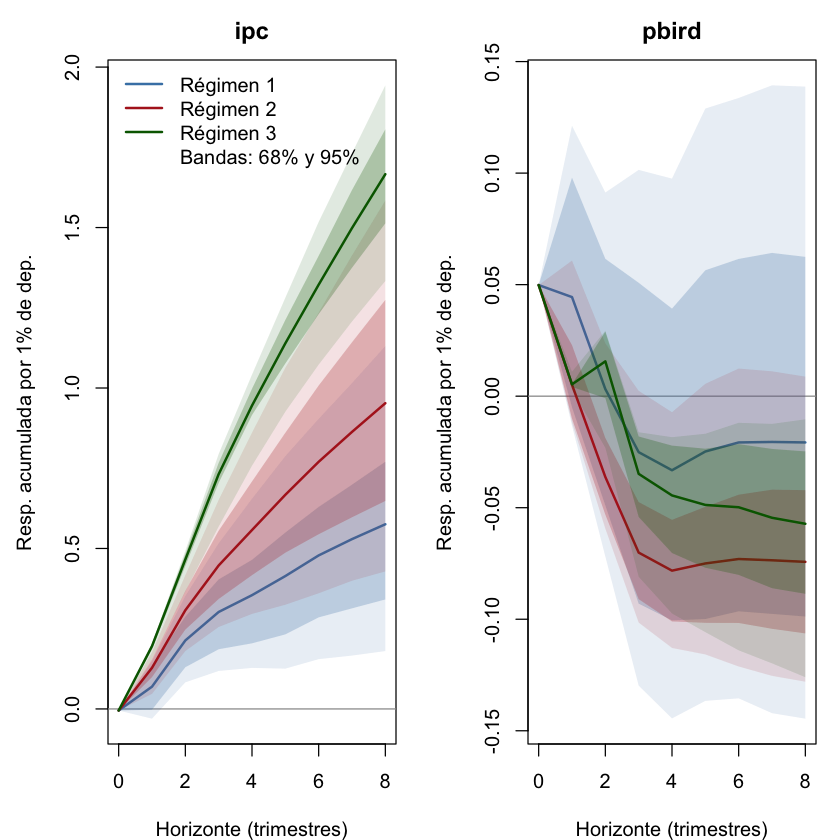

In [66]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                       shock_num = shock_tvar3_p3_cap, regimenes = 1:3,
                       archivo = "girf_original_impp_usa_tvar3_p3_cap")

In [67]:
ls(pattern = "^out_impp_usa_tvar3_p3_cap")
out_impp_usa_tvar3_p3_cap_acum$chequeo

[1] "out_impp_usa_tvar3_p3_cap"      "out_impp_usa_tvar3_p3_cap_acum"

horizonte,reg_1_original,reg_2_original,reg_3_original
<int>,<dbl>,<dbl>,<dbl>
0,-0.00489346,-0.00489346,-0.00489346
1,0.02502782,0.08764847,0.14006902
2,0.11538177,0.18828425,0.26646105
3,0.16633767,0.24651484,0.36293274
4,0.17607210,0.28245777,0.41416705
5,0.18941313,0.31966436,0.45856064
6,0.21891958,0.35411546,0.49580107
7,0.23978693,0.38047876,0.52793846
8,0.25475321,0.40372385,0.55650834


Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         4          0.176          0.282          0.414
Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         4          0.276           0.54          0.931


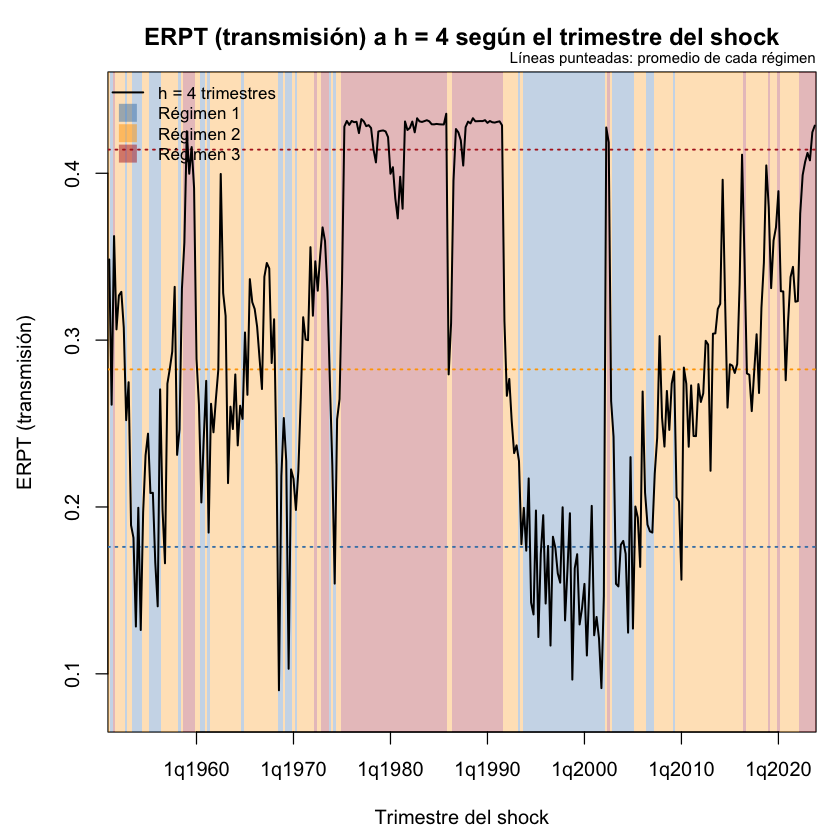

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         8          0.255          0.404          0.557


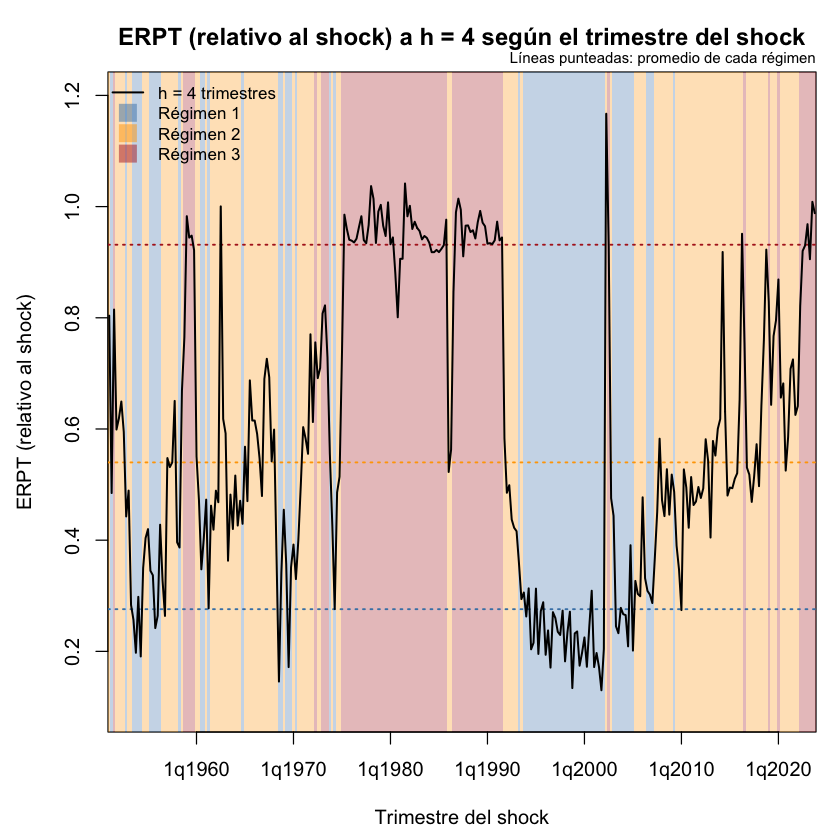

Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         8          0.429          0.896          1.645


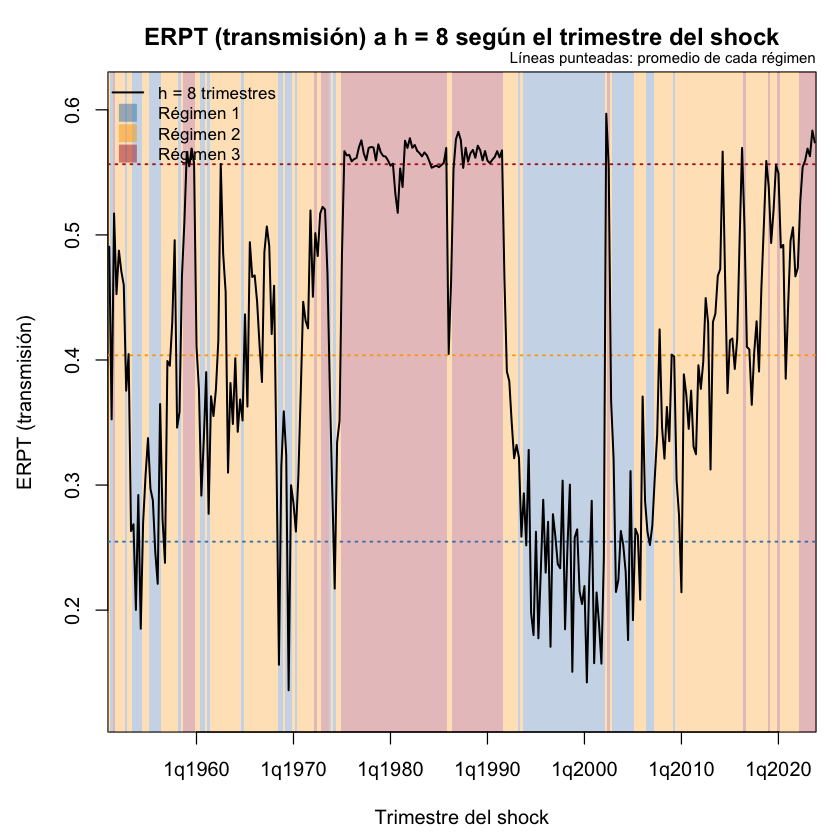

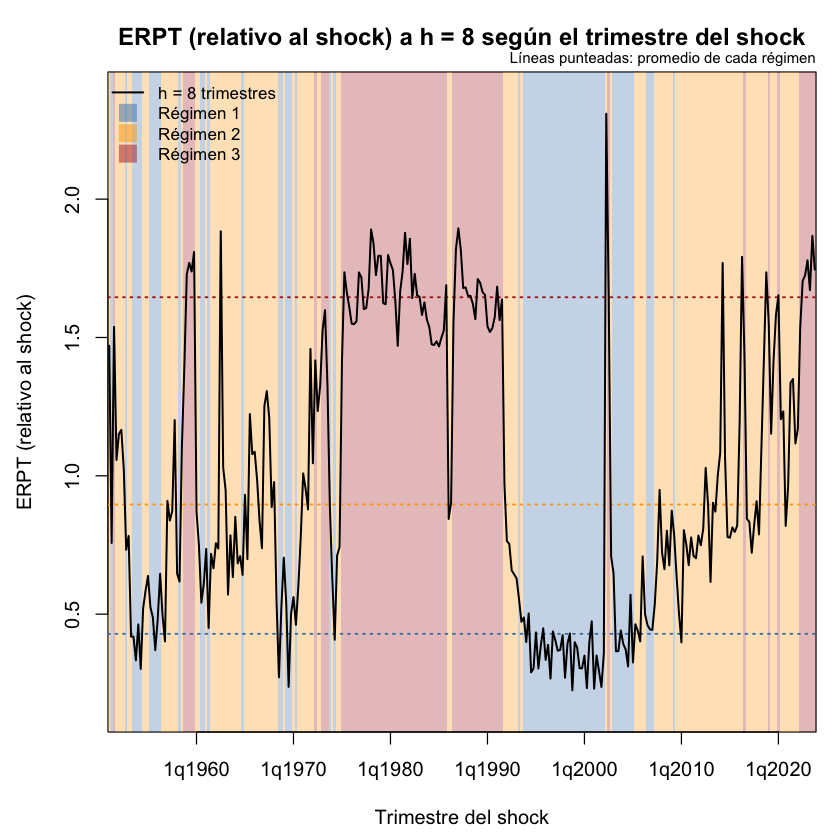

In [68]:
for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(out_impp_usa_tvar3_p3_cap_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p3_cap_acum_h", h))
  graficar_erpt_2d_bandas(out_impp_usa_tvar3_p3_cap, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p3_cap_h", h))
}

Umbrales (inflación trimestral de t-1): 2.5% trimestral (10% anualizada) | 12.5% trimestral (60% anualizada) 
Trimestres por régimen: régimen 1 = 72 | régimen 2 = 134 | régimen 3 = 86 


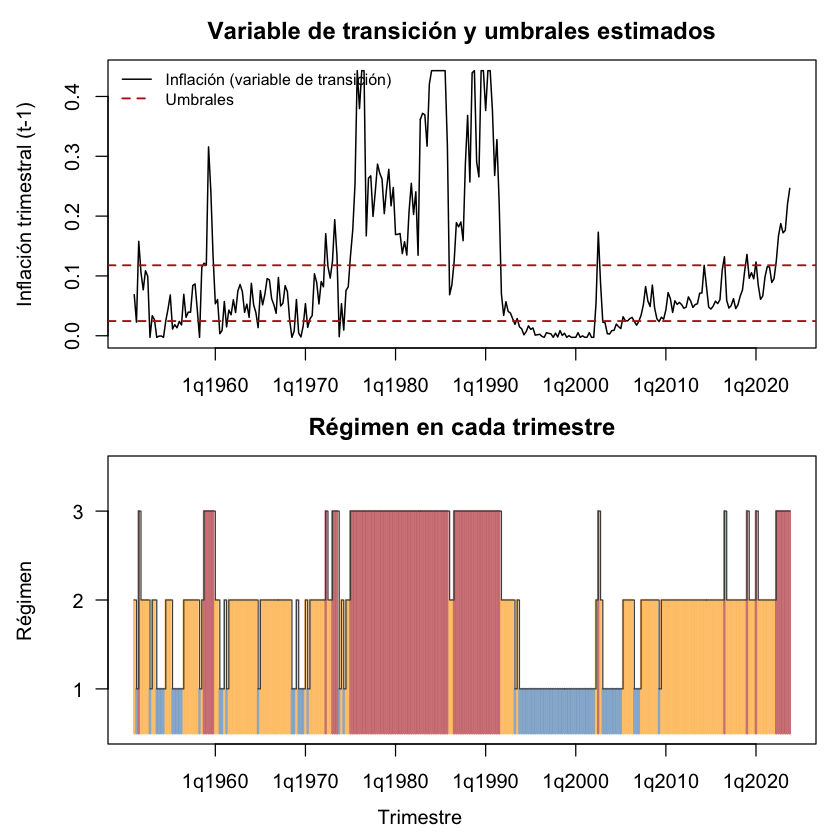

In [69]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar3_p3_cap")

## Comparación de criterios (con cappeo)

Solo son comparables entre sí los modelos estimados con los mismos datos: no comparar estos criterios con los de las notebooks sin cappeo.

In [54]:
rbind(ic_tvar_p1_cap, ic_tvar_p2_cap, ic_tvar_p3_cap, ic_vlstar_p2_cap, ic_vlstar_p3_cap, ic_tvar3_p2_cap, ic_tvar3_p3_cap)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=1 cap,2,61,-1051.18,2224.4,2314.4,2449.1
TVAR p=2 cap,2,93,-1024.31,2234.6,2371.7,2576.9
TVAR p=3 cap,2,125,-992.51,2235.0,2419.1,2694.6
VLSTAR p=2 cap,2,94,-1031.50,2251.0,2389.5,2596.9
VLSTAR p=3 cap,2,126,-999.68,2251.4,2436.9,2714.6
TVAR 3 reg p=2 cap,3,140,-972.88,2225.8,2432.1,2741.0
TVAR 3 reg p=3 cap,3,188,-931.19,2238.4,2515.3,2929.6


In [53]:
ls(pattern = "^ic_")

[1] "ic_tvar_p1_cap"   "ic_tvar_p2_cap"   "ic_tvar_p3_cap"   "ic_tvar3_p2_cap" 
[5] "ic_tvar3_p3_cap"  "ic_vlstar_p2_cap" "ic_vlstar_p3_cap"

# Test de Portmanteau (modelos con cappeo e impp_usa)

In [55]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd != "Gaussian") tipo <- paste0(tipo, "-t")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_cap <- portmanteau_guardados(df_ERPT_Arg_capped)
port_impp_cap <- port_cap[port_cap$commodity == "impp_usa", ]
print(port_impp_cap, row.names = FALSE)

 commodity modelo regimenes rezagos rezagos_test p_autocorr p_heterosc
  impp_usa MLOGIT         3       2            8      0.000      0.000
  impp_usa MLOGIT         3       2           12      0.000      0.000
  impp_usa MLOGIT         3       3            8      0.000      0.000
  impp_usa MLOGIT         3       3           12      0.000      0.000
  impp_usa   TVAR         2       1            8      0.001      0.000
  impp_usa   TVAR         2       1           12      0.008      0.000
  impp_usa   TVAR         2       2            8      0.001      0.000
  impp_usa   TVAR         2       2           12      0.025      0.000
  impp_usa   TVAR         2       3            8      0.002      0.000
  impp_usa   TVAR         2       3           12      0.070      0.000
  impp_usa   TVAR         3       2            8      0.001      0.002
  impp_usa   TVAR         3       2           12      0.027      0.004
  impp_usa   TVAR         3       3            8      0.001      0.001
  impp